# Descriptive and Exploratory Data Analysis
 This will serve as the baseline for a later validation of the model

## Manifest Overview

In [1]:
from enum import unique
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import ast
import matplotlib.ticker as mtick

from src.DescAnalysis import *
from matplotlib.lines import Line2D
from datetime import datetime
from zoneinfo import ZoneInfo
from src.DataPreparation import *
from src.DataSplitting import *

In [33]:
manifest = pd.read_csv(r"../data/manifests/realized_manifest_cleaned.csv", index_col=0)
#manifest = pd.read_parquet(r"../Ch_1_Data_Preparation/run_20261010/manifest_planned.parquet")
#manifest["n_persons"] = manifest["n_persons"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
#manifest["n_persons_sum"] = manifest["n_persons"].apply(sum)

manifest_dedup = manifest.drop_duplicates(["building_id"])

#manifest["n_appliances"] = manifest["appliances_unique"].map(lambda s: len(ast.literal_eval(s)) if isinstance(s, str) else len(s))

In [3]:
# todo look into a 3d plot for timeseries

In [6]:
tset = pd.read_hdf(r"C:\Users\Samuel\FH_Aachen\MasterThesis\Master_Thesis_EWI_2026\DataSplit\Data\train\run_012627.h5", key="timeseries")

In [7]:
params = pd.read_hdf(r"C:\Users\Samuel\FH_Aachen\MasterThesis\Master_Thesis_EWI_2026\DataSplit\Data\train\run_009818.h5", key="params")
params

,country,buildingType,surrounding,buildingAgeBin,a_ref,n_apartments,year_type,future,climateRegion,n_persons,...,resolved_climateRegion,resolved_latitude,resolved_longitude,state_seed,apartment_seeds,appliances,maxLoadViolation_kW,runtime_seconds,resolved_year,a0
0,DE,SFH,Semi,DE.08,261.817,1,hot,False,15,[1],...,15,47.702,10.7647,1009818,[280986],"[[""FRIDGE_FREEZER"", ""FRIDGE"", ""UPRIGHT_FREEZER...",1.059301e-10,56.871206,2023,150.205


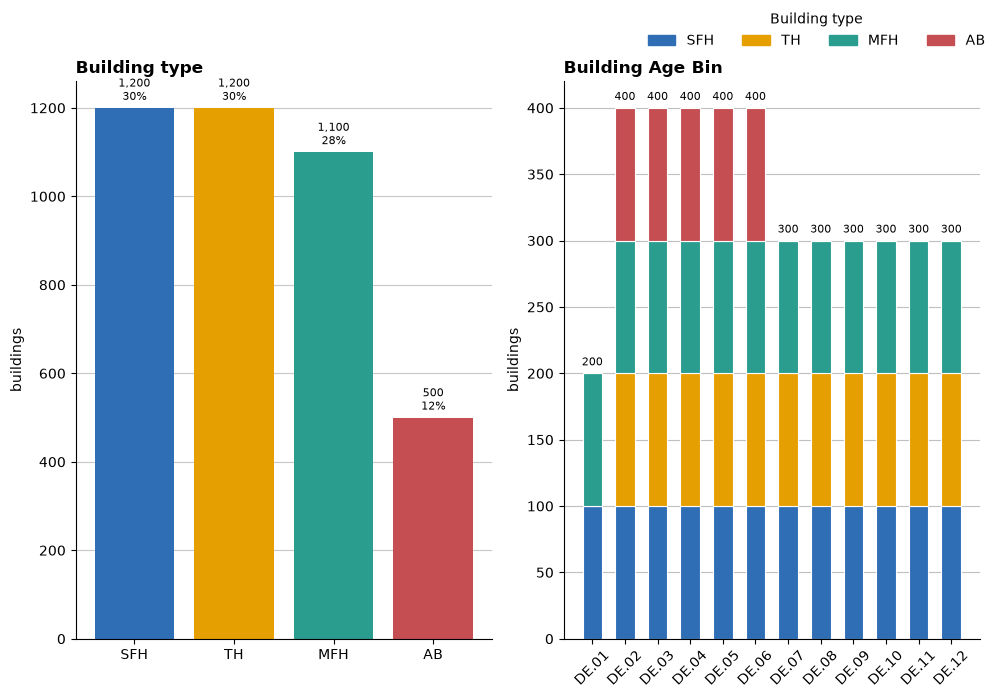

In [8]:
plot_manifest_static_building(manifest_dedup)

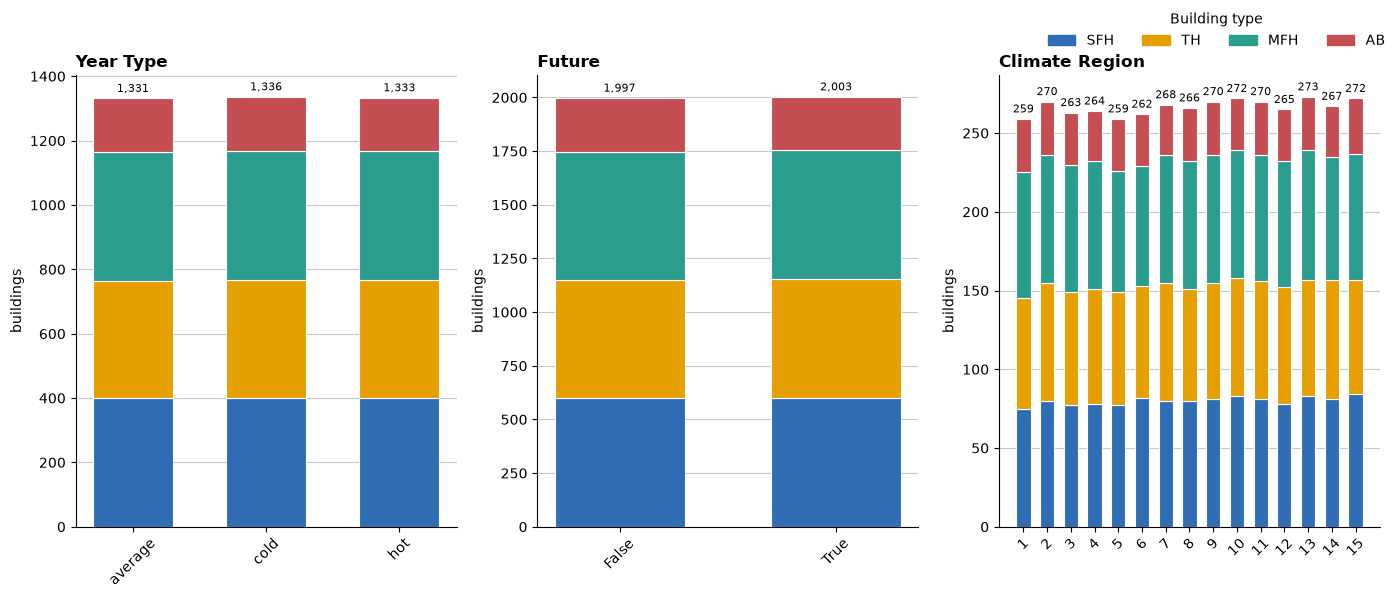

In [9]:
plot_manifest_static_weather(manifest_dedup)

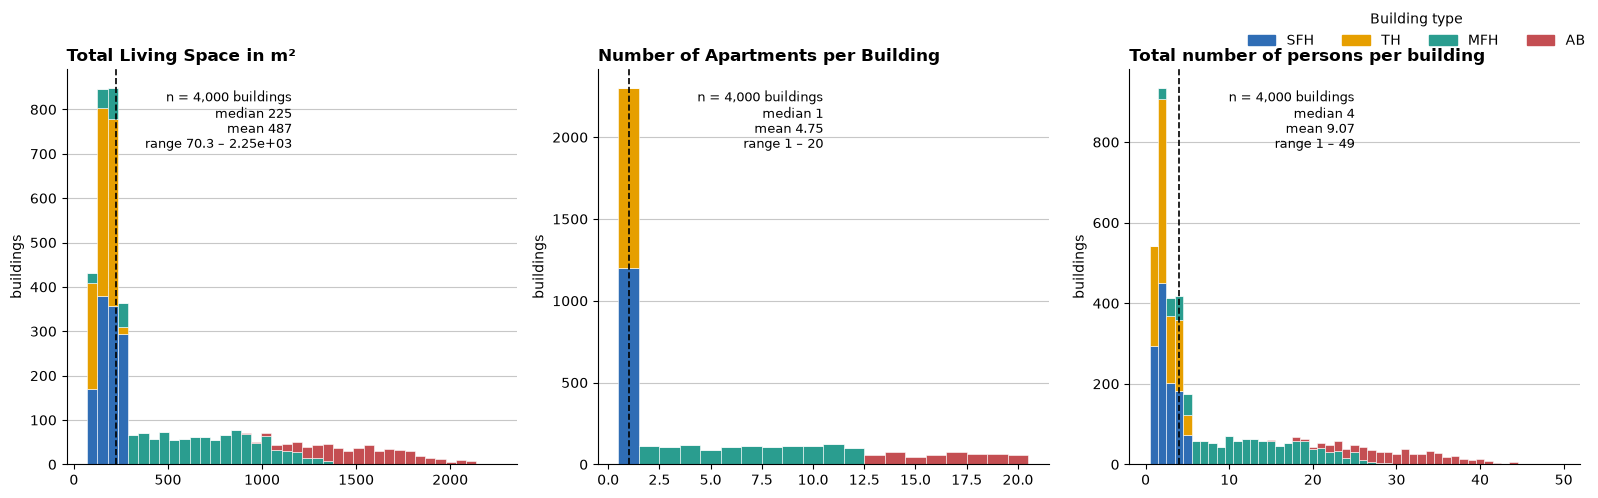

In [10]:
plot_manifest_numeric(manifest_dedup)

appliance
WASHER_DRYER       0.153408
CHEST_FREEZER      0.163528
TV3                0.177320
FAX                0.198100
UPRIGHT_FREEZER    0.290023
DISH_WASHER        0.332583
TUMBLE_DRYER       0.416742
FRIDGE             0.429126
HOB                0.466251
TV2                0.581323
OVEN               0.613276
FRIDGE_FREEZER     0.651559
PRINTER            0.661797
PC                 0.709411
WASHING_MACHINE    0.783121
MICROWAVE          0.858502
VCR_DVD            0.897193
IRON               0.898246
ANSWER_MACHINE     0.899404
CD_PLAYER          0.900009
CLOCK              0.900536
HIFI               0.900694
PHONE              0.901194
RECEIVER           0.933081
VACUUM             0.936700
KETTLE             0.975601
TV1                0.978167
SMALL_COOKING      1.000000
dtype: float64

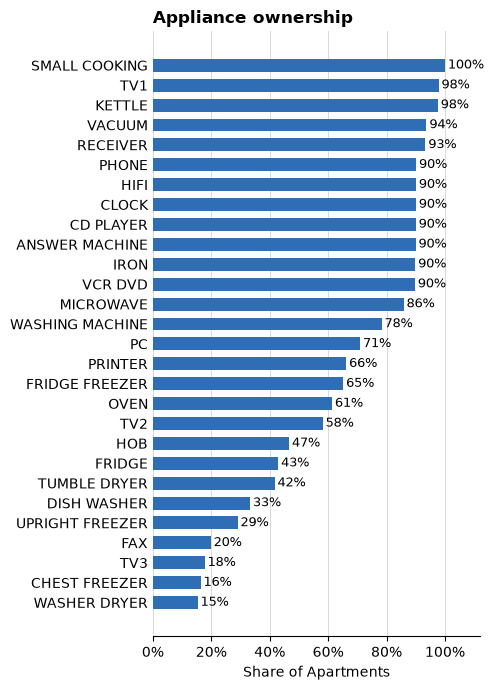

In [11]:
plot_appliance_ownership_total(manifest)

## General Overview and Assesment of Realism of Energydemands

In [174]:
manifest

,country,buildingType,surrounding,buildingAgeBin,a_ref,n_apartments,year_type,future,climateRegion,n_persons,freq,hasFirePlace,varyoccupancy,mean_load,nightReduction,capControl,occControl,comfortT_lb,comfortT_ub,cores,useCache,year,seed,weatherFilepath,weatherID,resolved_climateRegion,resolved_latitude,resolved_longitude,state_seed,apartment_seeds,appliances,maxLoadViolation_kW,runtime_seconds,resolved_year,a0,n_persons_sum,appliances_unique,building_id,run_id
i64,str,str,str,str,f64,i64,str,bool,i64,str,str,bool,i64,bool,bool,bool,bool,f64,f64,i64,bool,i64,i64,str,str,i64,f64,f64,i64,str,str,f64,f64,i64,f64,i64,str,i64,str
0,"""DE""","""AB""","""Terraced""","""DE.02""",1340.909,14,"""average""",true,5,"""[2, 2, 1, 4, 1, 1, 2, 1, 3, 3,…","""1min""",false,1,false,true,true,false,21.0,24.0,1,false,2018,1000000,"""/home/ss7446s@ad.fh-aachen.de/…","""TRY2045_5_average_TRY2045_5073…",5,50.731,7.117,1000000,"""[1341242, 2161857, 7980730, 31…","""[['UPRIGHT_FREEZER', 'ANSWER_M…",1.1998e-12,499.11565,2018,829.4,28,"""['UPRIGHT_FREEZER', 'ANSWER_MA…",0,"""run_000000"""
1,"""DE""","""AB""","""Terraced""","""DE.02""",1340.909,14,"""average""",true,5,"""[2, 2, 1, 4, 1, 1, 2, 1, 3, 3,…","""1min""",false,1,false,true,true,false,21.0,24.0,1,false,2021,1000001,"""/home/ss7446s@ad.fh-aachen.de/…","""TRY2045_5_average_TRY2045_5146…",5,51.4611,6.5494,1000001,"""[7816614, 6767105, 9804180, 77…","""[['FRIDGE_FREEZER', 'FRIDGE', …",7.8239e-12,510.517424,2021,829.4,28,"""['FRIDGE_FREEZER', 'FRIDGE', '…",0,"""run_000001"""
2,"""DE""","""AB""","""Terraced""","""DE.02""",1340.909,14,"""average""",true,5,"""[2, 2, 1, 4, 1, 1, 2, 1, 3, 3,…","""1min""",false,1,false,true,true,false,21.0,24.0,1,false,2023,1000002,"""/home/ss7446s@ad.fh-aachen.de/…","""TRY2045_5_average_TRY2045_5108…",5,51.0881,6.2367,1000002,"""[5393235, 3905184, 5287101, 23…","""[['FRIDGE', 'ANSWER_MACHINE', …",4.6079e-11,516.50585,2023,829.4,28,"""['FRIDGE', 'ANSWER_MACHINE', '…",0,"""run_000002"""
3,"""DE""","""AB""","""Terraced""","""DE.02""",1340.909,14,"""average""",true,5,"""[2, 2, 1, 4, 1, 1, 2, 1, 3, 3,…","""1min""",false,1,false,true,true,false,21.0,24.0,1,false,2025,1000003,"""/home/ss7446s@ad.fh-aachen.de/…","""TRY2045_5_average_TRY2045_5251…",5,52.5147,7.3234,1000003,"""[4220299, 2206534, 5895420, 62…","""[['FRIDGE', 'ANSWER_MACHINE', …",8.7621e-12,511.170801,2025,829.4,28,"""['FRIDGE', 'ANSWER_MACHINE', '…",0,"""run_000003"""
4,"""DE""","""AB""","""Terraced""","""DE.02""",1728.922,18,"""average""",false,6,"""[2, 4, 2, 1, 1, 1, 1, 2, 1, 2,…","""1min""",false,1,false,true,true,false,21.0,24.0,1,false,2018,1000004,"""/home/ss7446s@ad.fh-aachen.de/…","""TRY2015_6_average_TRY2015_5087…",6,50.8715,8.0504,1000004,"""[5649322, 6969250, 429204, 900…","""[['CHEST_FREEZER', 'FRIDGE_FRE…",1.5743e-11,637.389653,2018,829.4,31,"""['CHEST_FREEZER', 'FRIDGE_FREE…",1,"""run_000004"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
15991,"""DE""","""TH""","""Semi""","""DE.12""",116.166,1,"""hot""",false,3,"""[3]""","""1min""",false,1,false,true,true,false,21.0,24.0,1,false,2025,1015995,"""/home/ss7446s@ad.fh-aachen.de/…","""TRY2015_3_hot_TRY2015_52273310…",3,52.2733,10.5384,1015995,"""[8387292]""","""[['FRIDGE', 'CD_PLAYER', 'CLOC…",2.4284e-12,57.692023,2025,195.8,3,"""['FRIDGE', 'CD_PLAYER', 'CLOCK…",3998,"""run_015995"""
15992,"""DE""","""TH""","""Semi""","""DE.12""",121.971,1,"""average""",false,12,"""[2]""","""1min""",false,1,false,true,true,false,21.0,24.0,1,false,2018,1015996,"""/home/ss7446s@ad.fh-aachen.de/…","""TRY2015_12_average_TRY2015_476…",12,47.6774,7.5552,1015996,"""[2521613]""","""[['FRIDGE_FREEZER', 'ANSWER_MA…",1.9494e-12,54.153805,2018,195.8,2,"""['FRIDGE_FREEZER', 'ANSWER_MAC…",3999,"""run_015996"""
15993,"""DE""","""TH""","""Semi""","""DE.12""",121.971,1,"""average""",false,12,"""[2]""","""1min""",false,1,false,true,true,false,21.0,24.0,1,false,2021,1015997,"""/home/ss7446s@ad.fh-aachen.de/…","""TRY2015_12_average_TRY2015_499…",12,49.9997,8.2

In [165]:
ts_agg_yearly = pd.read_csv("../data/manifests/checked_ts_yearly.csv", index_col=0)

In [166]:
ts_agg_yearly

,run_id,domain,sum_yearly,sum_yearly_per_occ,sum_yearly_per_a_ref,max,min,mean,p05,p10,...,load_factor,tou,tou_share,tou_winter,tou_winter_share,tou_summer,tou_summer_share,peaks_unocc,days_peak_unocc,share_peaks_unocc
0,run_000000,elec,38411.6840,1371.8458,28.646002,23.166935,5.770640e-01,4.384895,1.269887e+00,1.489535e+00,...,0.189274,38,0.073973,38,0.087912,40,0.092896,7,7,0.000381
1,run_000000,dhw,18877.3520,674.1911,14.078025,125.101170,0.000000e+00,2.154949,0.000000e+00,0.000000e+00,...,0.017226,17,0.136986,15,0.137363,17,0.180328,0,0,0.000000
2,run_000000,sh,105612.3100,3771.8684,78.761730,67.598590,1.213727e-11,12.056200,1.293895e-11,1.336891e-11,...,0.178350,18,0.202740,18,0.302198,48,0.142077,3,3,0.007075
3,run_000001,elec,38476.2030,1374.1501,28.694118,21.835150,5.958475e-01,4.392260,1.305250e+00,1.527516e+00,...,0.201155,39,0.098630,36,0.109890,39,0.098361,19,18,0.000946
4,run_000001,dhw,18912.9020,675.4608,14.104538,126.782510,0.000000e+00,2.159007,0.000000e+00,0.000000e+00,...,0.017029,17,0.136986,15,0.197802,17,0.196721,0,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47983,run_015998,dhw,1353.6754,676.8377,11.098338,61.692050,0.000000e+00,0.154529,0.000000e+00,0.000000e+00,...,0.002505,17,0.074380,15,0.083333,17,0.081967,0,0,0.000000
47984,run_015998,sh,5750.8950,2875.4475,47.149693,4.768198,8.953621e-13,0.656495,1.317155e-12,1.389302e-12,...,0.137682,16,0.153425,16,0.252747,14,0.071038,65,58,0.160891
47985,run_015999,elec,3422.4893,1711.2446,28.059860,6.975734,4.353590e-02,0.390695,4.421715e-02,4.659095e-02,...,0.056008,36,0.073973,36,0.082418,23,0.065574,0,0,0.000000
47986,run_015999,dhw,1355.0046,677.5023,11.109236,61.625122,0.000000e+00,0.154681,0.000000e+00,0.000000e+00,...,0.002510,17,0.099723,17,0.098901,17,0.100559,0,0,0.000000


In [167]:
ts_agg_daily = pd.read_csv("../data/manifests/checked_ts_daily.csv", index_col=0)

In [168]:
ts_agg_daily =ts_agg_daily.merge(manifest[["run_id", "buildingType", "buildingAgeBin", "n_persons_sum"]], how="left", on="run_id")
ts_agg_yearly =ts_agg_yearly.merge(manifest[["run_id", "buildingType", "buildingAgeBin", "n_persons_sum"]], how="left", on="run_id")

In [169]:
ts_agg_yearly_elec = ts_agg_yearly[ts_agg_yearly["domain"]=="elec"]
ts_agg_yearly_dhw = ts_agg_yearly[ts_agg_yearly["domain"]=="dhw"]
ts_agg_yearly_sh = ts_agg_yearly[ts_agg_yearly["domain"]=="sh"]
ts_agg_yearly_dhw

,run_id,domain,sum_yearly,sum_yearly_per_occ,sum_yearly_per_a_ref,max,min,mean,p05,p10,...,tou_winter,tou_winter_share,tou_summer,tou_summer_share,peaks_unocc,days_peak_unocc,share_peaks_unocc,buildingType,buildingAgeBin,n_persons_sum
1,run_000000,dhw,18877.3520,674.19110,14.078025,125.101170,0.0,2.154949,0.0,0.0,...,15,0.137363,17,0.180328,0,0,0.0,AB,DE.02,28
4,run_000001,dhw,18912.9020,675.46080,14.104538,126.782510,0.0,2.159007,0.0,0.0,...,15,0.197802,17,0.196721,0,0,0.0,AB,DE.02,28
7,run_000002,dhw,18905.4790,675.19570,14.099001,155.714520,0.0,2.158160,0.0,0.0,...,15,0.137363,17,0.174863,0,0,0.0,AB,DE.02,28
10,run_000003,dhw,18882.7100,674.38250,14.082022,140.259670,0.0,2.155560,0.0,0.0,...,15,0.186813,17,0.224044,0,0,0.0,AB,DE.02,28
13,run_000004,dhw,20891.7360,673.92700,12.083678,175.000170,0.0,2.384901,0.0,0.0,...,15,0.131868,17,0.218579,0,0,0.0,AB,DE.02,31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47974,run_015995,dhw,1996.3100,665.43670,17.184977,62.546910,0.0,0.227889,0.0,0.0,...,15,0.093407,17,0.147541,0,0,0.0,TH,DE.12,3
47977,run_015996,dhw,1339.8098,669.90490,10.984658,55.769917,0.0,0.152946,0.0,0.0,...,44,0.088889,45,0.103825,0,0,0.0,TH,DE.12,2
47980,run_015997,dhw,1339.9559,669.97797,10.985857,59.664124,0.0,0.152963,0.0,0.0,...,15,0.093407,17,0.087912,0,0,0.0,TH,DE.12,2
47983,run_015998,dhw,1353.6754,676.83770,11.098338,61.692050,0.0,0.154529,0.0,0.0,...,15,0.083333,17,0.081967,0,0,0.0,TH,DE.12,2


In [170]:
ts_agg_daily["max_per_occ"] = ts_agg_daily["max_avg"] /ts_agg_daily["n_persons_sum"]
ts_agg_daily["mean_per_occ"] = ts_agg_daily["mean_avg"] /ts_agg_daily["n_persons_sum"]
ts_agg_daily["mean_nz_per_occ"] = ts_agg_daily["mean_nz_avg"] /ts_agg_daily["n_persons_sum"]

In [171]:
ts_agg_daily_elec = ts_agg_daily[ts_agg_daily["domain"]=="elec"]
ts_agg_daily_dhw = ts_agg_daily[ts_agg_daily["domain"]=="dhw"]
ts_agg_daily_sh = ts_agg_daily[ts_agg_daily["domain"]=="sh"]
ts_agg_daily_dhw

,run_id,domain,day_type,max_avg,max_std,min_avg,min_std,mean_avg,mean_std,max_nz_avg,...,ramp_up_max_std,ramp_down_max_avg,ramp_down_max_std,active_days,buildingType,buildingAgeBin,n_persons_sum,max_per_occ,mean_per_occ,mean_nz_per_occ
3,run_000000,dhw,all,60.920390,17.146898,0.0,0.0,2.155147,0.686938,60.920390,...,12.638026,-46.206165,12.767482,365,AB,DE.02,28,2.175728,0.076970,0.616001
4,run_000000,dhw,weekday,60.839640,17.601942,0.0,0.0,2.047580,0.621908,60.839640,...,12.971069,-46.091976,13.499076,252,AB,DE.02,28,2.172844,0.073128,0.615590
5,run_000000,dhw,offday,61.100480,16.160368,0.0,0.0,2.395030,0.763383,61.100480,...,11.910447,-46.460820,11.013800,113,AB,DE.02,28,2.182160,0.085537,0.616919
12,run_000001,dhw,all,63.057228,18.587795,0.0,0.0,2.159130,0.674106,63.057228,...,12.711446,-46.502990,13.212072,365,AB,DE.02,28,2.252044,0.077112,0.618474
13,run_000001,dhw,weekday,62.514793,18.525274,0.0,0.0,2.061622,0.634230,62.514793,...,12.808937,-46.358330,13.729465,256,AB,DE.02,28,2.232671,0.073629,0.619819
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143950,run_015998,dhw,weekday,23.830349,8.746670,0.0,0.0,0.147398,0.123283,24.020992,...,7.582875,-23.073929,7.017202,250,TH,DE.12,2,11.915174,0.073699,6.809324
143951,run_015998,dhw,offday,25.021421,9.306885,0.0,0.0,0.170625,0.133077,25.021421,...,7.475986,-24.013817,8.126775,113,TH,DE.12,2,12.510711,0.085313,6.849050
143958,run_015999,dhw,all,23.861599,8.258871,0.0,0.0,0.154734,0.129934,24.125994,...,7.236113,-23.302034,7.189493,360,TH,DE.12,2,11.930799,0.077367,6.757554
143959,run_015999,dhw,weekday,23.708565,8.040811,0.0,0.0,0.154547,0.131196,23.994210,...,7.220351,-23.295122,7.254295,248,TH,DE.12,2,11.854283,0.077273,6.849085


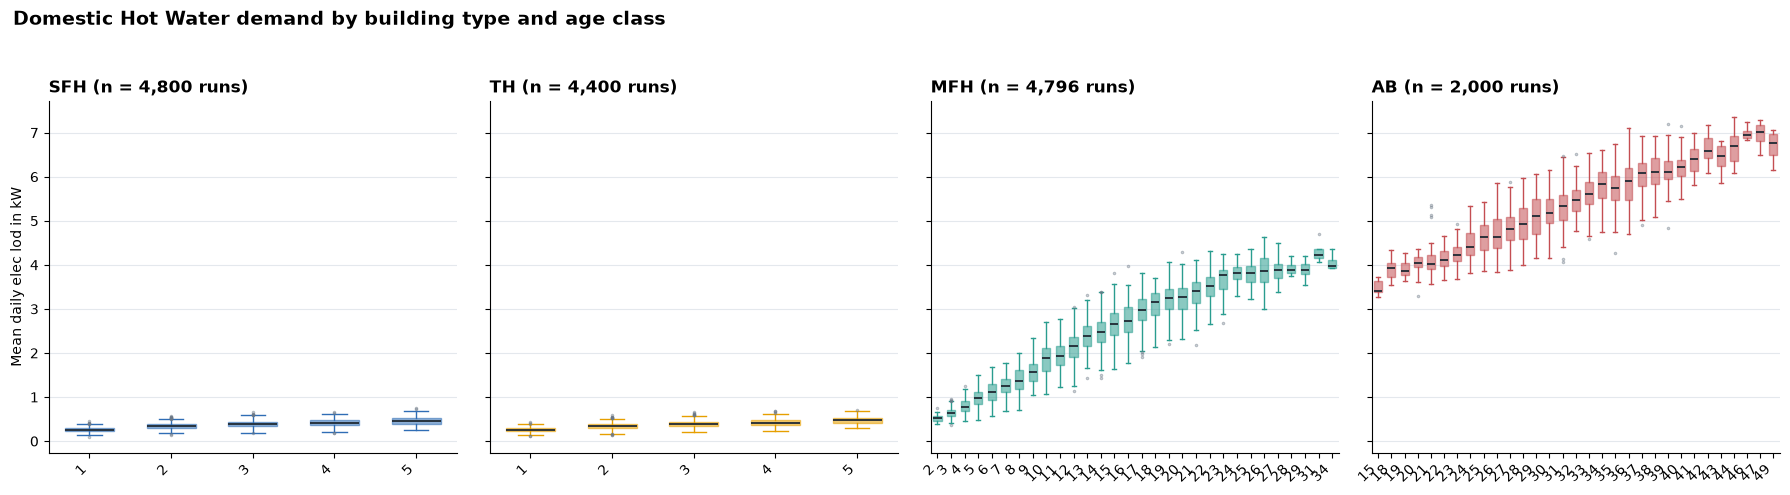

In [160]:
boxplot_specific_energy(ts_agg_daily_elec[ts_agg_daily_elec["day_type"]=="all"], "mean_avg",ylabel="Mean daily elec lod in kW", param="n_persons_sum")

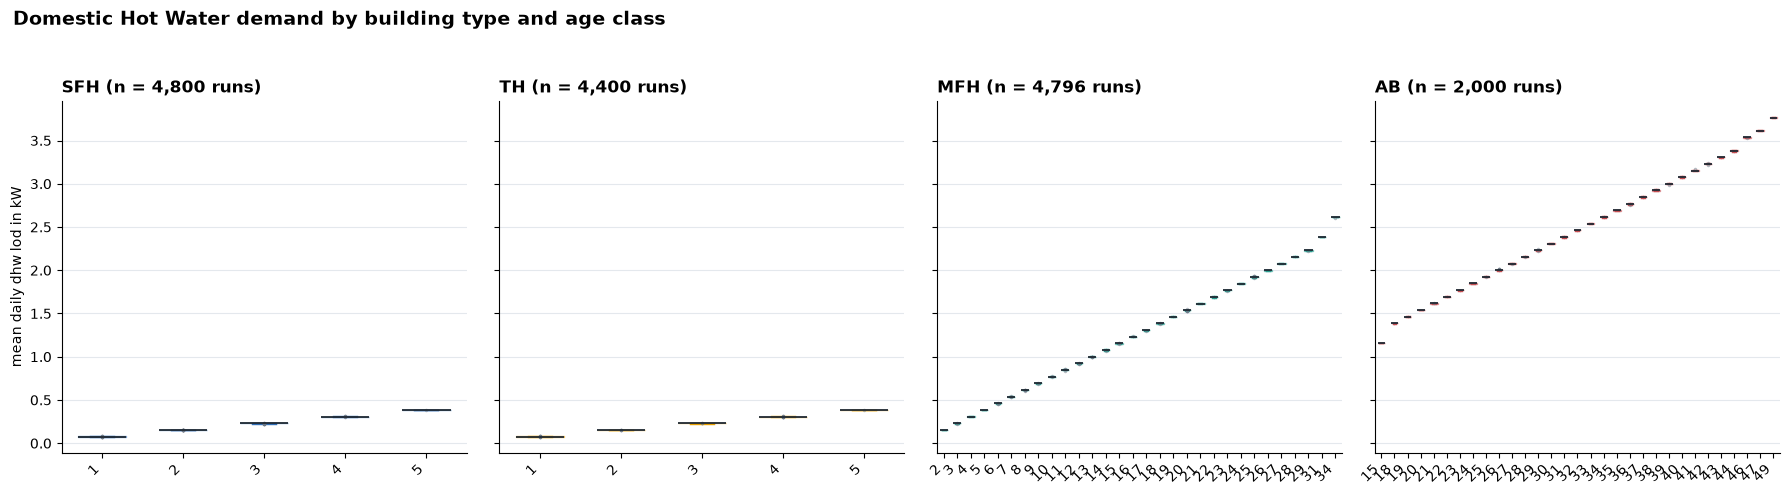

In [161]:
boxplot_specific_energy(ts_agg_daily_dhw[ts_agg_daily_dhw["day_type"]=="all"], "mean_avg",ylabel="mean daily dhw lod in kW", param="n_persons_sum")

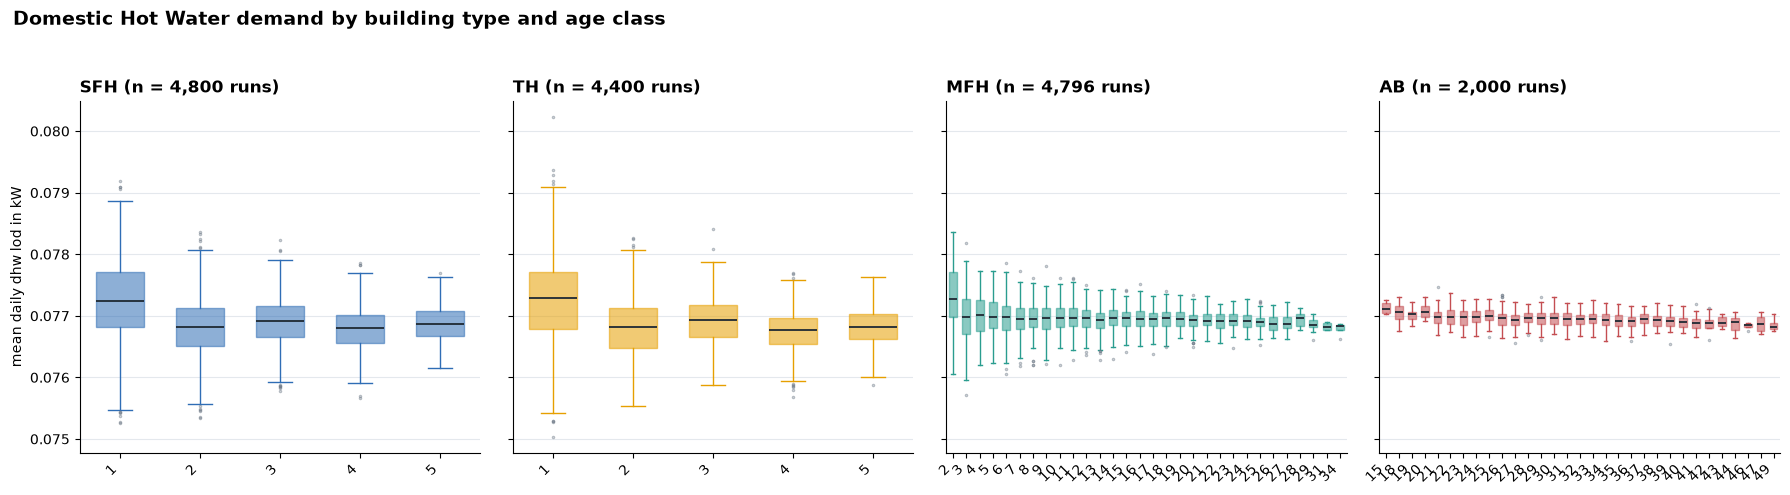

In [134]:
boxplot_specific_energy(ts_agg_daily_dhw[ts_agg_daily_dhw["day_type"]=="all"], "mean_per_occ",ylabel="mean daily dhw lod in kW", param="n_persons_sum")

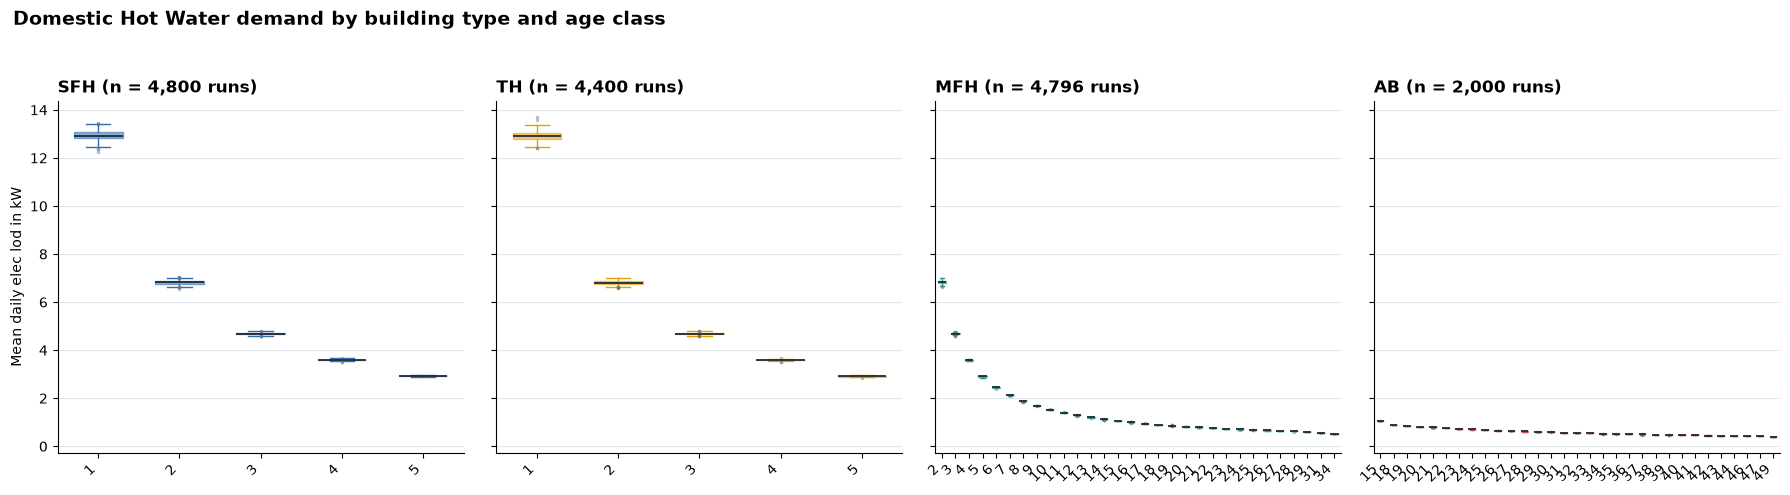

In [41]:
boxplot_specific_energy(ts_agg_daily_dhw[ts_agg_daily_dhw["day_type"]=="all"], "mean_nz_per_occ",ylabel="Mean daily dhw lod in kW", param="n_persons_sum")

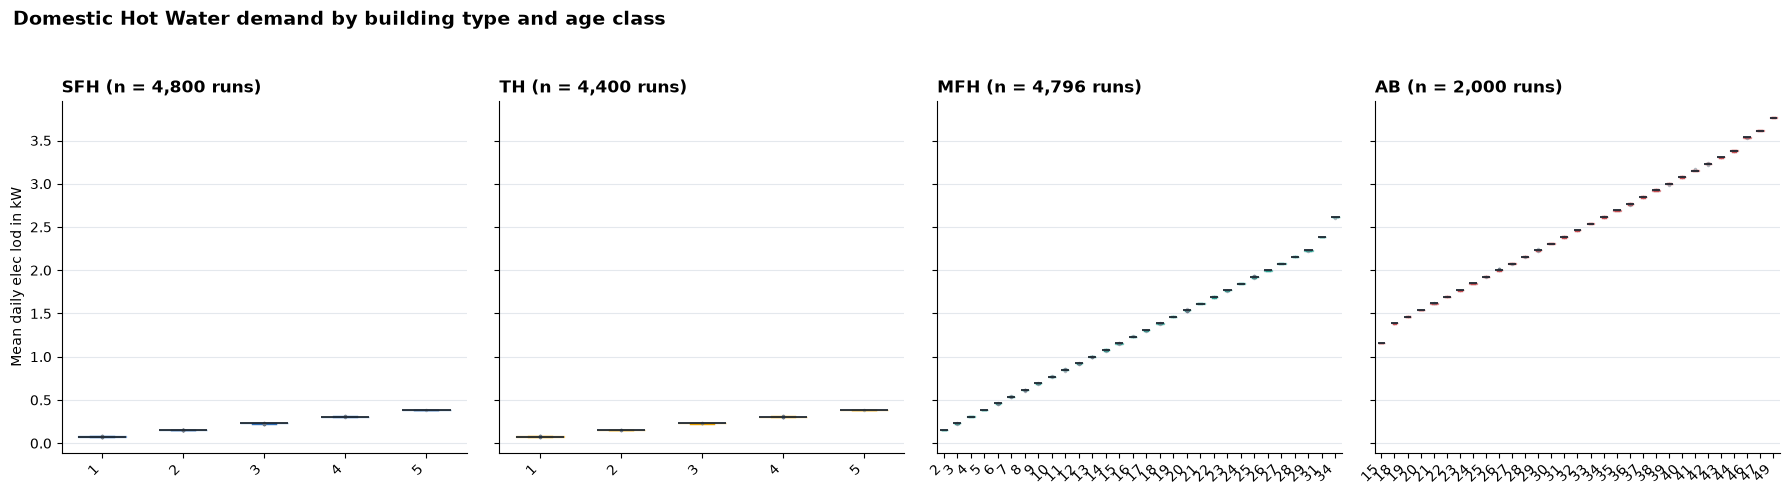

In [14]:
boxplot_specific_energy(ts_agg_daily[(ts_agg_daily["day_type"]=="all")& (ts_agg_daily["domain"]=="dhw")], "mean_avg",ylabel="Mean daily elec lod in kW", param="n_persons_sum")

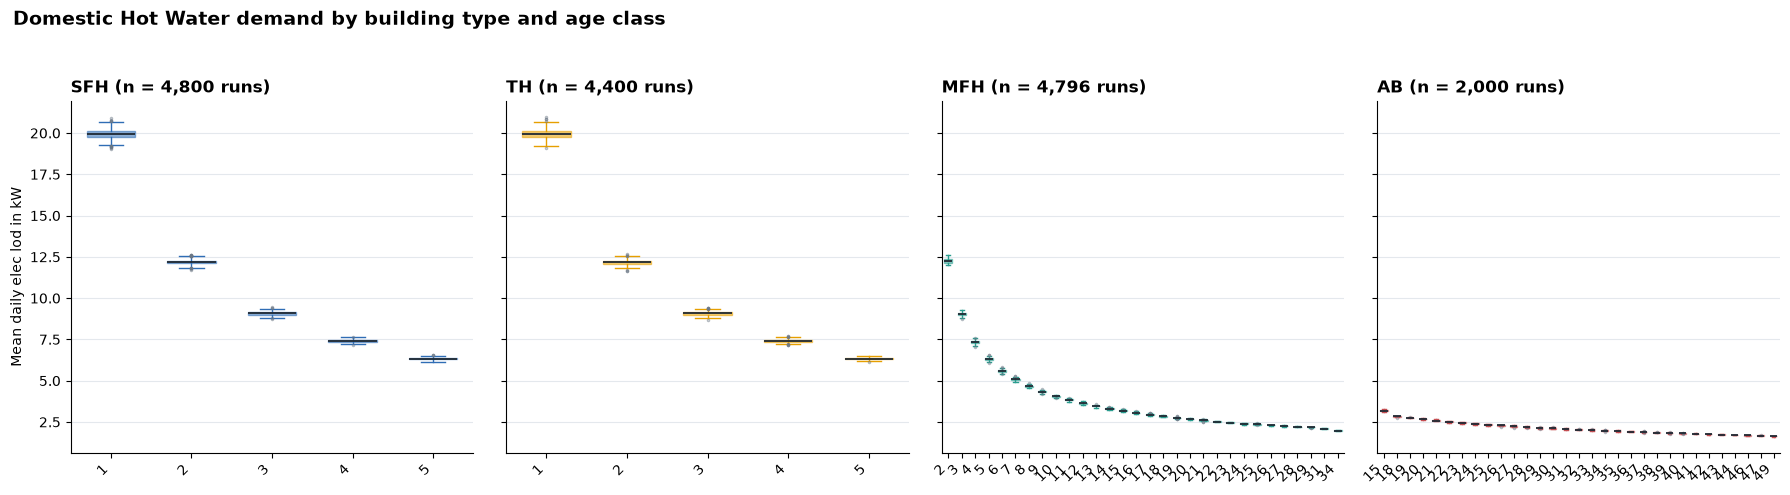

In [218]:
boxplot_specific_energy(ts_agg_daily[(ts_agg_daily["day_type"]=="all")& (ts_agg_daily["domain"]=="dhw")], "max_per_occ",ylabel="Mean daily elec lod in kW", param="n_persons_sum")

In [190]:
ts_agg = pd.read_csv("../Ch_1_Data_Preparation/run_20261011/checked_ts.csv", index_col=0)
ts_agg

,run_id,nan_vals,neg_load_vals,total_persons,a_ref,elec_sum_yearly,elec_sum_yearly_per_occ,elec_sum_yearly_per_a_ref,elec_max,elec_min,...,temperature_p05,temperature_p95,buildingType,buildingAgeBin,surrounding,climateRegion,year_type,future,seed,state_seed
0,run_000000,False,False,28,1340.909,38411.6840,1371.8458,28.646002,23.166935,0.577064,...,1.438250,24.486666,AB,DE.02,Terraced,5,average,True,1000000,1000000
1,run_000001,False,False,28,1340.909,38476.2030,1374.1501,28.694118,21.835150,0.595847,...,1.400000,23.580000,AB,DE.02,Terraced,5,average,True,1000001,1000001
2,run_000002,False,False,28,1340.909,41420.4960,1479.3035,30.889862,29.958520,0.626664,...,0.560000,23.160000,AB,DE.02,Terraced,5,average,True,1000002,1000002
3,run_000003,False,False,28,1340.909,38591.4570,1378.2664,28.780071,27.559782,0.595074,...,0.600000,22.895000,AB,DE.02,Terraced,5,average,True,1000003,1000003
4,run_000004,False,False,31,1728.922,48402.4600,1561.3698,27.995747,26.236996,0.746709,...,-0.800000,21.020000,AB,DE.02,Terraced,6,average,False,1000004,1000004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15991,run_015995,False,False,3,116.166,3642.6038,1214.2013,31.356884,7.355372,0.041829,...,-2.311667,24.573334,TH,DE.12,Semi,3,hot,False,1015995,1015995
15992,run_015996,False,False,2,121.971,3066.9524,1533.4762,25.144932,7.287327,0.048658,...,-1.446667,23.635000,TH,DE.12,Semi,12,average,False,1015996,1015996
15993,run_015997,False,False,2,121.971,2312.7020,1156.3510,18.961080,7.359022,0.027317,...,0.381667,24.348417,TH,DE.12,Semi,12,average,False,1015997,1015997
15994,run_015998,False,False,2,121.971,2381.9456,1190.9728,19.528786,7.134656,0.042682,...,-0.275000,24.926666,TH,DE.12,Semi,12,average,False,1015998,1015998


In [13]:
ts_agg[ts_agg["sh_sum_yearly_per_a_ref"] >= 300].groupby(["buildingType","buildingAgeBin"]).count()

run_id  nan_vals  neg_load_vals  total_persons  \
buildingType buildingAgeBin                                                   
AB           DE.05                3         3              3              3   
             DE.06                1         1              1              1   
MFH          DE.01              197       197            197            197   
             DE.02                2         2              2              2   
             DE.03               48        48             48             48   
             DE.04               37        37             37             37   
             DE.05              144       144            144            144   
             DE.07                2         2              2              2   
             DE.08               13        13             13             13   
             DE.10                5         5              5              5   
SFH          DE.01              263       263            263            263   
             DE.02               82        82             82             82   
             DE.03              127       127            127            127   
             DE.04               57        57             57             57   
             DE.05               42        42             42             42   
             DE.06                3         3              3              3   
TH           DE.04                1         1              1              1   

                             a_ref  elec_sum_yearly  elec_sum_yearly_per_occ  \
buildingType buildingAgeBin                                                    
AB           DE.05               3                3                        3   
             DE.06               1                1                        1   
MFH          DE.01             197              197                      197   
             DE.02               2                2                        2   
             DE.03              48               48                       48   
             DE.04              37               37                       37   
             DE.05             144              144                      144   
             DE.07               2                2                        2   
             DE.08              13               13                       13   
             DE.10               5                5                        5   
SFH          DE.01             263              263                      263   
             DE.02              82               82                       82   
             DE.03             127              127                      127   
             DE.04              57               57                       57   
             DE.05              42               42                       42   
             DE.06               3                3                        3   
TH           DE.04               1                1                        1   

                             elec_sum_yearly_per_a_ref  elec_max  elec_min  \
buildingType buildingAgeBin                                                  
AB           DE.05                                   3         3         3   
             DE.06                                   1         1         1   
MFH          DE.01                                 197       197       197   
             DE.02                                   2         2         2   
             DE.03                                  48        48        48   
             DE.04                                  37        37        37   
             DE.05                                 144       144       144   
             DE.07                                   2         2         2   
             DE.08                                  13        13        13   
             DE.10                                   5         5         5   
SFH          DE.01                                 263       263      

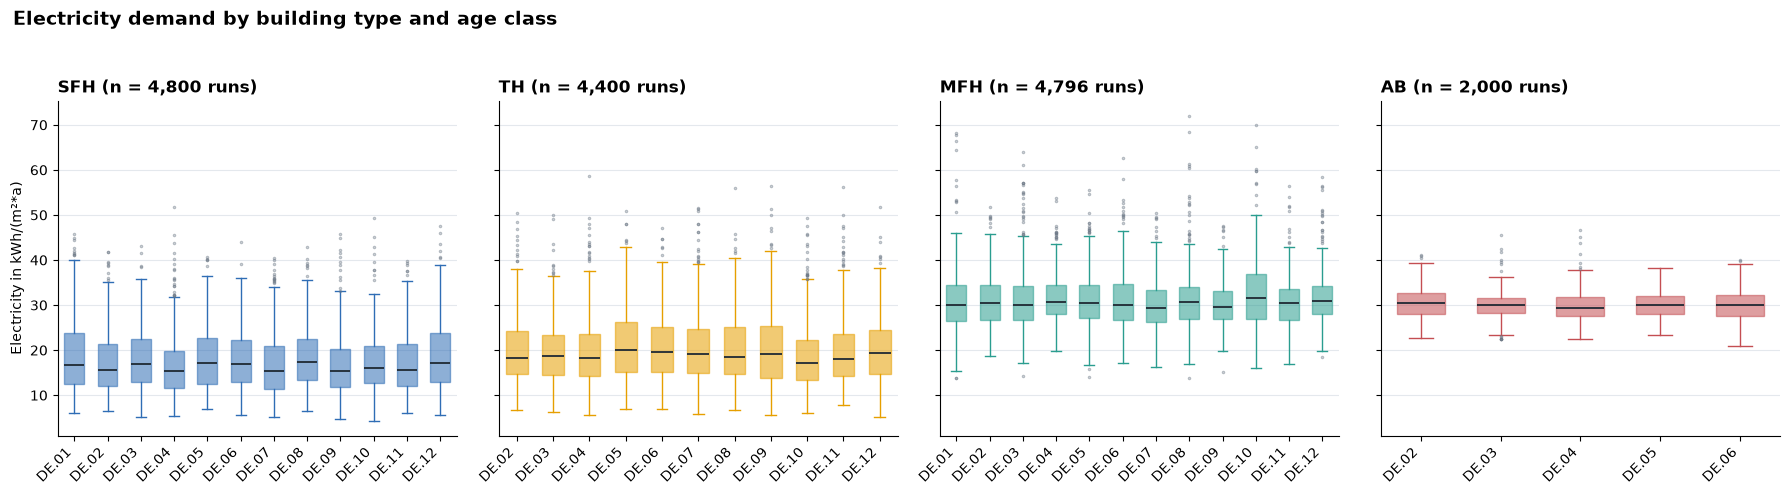

In [120]:
boxplot_specific_energy(ts_agg_yearly_elec, "sum_yearly_per_a_ref",ylabel="Electricity in kWh/(m²*a)", param="buildingAgeBin", title="Electricity demand by building type and age class")

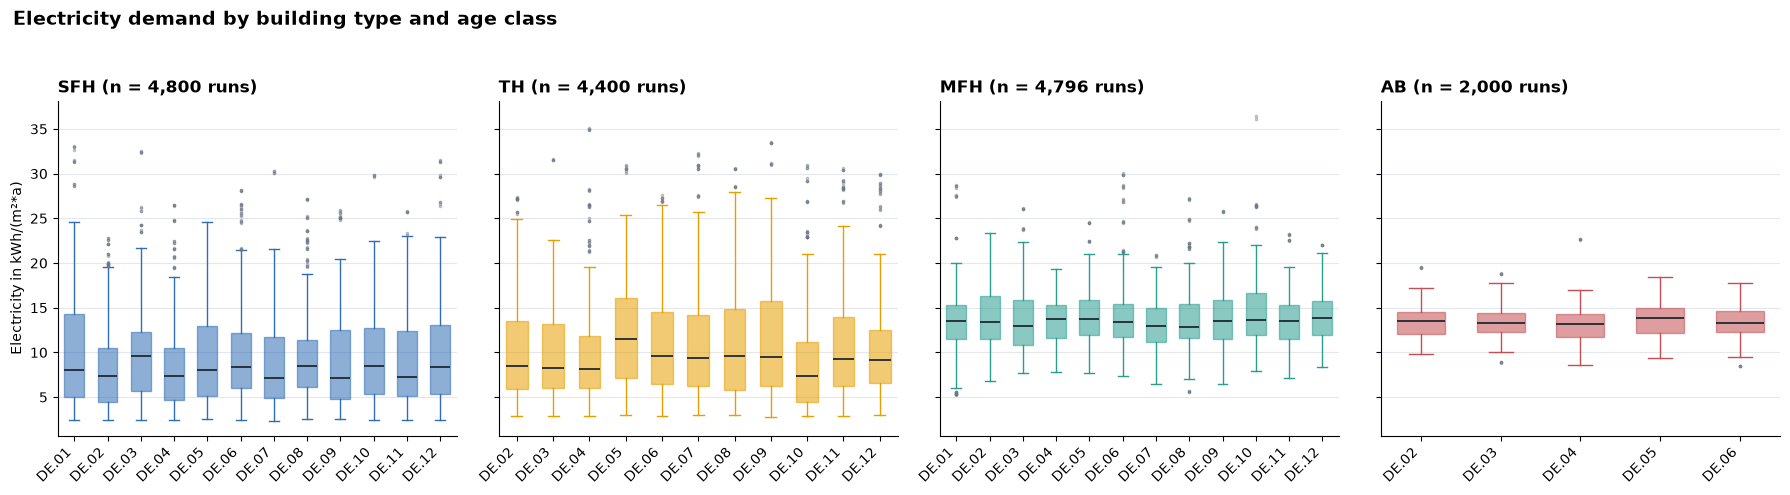

In [121]:
boxplot_specific_energy(ts_agg_yearly_dhw, "sum_yearly_per_a_ref",ylabel="Electricity in kWh/(m²*a)", param="buildingAgeBin", title="Electricity demand by building type and age class")

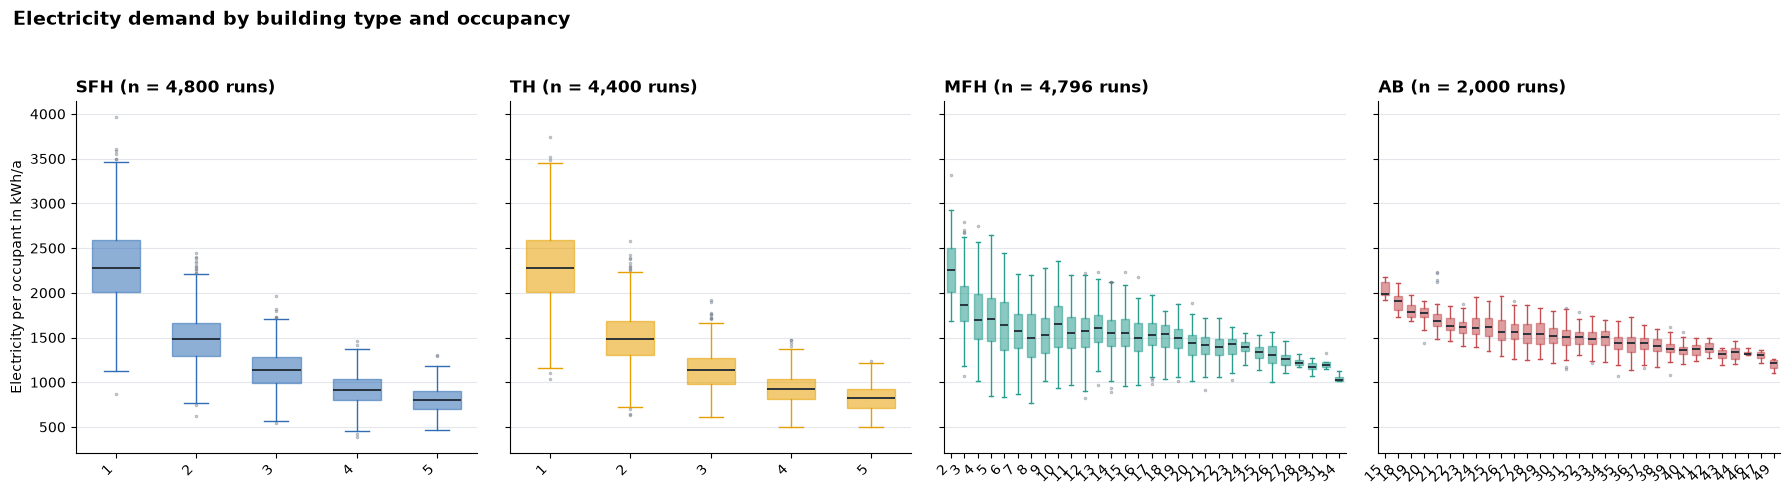

In [17]:
boxplot_specific_energy(ts_agg, "elec_sum_yearly_per_occ",ylabel="Electricity per occupant in kWh/a", param="total_persons", title="Electricity demand by building type and occupancy")

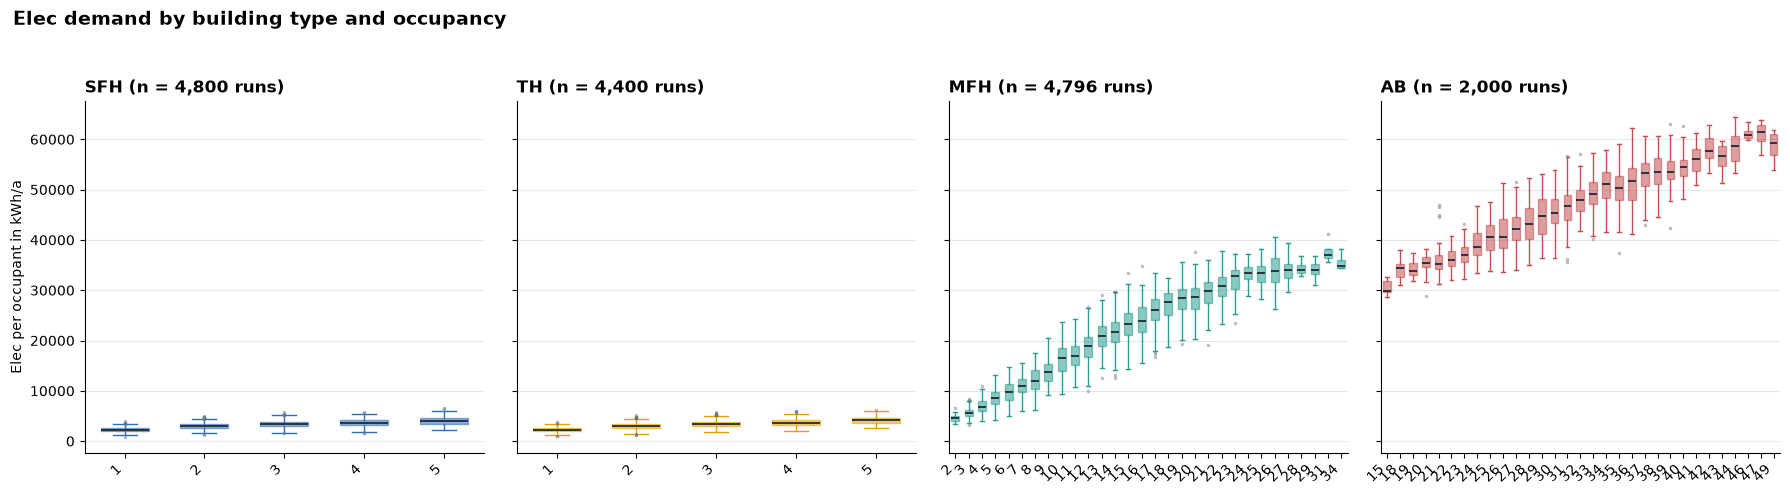

In [172]:
boxplot_specific_energy(ts_agg_yearly_elec, "sum_yearly",ylabel="Elec per occupant in kWh/a", param="n_persons_sum", title="Elec demand by building type and occupancy")

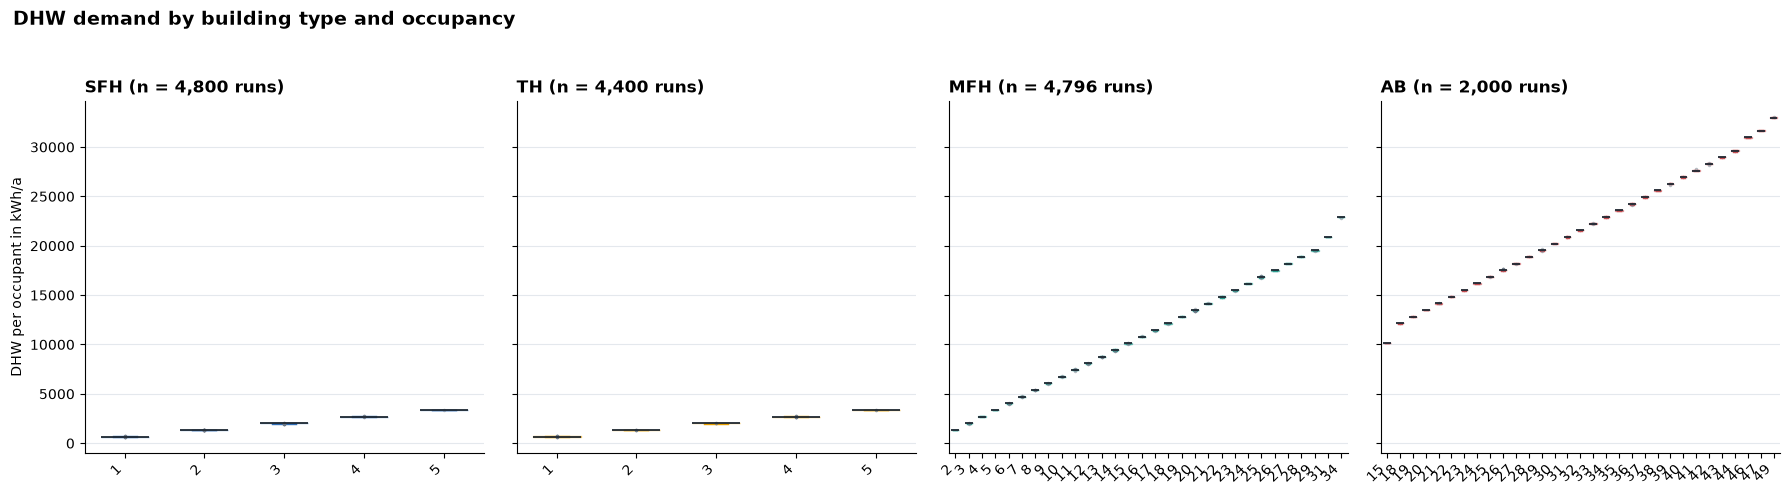

In [173]:
boxplot_specific_energy(ts_agg_yearly_dhw, "sum_yearly",ylabel="DHW per occupant in kWh/a", param="n_persons_sum", title="DHW demand by building type and occupancy")

In [20]:
pd.crosstab(ts_agg['buildingAgeBin'], ts_agg["buildingType"])

buildingType,AB,MFH,SFH,TH
buildingAgeBin,,,,
DE.01,0,400,400,0
DE.02,400,400,400,400
DE.03,400,400,400,400
DE.04,400,400,400,400
DE.05,400,400,400,400
DE.06,400,400,400,400
DE.07,0,400,400,400
DE.08,0,400,400,400
DE.09,0,400,400,400


In [21]:
manifest[["run_id","n_apartments"]]

,run_id,n_apartments
0,run_000000,14
1,run_000001,14
2,run_000002,14
3,run_000003,14
4,run_000004,18
...,...,...
15991,run_015995,1
15992,run_015996,1
15993,run_015997,1
15994,run_015998,1


In [22]:
x=ts_agg.merge(manifest[["run_id","n_apartments", "building_id","appliances"]], on="run_id")

In [23]:
x

,run_id,nan_vals,neg_load_vals,total_persons,a_ref,elec_sum_yearly,elec_sum_yearly_per_occ,elec_sum_yearly_per_a_ref,elec_max,elec_min,...,buildingAgeBin,surrounding,climateRegion,year_type,future,seed,state_seed,n_apartments,building_id,appliances
0,run_000000,False,False,28,1340.909,38411.6840,1371.8458,28.646002,23.166935,0.577064,...,DE.02,Terraced,5,average,True,1000000,1000000,14,0,"[['UPRIGHT_FREEZER', 'ANSWER_MACHINE', 'CD_PLA..."
1,run_000001,False,False,28,1340.909,38476.2030,1374.1501,28.694118,21.835150,0.595847,...,DE.02,Terraced,5,average,True,1000001,1000001,14,0,"[['FRIDGE_FREEZER', 'FRIDGE', 'ANSWER_MACHINE'..."
2,run_000002,False,False,28,1340.909,41420.4960,1479.3035,30.889862,29.958520,0.626664,...,DE.02,Terraced,5,average,True,1000002,1000002,14,0,"[['FRIDGE', 'ANSWER_MACHINE', 'CD_PLAYER', 'CL..."
3,run_000003,False,False,28,1340.909,38591.4570,1378.2664,28.780071,27.559782,0.595074,...,DE.02,Terraced,5,average,True,1000003,1000003,14,0,"[['FRIDGE', 'ANSWER_MACHINE', 'CLOCK', 'PHONE'..."
4,run_000004,False,False,31,1728.922,48402.4600,1561.3698,27.995747,26.236996,0.746709,...,DE.02,Terraced,6,average,False,1000004,1000004,18,1,"[['CHEST_FREEZER', 'FRIDGE_FREEZER', 'ANSWER_M..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15991,run_015995,False,False,3,116.166,3642.6038,1214.2013,31.356884,7.355372,0.041829,...,DE.12,Semi,3,hot,False,1015995,1015995,1,3998,"[['FRIDGE', 'CD_PLAYER', 'CLOCK', 'HIFI', 'VAC..."
15992,run_015996,False,False,2,121.971,3066.9524,1533.4762,25.144932,7.287327,0.048658,...,DE.12,Semi,12,average,False,1015996,1015996,1,3999,"[['FRIDGE_FREEZER', 'ANSWER_MACHINE', 'CD_PLAY..."
15993,run_015997,False,False,2,121.971,2312.7020,1156.3510,18.961080,7.359022,0.027317,...,DE.12,Semi,12,average,False,1015997,1015997,1,3999,"[['FRIDGE_FREEZER', 'ANSWER_MACHINE', 'CD_PLAY..."
15994,run_015998,False,False,2,121.971,2381.9456,1190.9728,19.528786,7.134656,0.042682,...,DE.12,Semi,12,average,False,1015998,1015998,1,3999,"[['FRIDGE', 'ANSWER_MACHINE', 'CD_PLAYER', 'CL..."


In [24]:
manifest.groupby("buildingType")["a_ref"].mean()

buildingType
AB     1531.934256
MFH     648.059693
SFH     188.046593
TH      163.224694
Name: a_ref, dtype: float64

In [25]:
ts_agg

,run_id,nan_vals,neg_load_vals,total_persons,a_ref,elec_sum_yearly,elec_sum_yearly_per_occ,elec_sum_yearly_per_a_ref,elec_max,elec_min,...,temperature_p05,temperature_p95,buildingType,buildingAgeBin,surrounding,climateRegion,year_type,future,seed,state_seed
0,run_000000,False,False,28,1340.909,38411.6840,1371.8458,28.646002,23.166935,0.577064,...,1.438250,24.486666,AB,DE.02,Terraced,5,average,True,1000000,1000000
1,run_000001,False,False,28,1340.909,38476.2030,1374.1501,28.694118,21.835150,0.595847,...,1.400000,23.580000,AB,DE.02,Terraced,5,average,True,1000001,1000001
2,run_000002,False,False,28,1340.909,41420.4960,1479.3035,30.889862,29.958520,0.626664,...,0.560000,23.160000,AB,DE.02,Terraced,5,average,True,1000002,1000002
3,run_000003,False,False,28,1340.909,38591.4570,1378.2664,28.780071,27.559782,0.595074,...,0.600000,22.895000,AB,DE.02,Terraced,5,average,True,1000003,1000003
4,run_000004,False,False,31,1728.922,48402.4600,1561.3698,27.995747,26.236996,0.746709,...,-0.800000,21.020000,AB,DE.02,Terraced,6,average,False,1000004,1000004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15991,run_015995,False,False,3,116.166,3642.6038,1214.2013,31.356884,7.355372,0.041829,...,-2.311667,24.573334,TH,DE.12,Semi,3,hot,False,1015995,1015995
15992,run_015996,False,False,2,121.971,3066.9524,1533.4762,25.144932,7.287327,0.048658,...,-1.446667,23.635000,TH,DE.12,Semi,12,average,False,1015996,1015996
15993,run_015997,False,False,2,121.971,2312.7020,1156.3510,18.961080,7.359022,0.027317,...,0.381667,24.348417,TH,DE.12,Semi,12,average,False,1015997,1015997
15994,run_015998,False,False,2,121.971,2381.9456,1190.9728,19.528786,7.134656,0.042682,...,-0.275000,24.926666,TH,DE.12,Semi,12,average,False,1015998,1015998


## Impact of different Variables

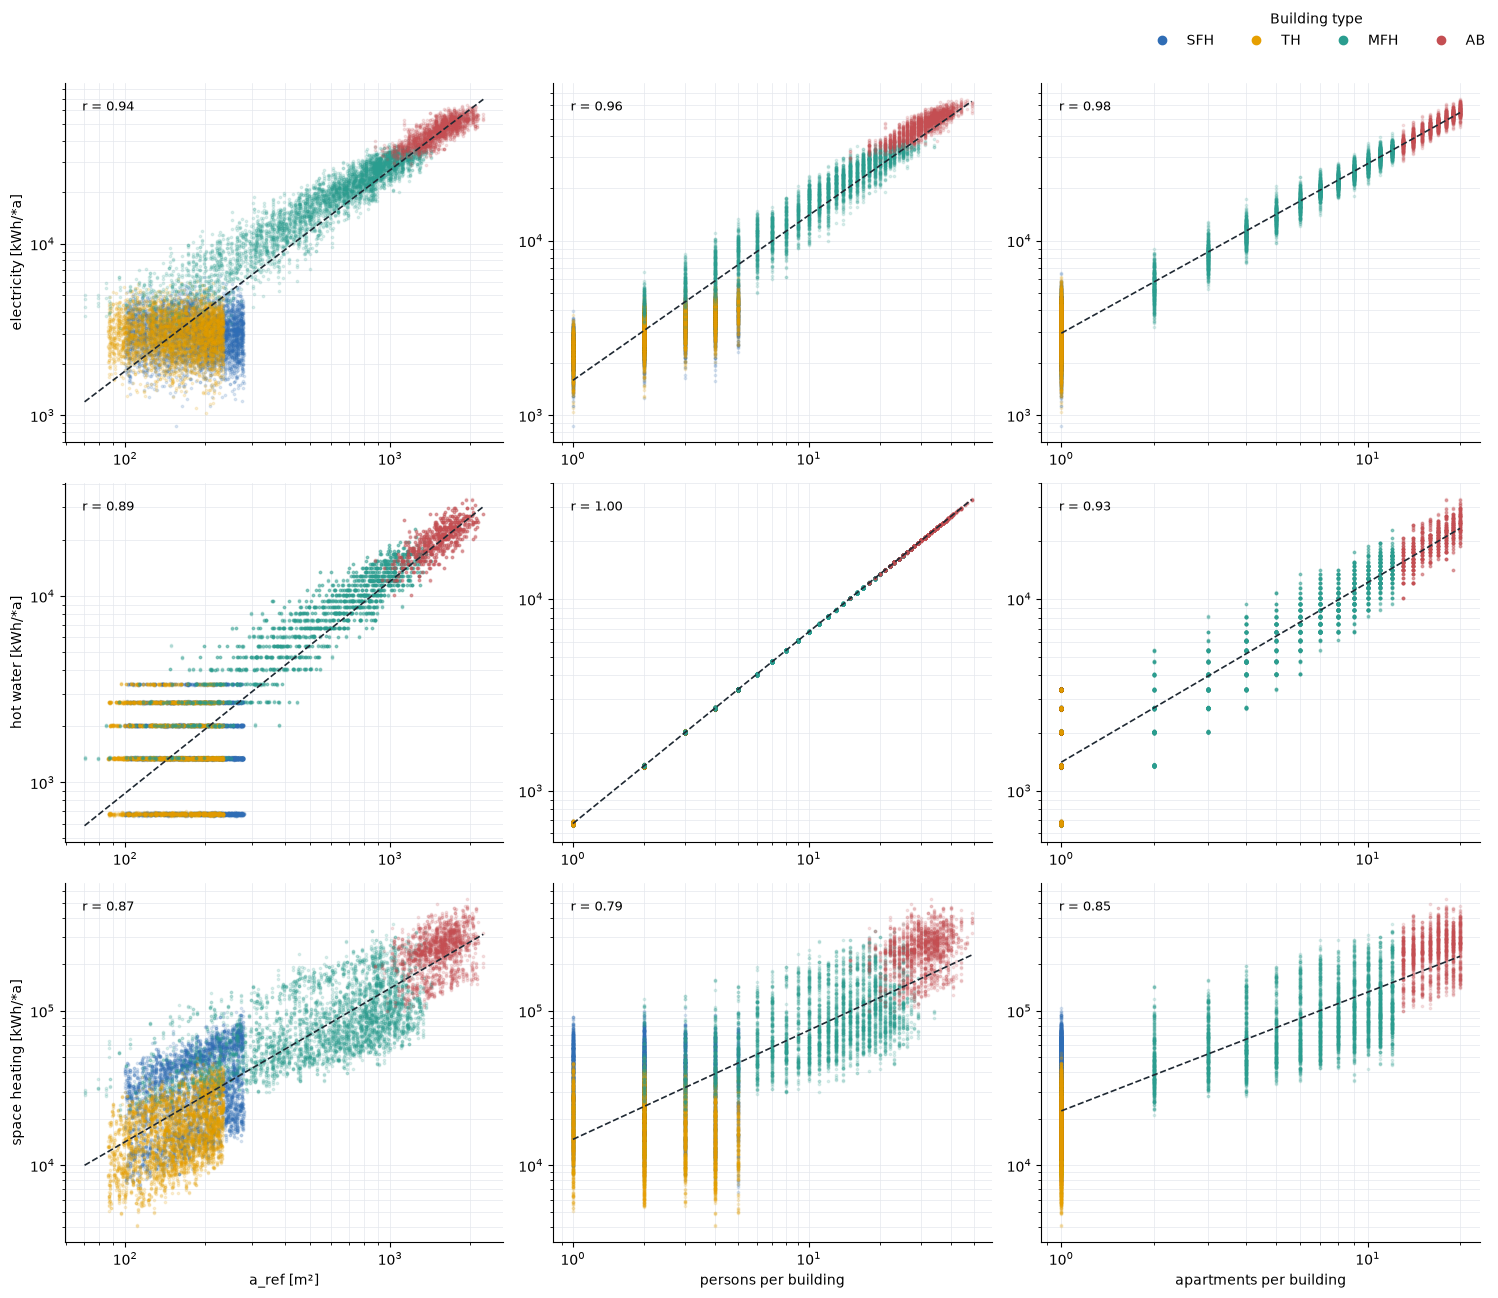

In [26]:
# Todo check what log log regression actually does, vs
XS = {"a_ref": "a_ref [m²]", "total_persons": "persons per building", "n_apartments": "apartments per building"}
YS = {"elec_sum_yearly": "electricity [kWh/*a]", "dhw_sum_yearly": "hot water [kWh/*a]", "sh_sum_yearly": "space heating [kWh/*a]"}
plot_parameter_scatter_cont(x,en_type=YS, params=XS)

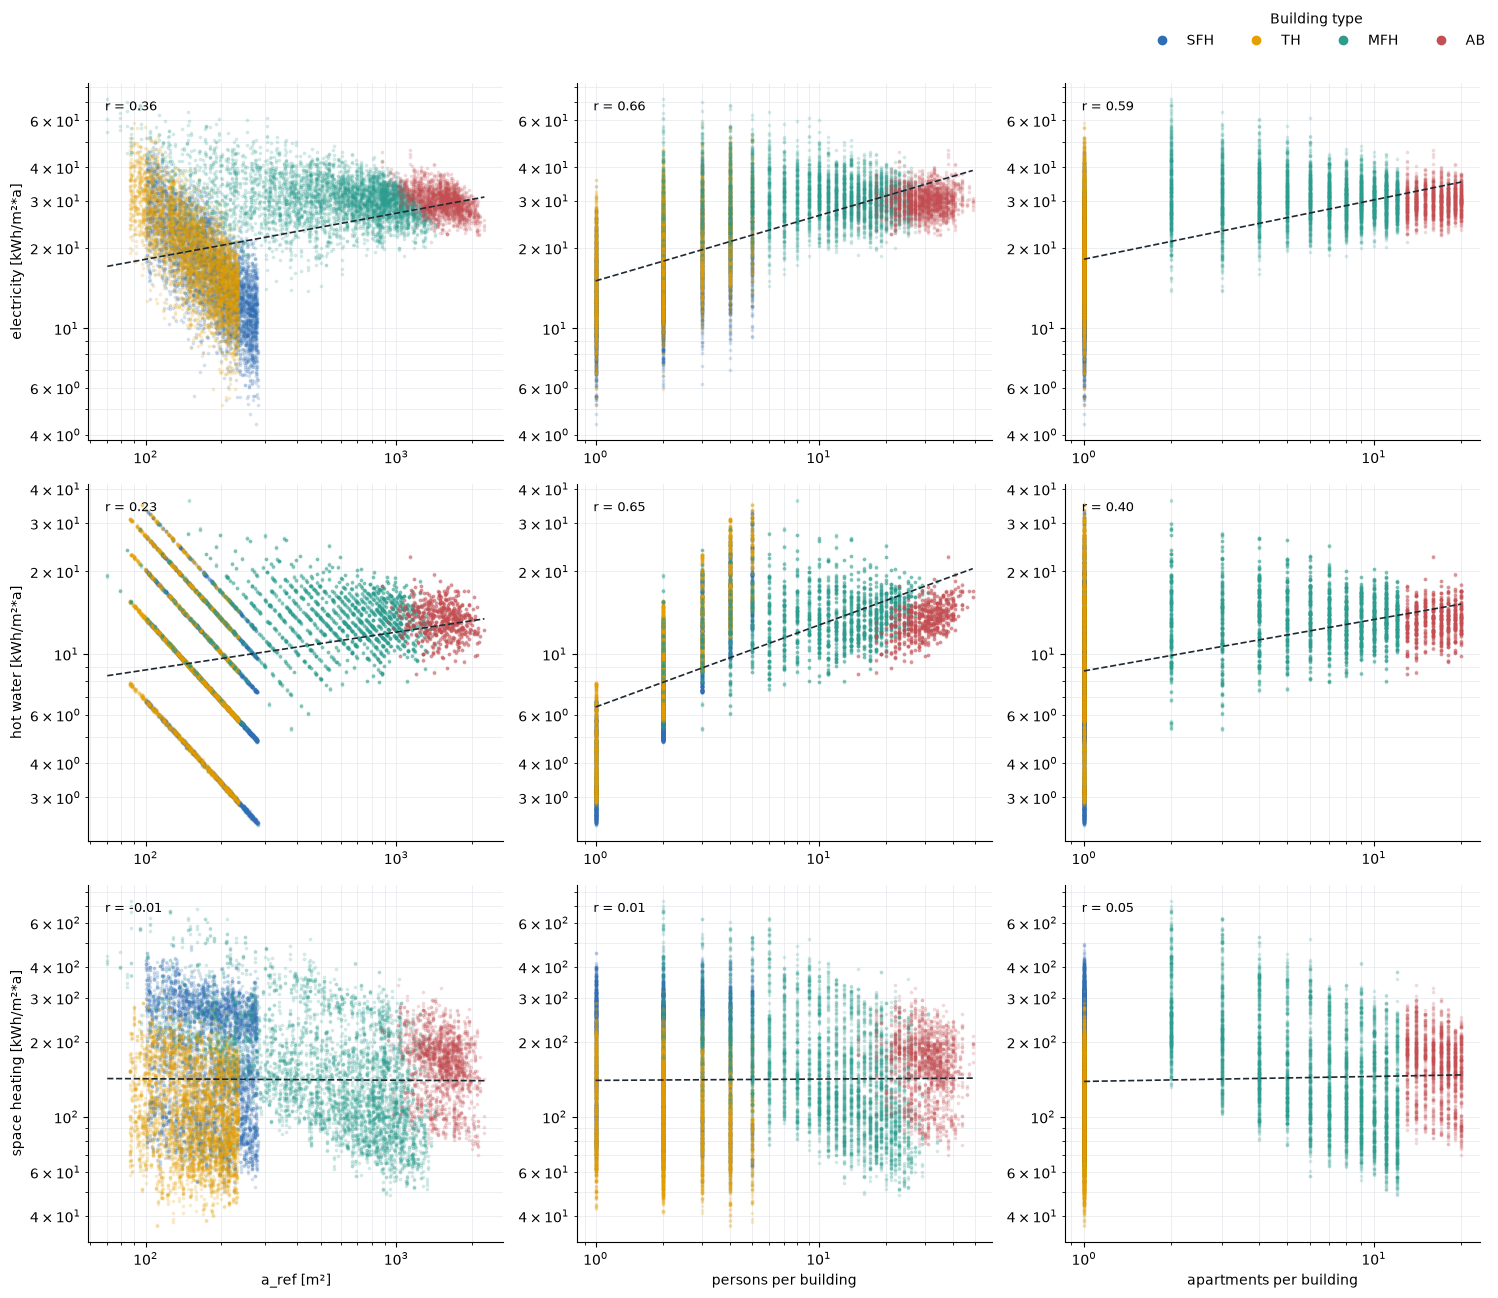

In [27]:
XS = {"a_ref": "a_ref [m²]", "total_persons": "persons per building", "n_apartments": "apartments per building"}
YS = {"elec_sum_yearly_per_a_ref": "electricity [kWh/m²*a]", "dhw_sum_yearly_per_a_ref": "hot water [kWh/m²*a]", "sh_sum_yearly_per_a_ref": "space heating [kWh/m²*a]"}
plot_parameter_scatter_cont(x,en_type=YS, params=XS)

In [28]:
ts_agg.groupby("total_persons")["elec_sum_yearly_per_occ"].mean()

total_persons
1     2294.800625
2     1515.888867
3     1218.883182
4     1041.771565
5     1074.111496
6     1643.834931
7     1566.180754
8     1512.451429
9     1533.248020
10    1626.017840
11    1554.174203
12    1541.428296
13    1604.663281
14    1546.380151
15    1566.284076
16    1492.336739
17    1523.000774
18    1560.079026
19    1494.935912
20    1465.283910
21    1485.004812
22    1483.287115
23    1493.757294
24    1526.241402
25    1438.151266
26    1512.385798
27    1513.652280
28    1512.225660
29    1495.189093
30    1520.378540
31    1494.752068
32    1497.498061
33    1488.462960
34    1480.034032
35    1440.868027
36    1425.714664
37    1430.747505
38    1413.891482
39    1379.108335
40    1363.359019
41    1368.185619
42    1380.391442
43    1307.106487
44    1328.154508
46    1331.204375
47    1296.253675
49    1196.323125
Name: elec_sum_yearly_per_occ, dtype: float64

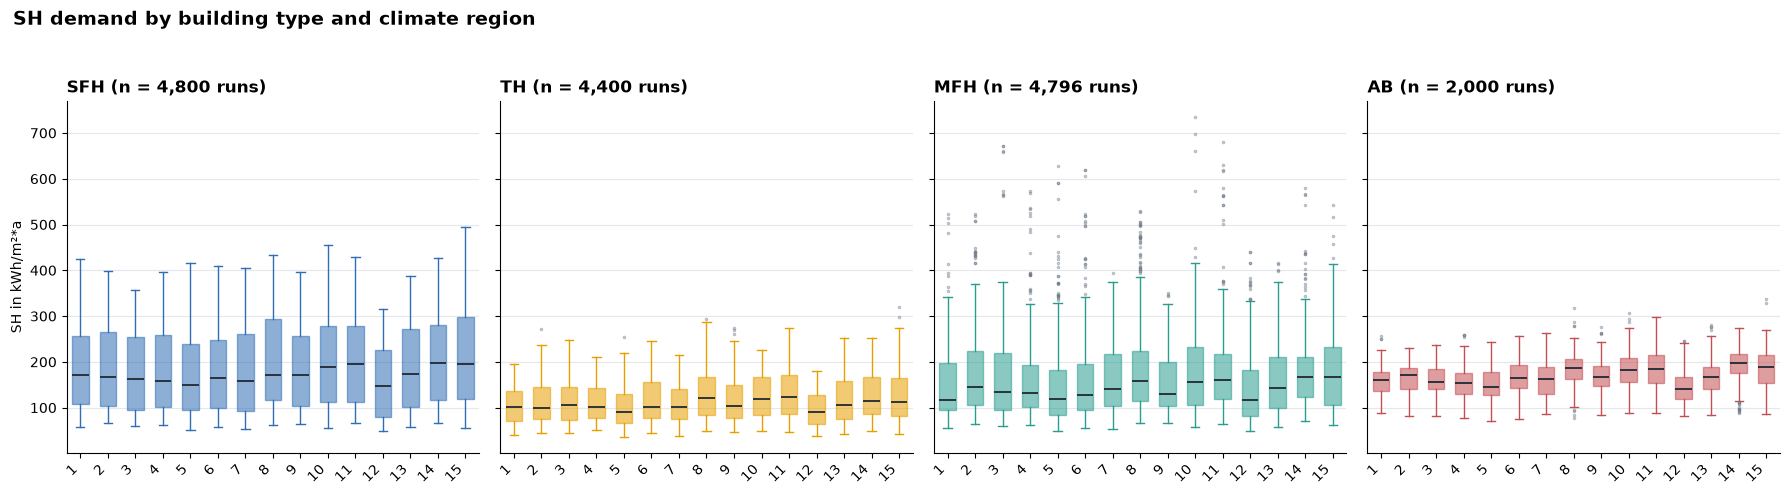

In [29]:
boxplot_specific_energy(ts_agg, "sh_sum_yearly_per_a_ref",ylabel="SH in kWh/m²*a", param="climateRegion", title="SH demand by building type and climate region")

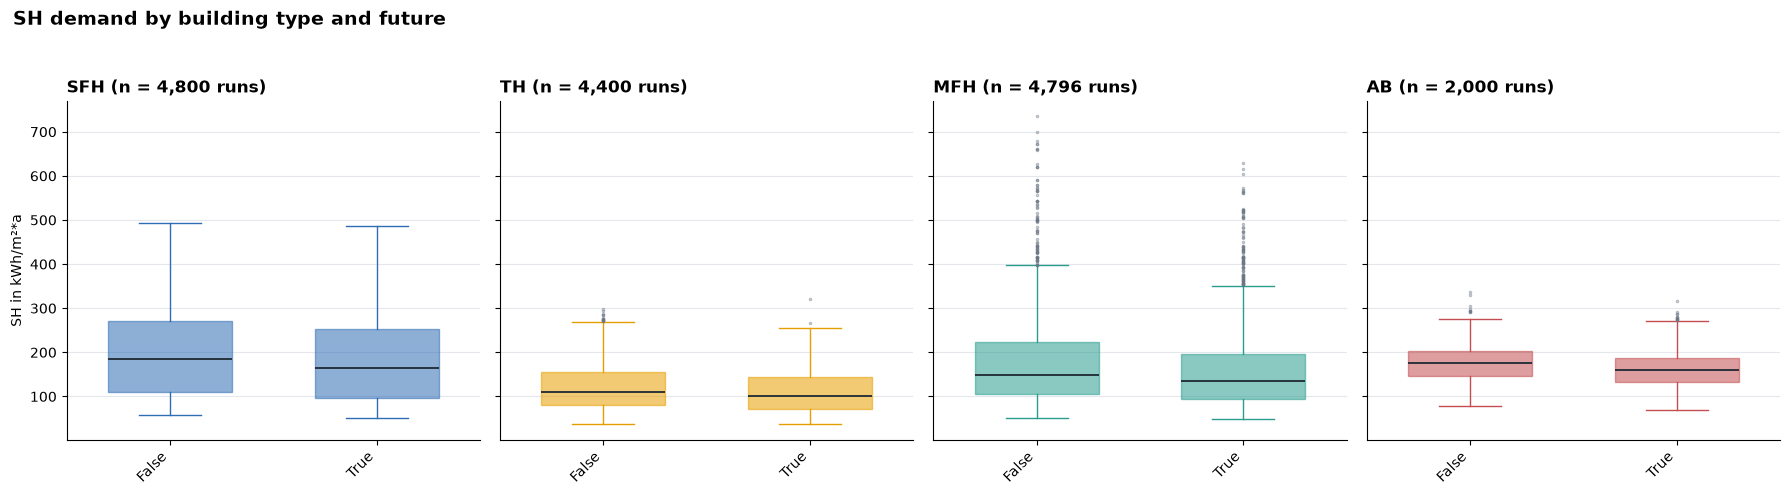

In [30]:
boxplot_specific_energy(ts_agg, "sh_sum_yearly_per_a_ref",ylabel="SH in kWh/m²*a", param="future", title="SH demand by building type and future")

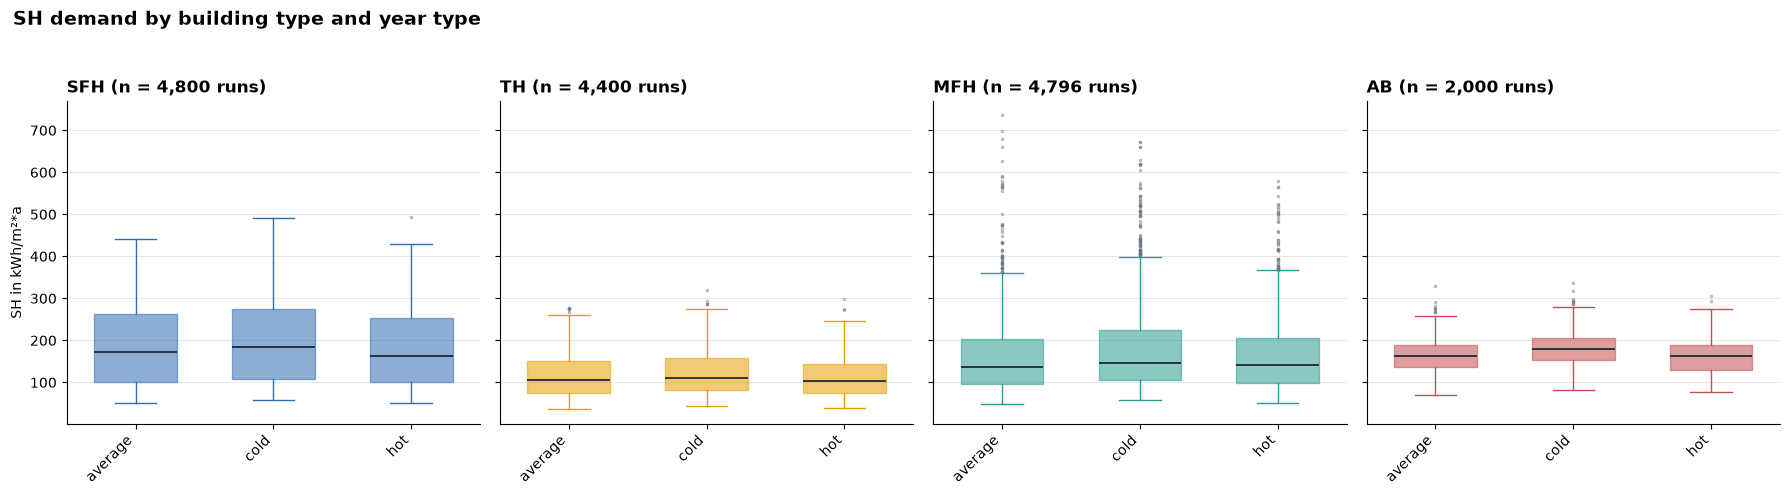

In [31]:
boxplot_specific_energy(ts_agg, "sh_sum_yearly_per_a_ref",ylabel="SH in kWh/m²*a", param="year_type", title="SH demand by building type and year type")

In [32]:
ts_agg

,run_id,nan_vals,neg_load_vals,total_persons,a_ref,elec_sum_yearly,elec_sum_yearly_per_occ,elec_sum_yearly_per_a_ref,elec_max,elec_min,...,temperature_p05,temperature_p95,buildingType,buildingAgeBin,surrounding,climateRegion,year_type,future,seed,state_seed
0,run_000000,False,False,28,1340.909,38411.6840,1371.8458,28.646002,23.166935,0.577064,...,1.438250,24.486666,AB,DE.02,Terraced,5,average,True,1000000,1000000
1,run_000001,False,False,28,1340.909,38476.2030,1374.1501,28.694118,21.835150,0.595847,...,1.400000,23.580000,AB,DE.02,Terraced,5,average,True,1000001,1000001
2,run_000002,False,False,28,1340.909,41420.4960,1479.3035,30.889862,29.958520,0.626664,...,0.560000,23.160000,AB,DE.02,Terraced,5,average,True,1000002,1000002
3,run_000003,False,False,28,1340.909,38591.4570,1378.2664,28.780071,27.559782,0.595074,...,0.600000,22.895000,AB,DE.02,Terraced,5,average,True,1000003,1000003
4,run_000004,False,False,31,1728.922,48402.4600,1561.3698,27.995747,26.236996,0.746709,...,-0.800000,21.020000,AB,DE.02,Terraced,6,average,False,1000004,1000004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15991,run_015995,False,False,3,116.166,3642.6038,1214.2013,31.356884,7.355372,0.041829,...,-2.311667,24.573334,TH,DE.12,Semi,3,hot,False,1015995,1015995
15992,run_015996,False,False,2,121.971,3066.9524,1533.4762,25.144932,7.287327,0.048658,...,-1.446667,23.635000,TH,DE.12,Semi,12,average,False,1015996,1015996
15993,run_015997,False,False,2,121.971,2312.7020,1156.3510,18.961080,7.359022,0.027317,...,0.381667,24.348417,TH,DE.12,Semi,12,average,False,1015997,1015997
15994,run_015998,False,False,2,121.971,2381.9456,1190.9728,19.528786,7.134656,0.042682,...,-0.275000,24.926666,TH,DE.12,Semi,12,average,False,1015998,1015998


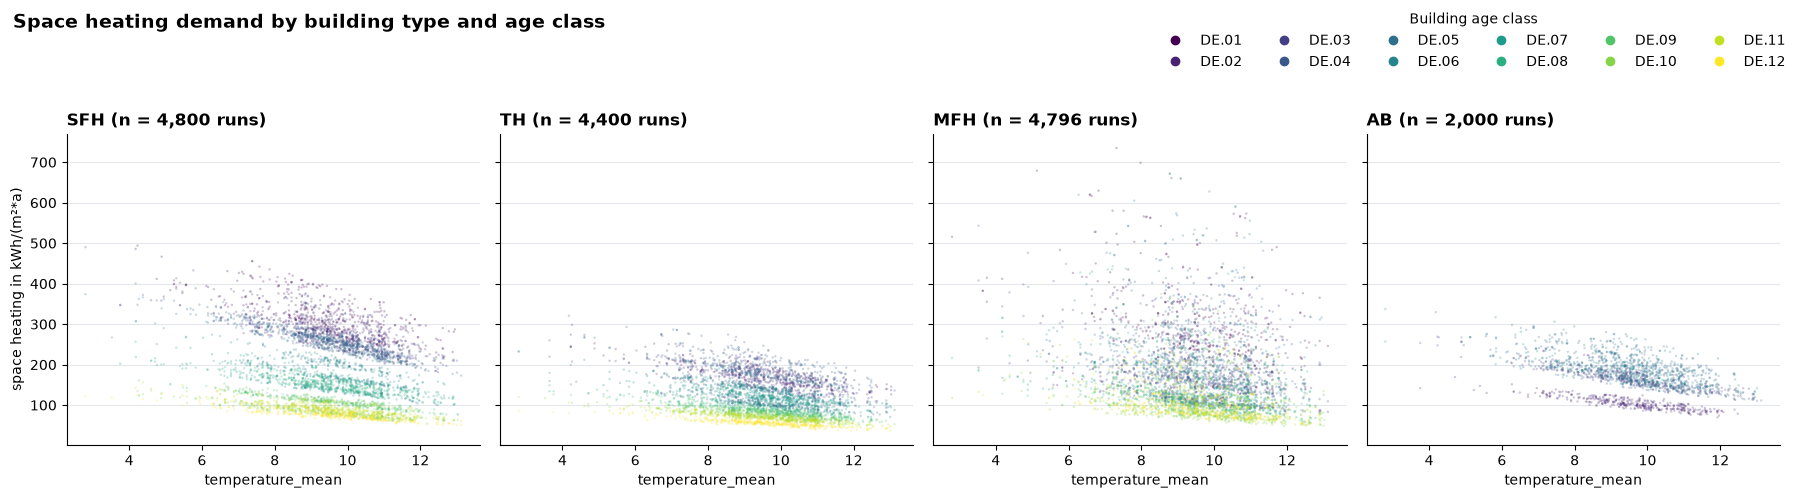

In [33]:
scatter_specific_energy_by_building_type(ts_agg, y="sh_sum_yearly_per_a_ref", x="temperature_mean", logy=False)

## Impact of Appliances

In [34]:
manifest = pd.read_csv(r"../Ch_1_Data_Preparation/run_20261011/realized_manifest_cleaned.csv", index_col=0)

In [35]:
ts = pd.read_csv("../Ch_1_Data_Preparation/run_20261011/checked_ts.csv", index_col=0)
manifest_apl, apliances = add_appliance_shares(manifest)

df = manifest_apl.merge(ts, on="run_id", how="inner", suffixes=("", "_ts"))

In [36]:
df = add_appliance_counts(df)
df = per_apartment_loads(df)
share_df = df["appliances"].apply(calculate_group_shares)
df = pd.concat([df, share_df], axis=1)

In [37]:
df

,country,buildingType,surrounding,buildingAgeBin,a_ref,n_apartments,year_type,future,climateRegion,n_persons,...,elec_p95_per_apartment,elec_p99_per_apartment,elec_sum_yearly_per_apartment,peak_to_average,buildingGroup,share_Continuous,share_Entertainment,share_Cleaning,share_Cooking,share_Other
0,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,0.687039,0.898126,2743.691714,5.283350,MFH + AB,0.375000,0.775510,0.547619,0.771429,0.714286
1,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,0.678447,0.885355,2748.300214,4.971279,MFH + AB,0.339286,0.775510,0.511905,0.785714,0.690476
2,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,0.746757,0.973639,2958.606857,6.335912,MFH + AB,0.267857,0.826531,0.654762,0.785714,0.726190
3,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,0.704065,0.915613,2756.532643,6.255885,MFH + AB,0.267857,0.755102,0.642857,0.771429,0.761905
4,DE,AB,Terraced,DE.02,1728.922,18,average,False,6,"[2, 4, 2, 1, 1, 1, 1, 2, 1, 2, 2, 2, 1, 3, 2, ...",...,0.629564,0.802312,2689.025556,4.748438,MFH + AB,0.430556,0.722222,0.527778,0.788889,0.731481
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15991,DE,TH,Semi,DE.12,116.166,1,hot,False,3,[3],...,2.056448,3.070481,3642.603800,17.688738,SFH + TH,0.250000,0.714286,0.666667,0.600000,0.500000
15992,DE,TH,Semi,DE.12,121.971,1,average,False,12,[2],...,1.520225,2.917146,3066.952400,20.814470,SFH + TH,0.250000,0.857143,0.666667,0.800000,0.833333
15993,DE,TH,Semi,DE.12,121.971,1,average,False,12,[2],...,0.959711,2.703966,2312.702000,27.874337,SFH + TH,0.250000,0.571429,0.666667,0.600000,0.333333
15994,DE,TH,Semi,DE.12,121.971,1,average,False,12,[2],...,1.438349,2.605852,2381.945600,26.238884,SFH + TH,0.250000,0.714286,0.666667,0.800000,0.666667


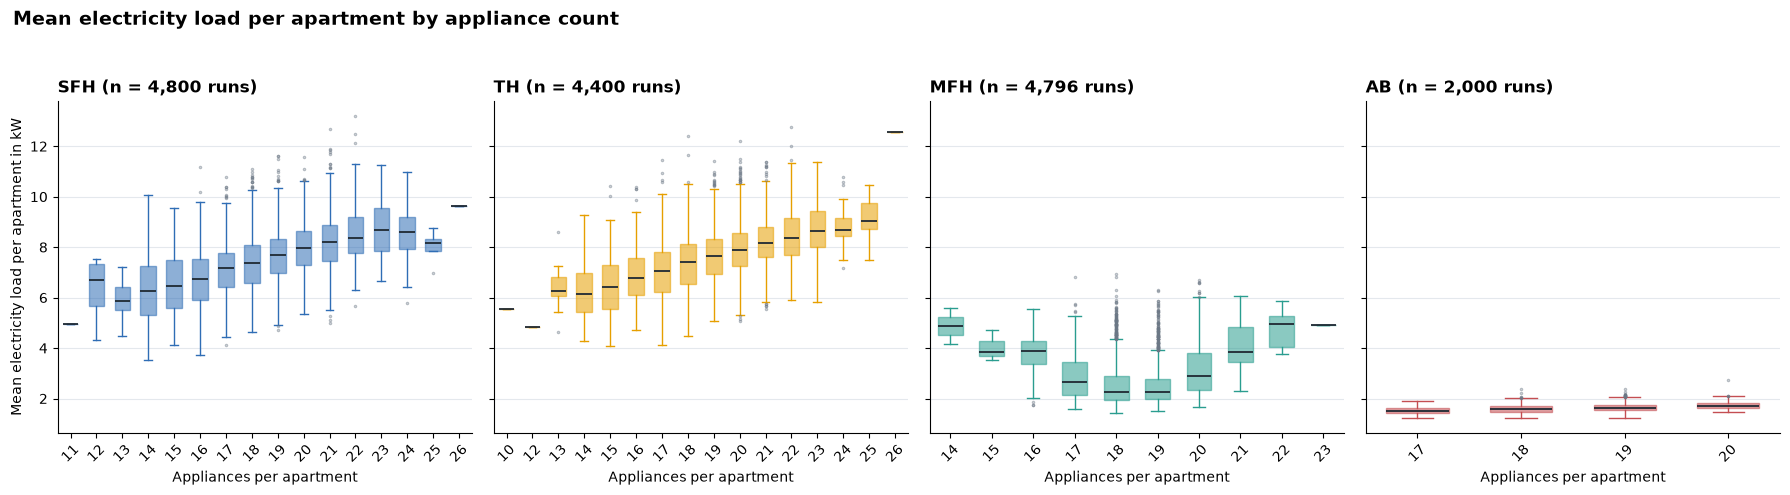

In [38]:

plot_total_appliances_vs_metric(
    df,
    metric="elec_max_per_apartment",
    ylabel="Mean electricity load per apartment in kW",
    title="Mean electricity load per apartment by appliance count"
)

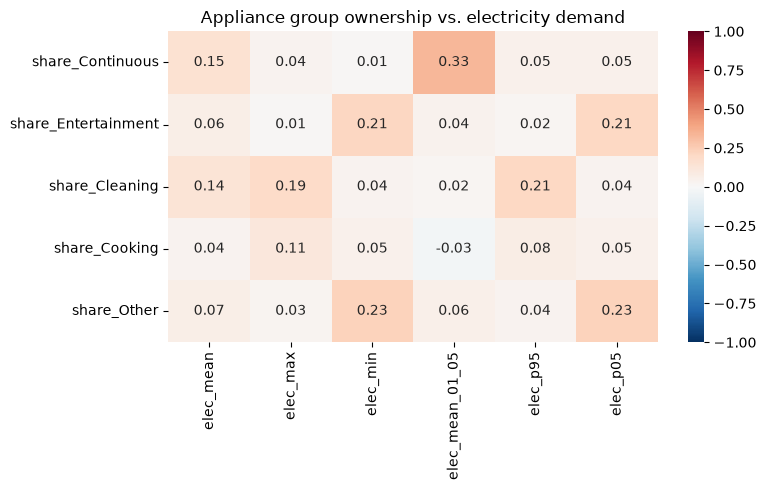

In [39]:
plot_appliance_heatmap(df, share_df)

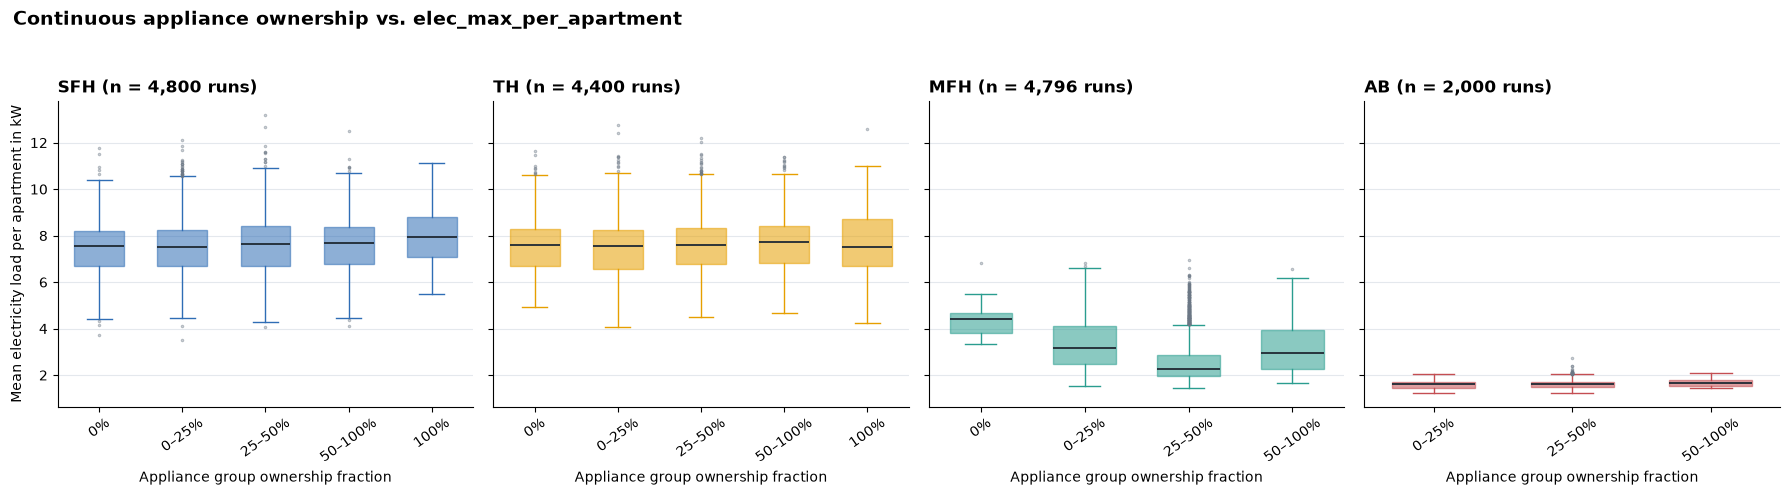

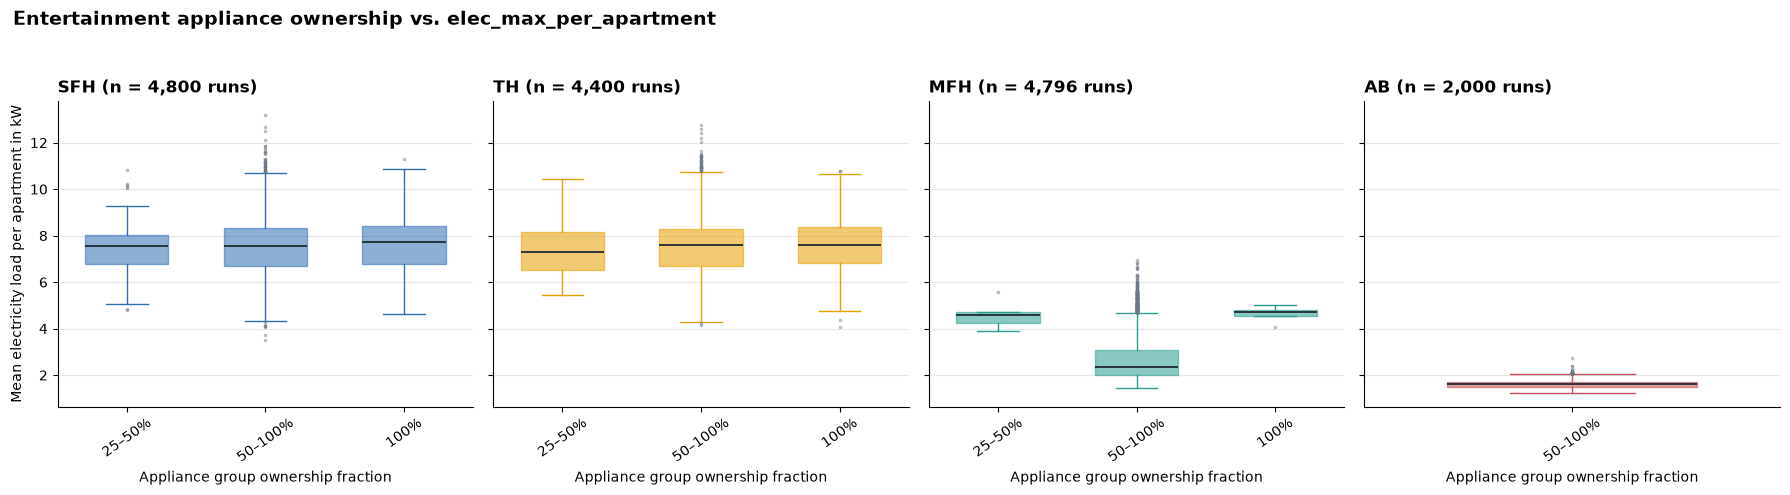

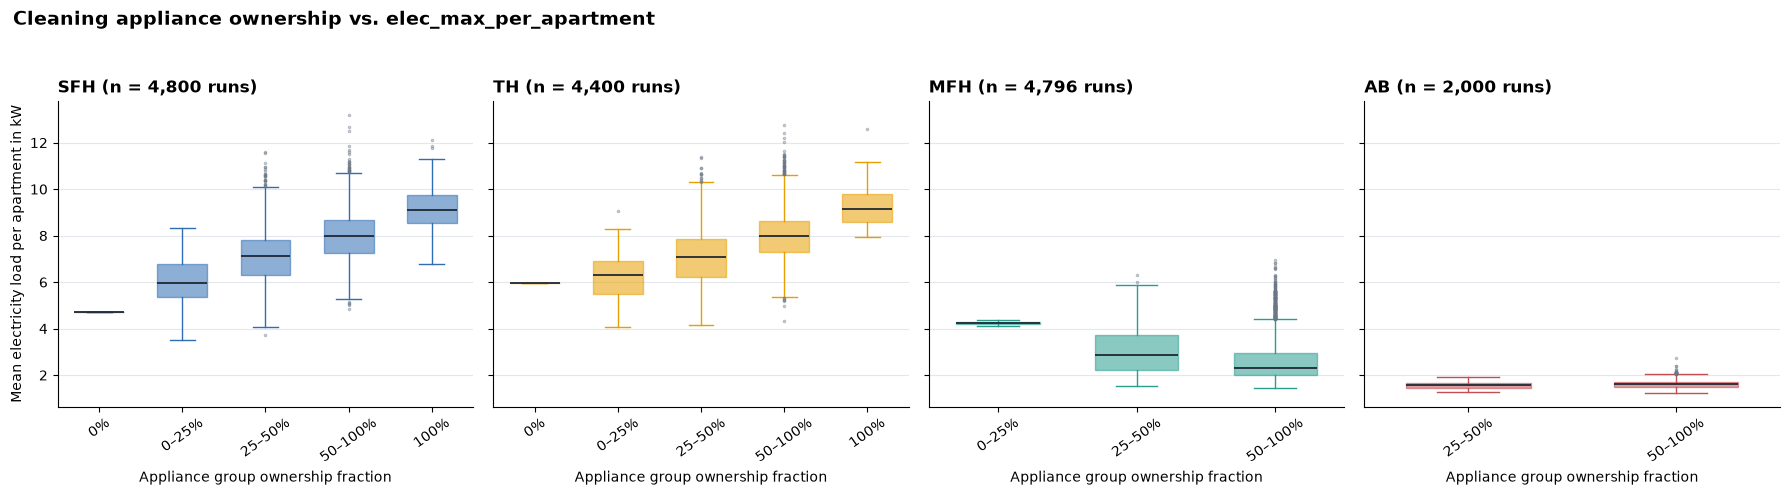

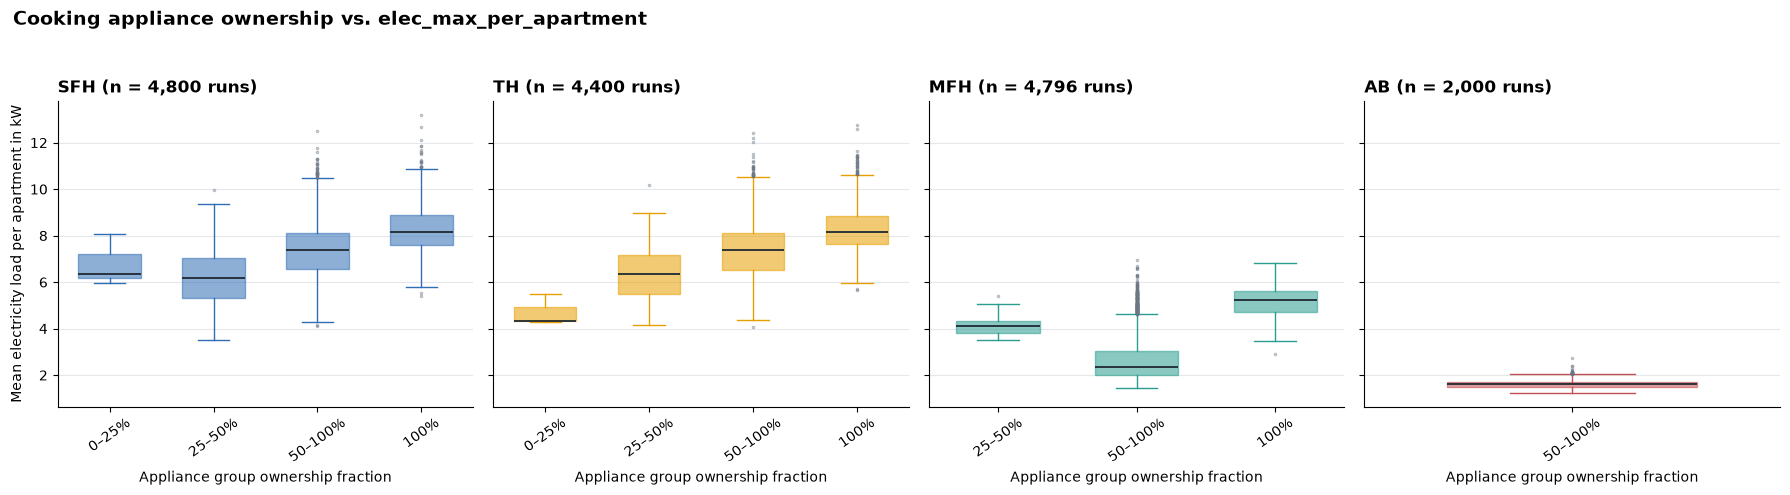

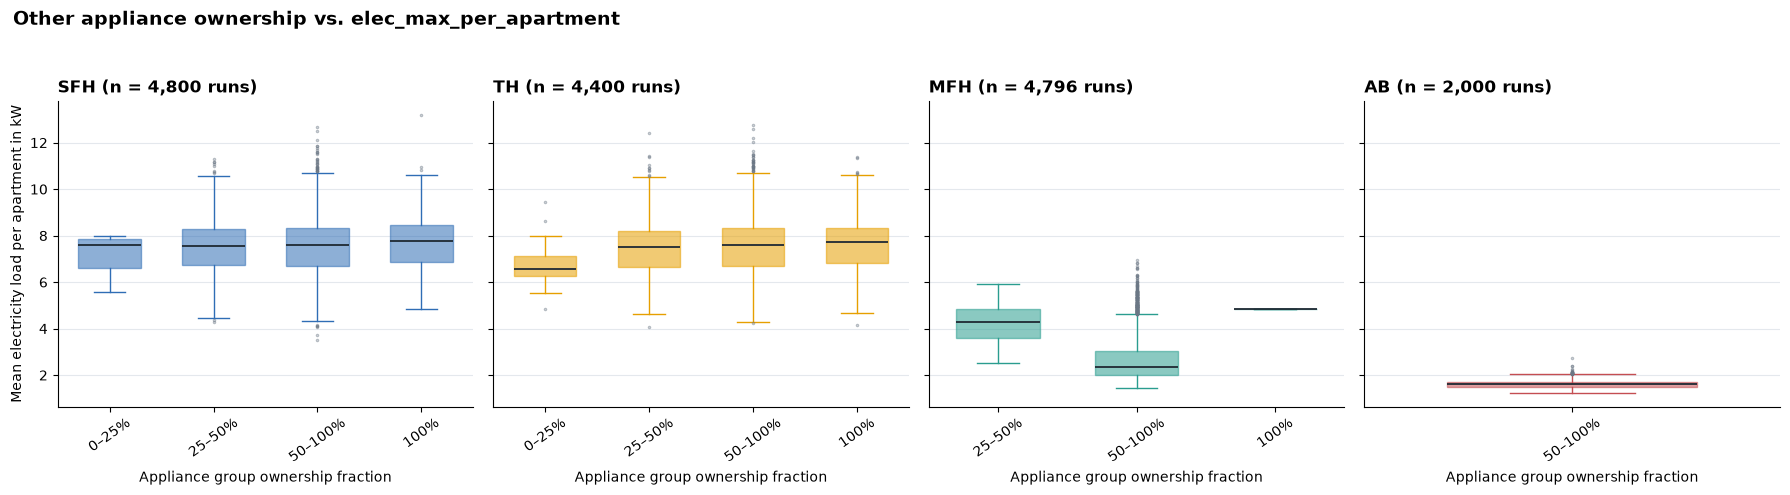

In [40]:
for group in APPLIANCE_GROUPS:
    plot_group_share_vs_metric(
        df,
        group=group,
        metric="elec_max_per_apartment"
    )

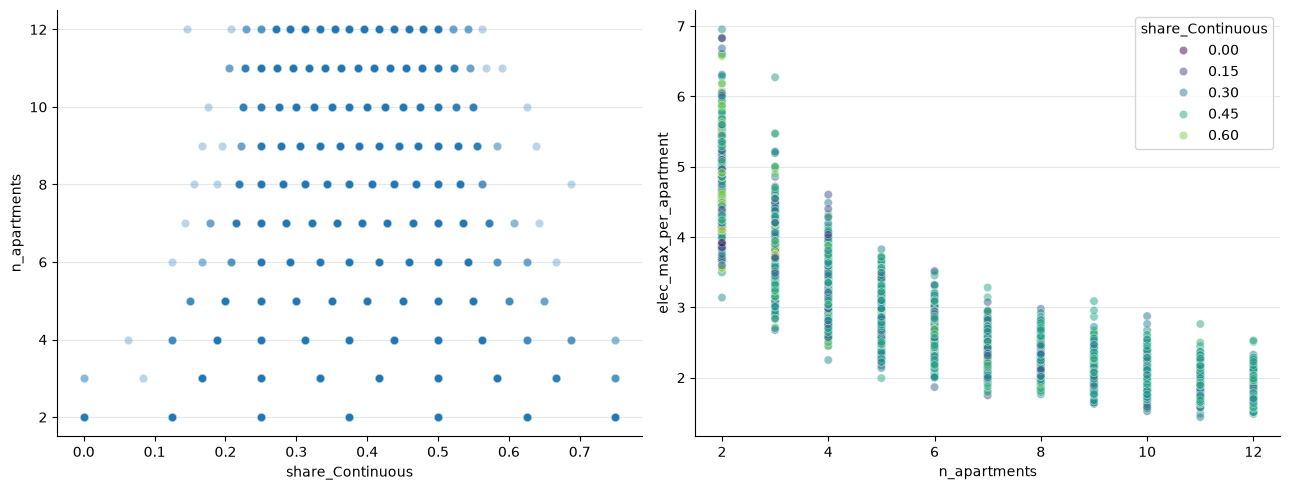

In [41]:

mfh = df[df["buildingType"] == "MFH"].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=mfh,
    x="share_Continuous",
    y="n_apartments",
    alpha=0.3,
    ax=axes[0]
)

sns.scatterplot(
    data=mfh,
    x="n_apartments",
    y="elec_max_per_apartment",
    hue="share_Continuous",
    palette="viridis",
    alpha=0.5,
    ax=axes[1]
)

for ax in axes:
    ax.grid(axis="y", color="#e4e8ed")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

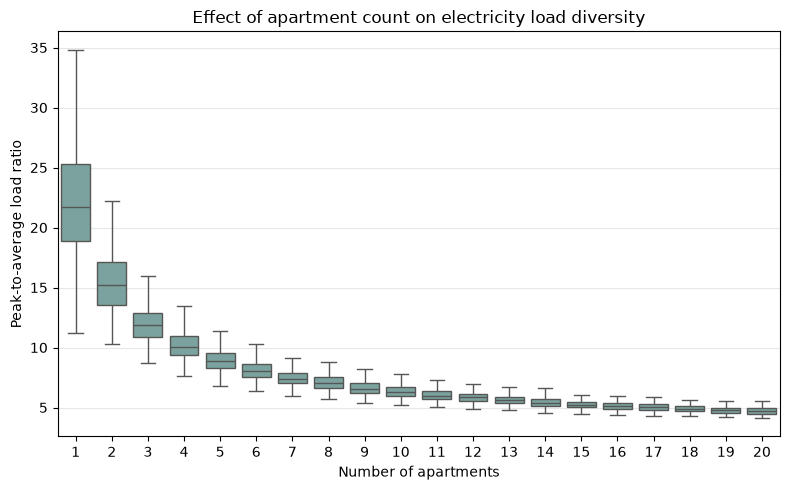

In [42]:
plot_simultaneity_effect(df)

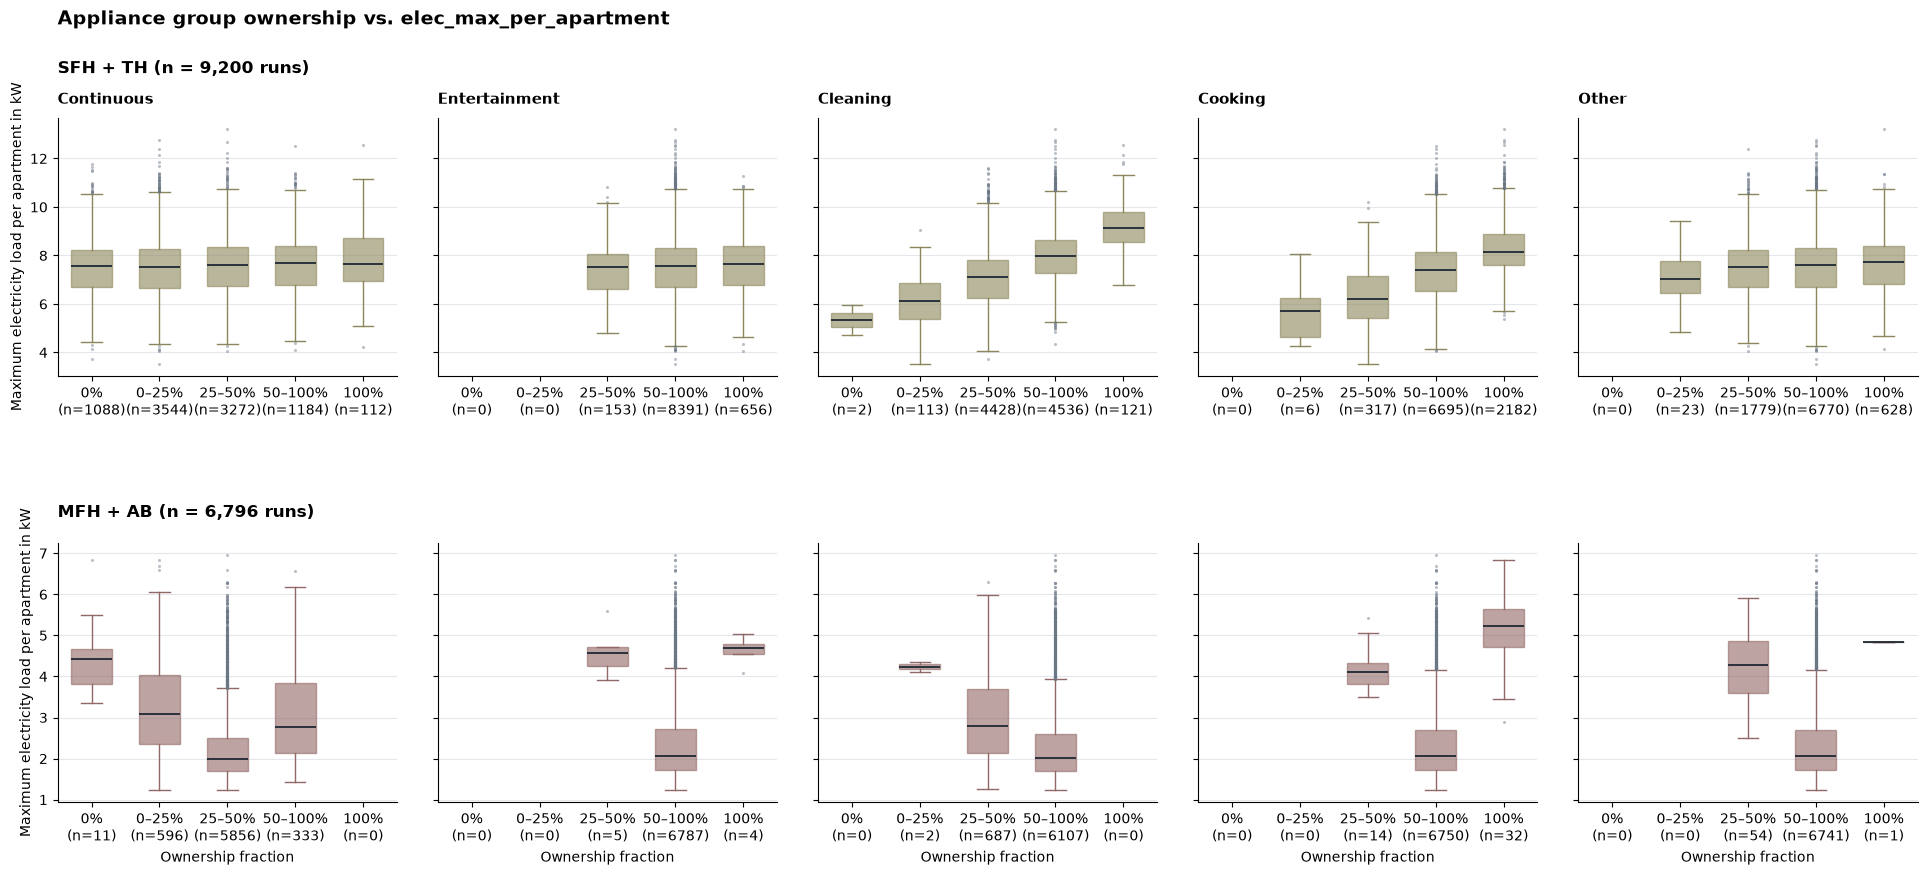

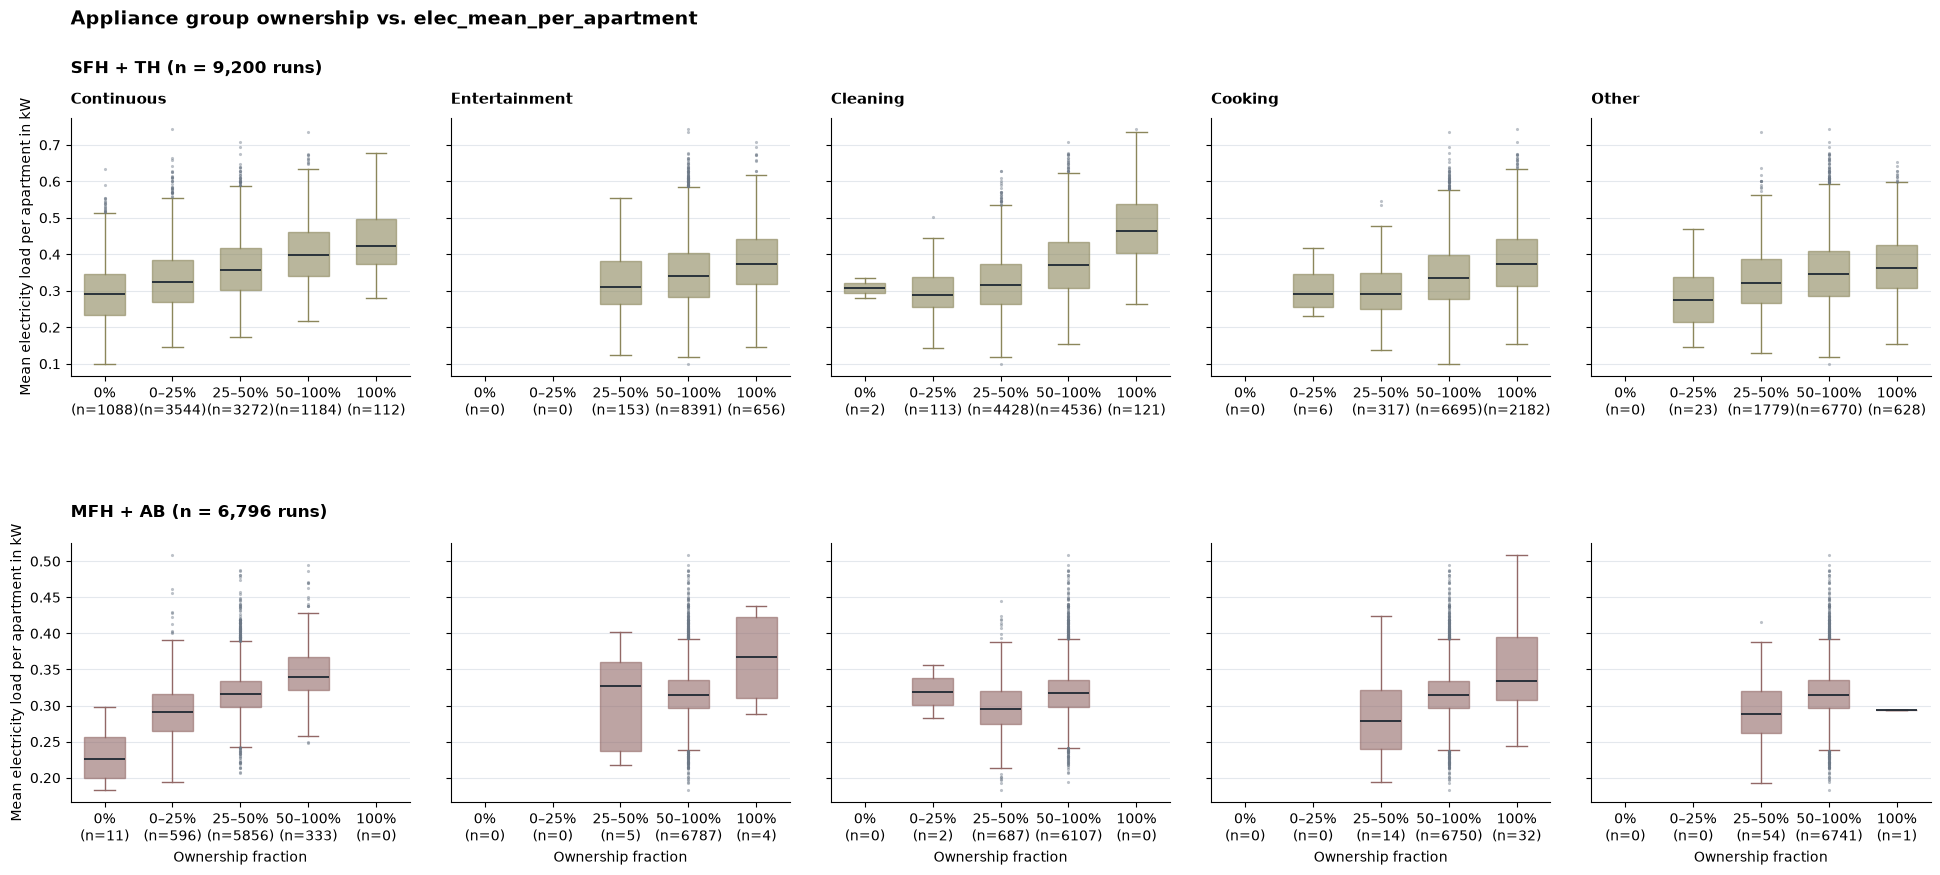

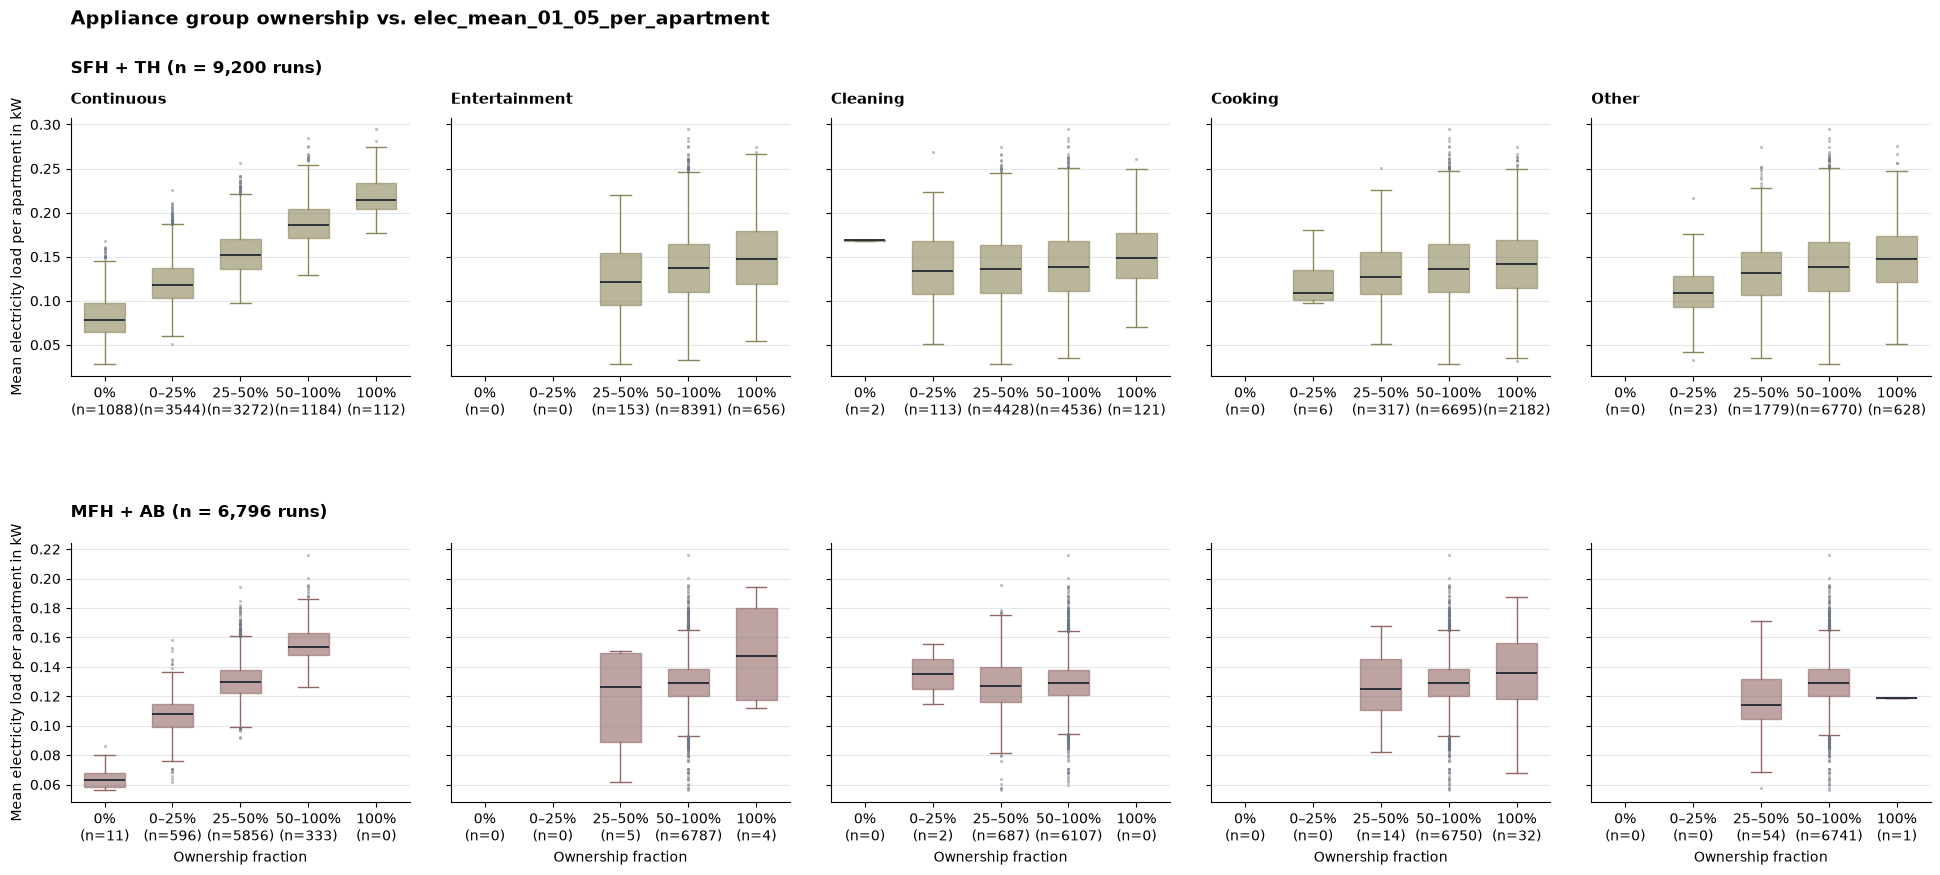

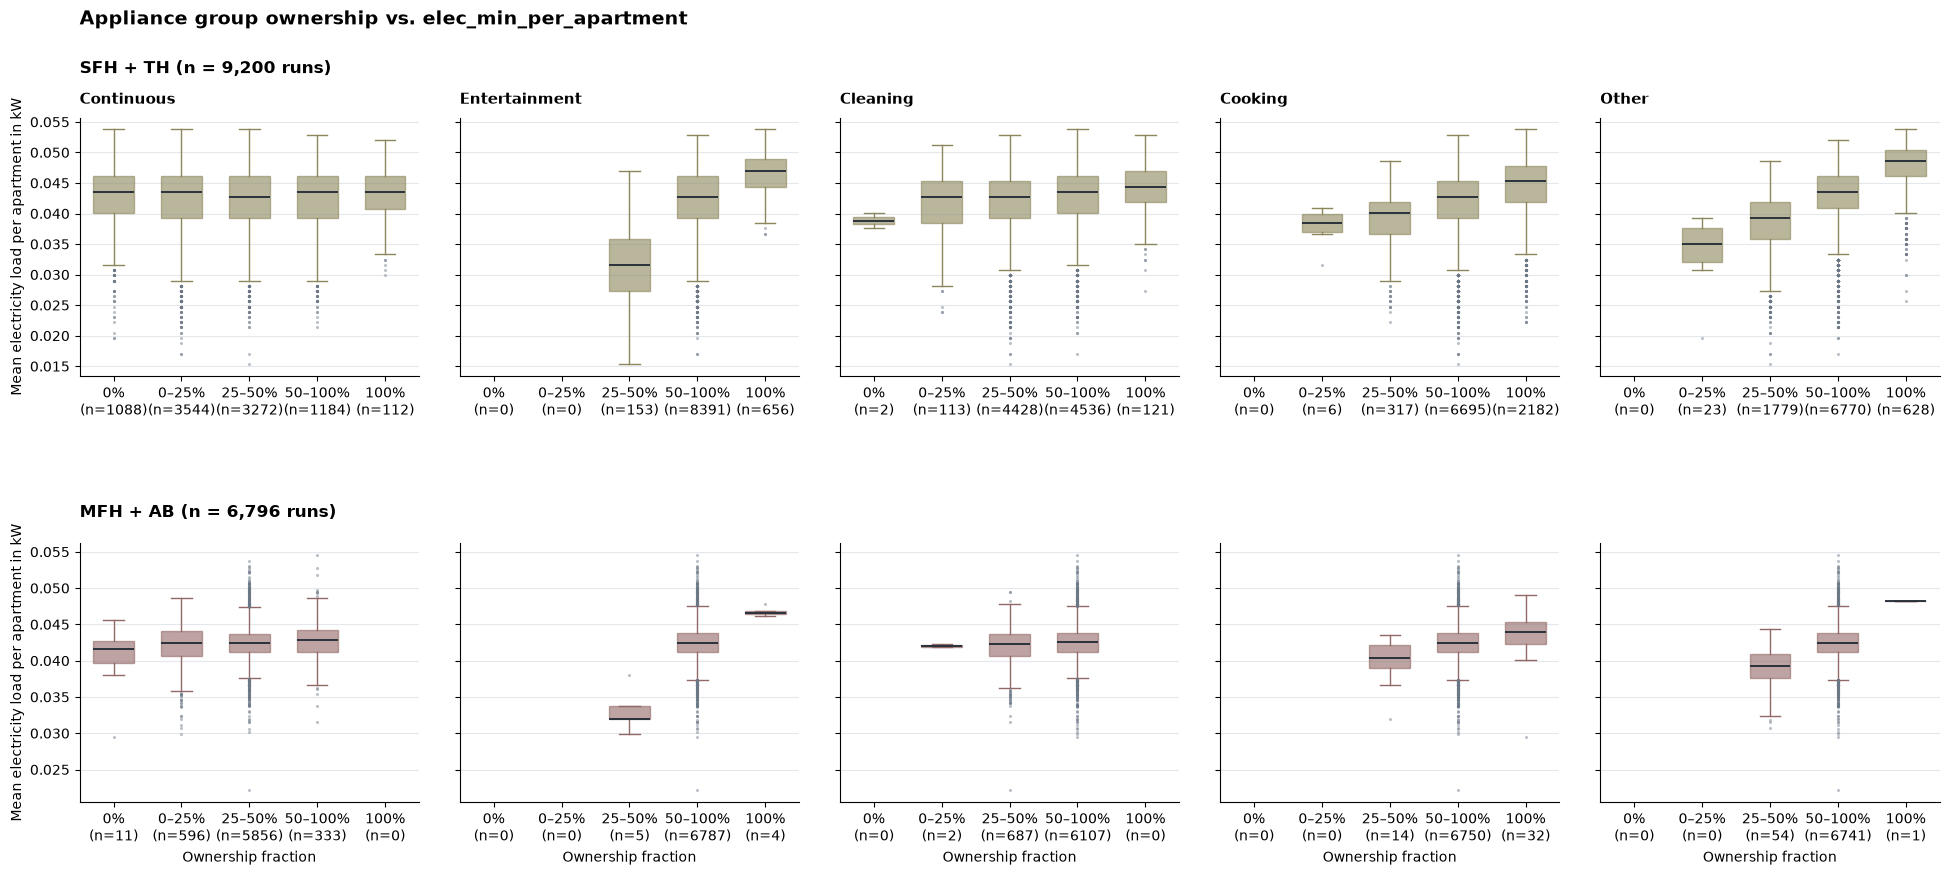

In [43]:
plot_appliance_groupshare_2x5(
    df,
    metric="elec_max_per_apartment",
    ylabel="Maximum electricity load per apartment in kW"
)

plot_appliance_groupshare_2x5(
    df,
    metric="elec_mean_per_apartment",
    ylabel="Mean electricity load per apartment in kW"
)

plot_appliance_groupshare_2x5(
    df,
    metric="elec_mean_01_05_per_apartment",
    ylabel="Mean electricity load per apartment in kW"
)

plot_appliance_groupshare_2x5(
    df,
    metric="elec_min_per_apartment",
    ylabel="Mean electricity load per apartment in kW"
)

## TRY Weather

In [44]:
path = r"C:\Users\Samuel\FH_Aachen\tsib_simuflex_fork\tsib_simuflex\tsib\data\weatherdata\TRY2015\01\TRY2015_532217077767_Jahr.dat"
weather = pd.read_csv(path, sep=r"\s+", skiprows=list(range(32)) + [33], skip_blank_lines=True,encoding="utf-8")
weather.index = pd.to_datetime({"year":2015, "month": weather["MM"],"day": weather["DD"],"hour": weather["HH"]-1})
weather.index.name = "datetime"

In [45]:
TRY_PATH = Path(r"C:\Users\Samuel\FH_Aachen\tsib_simuflex_fork\tsib_simuflex\tsib\data\weatherdata")
weather_df, mean_df=load_TRY_files(TRY_PATH)

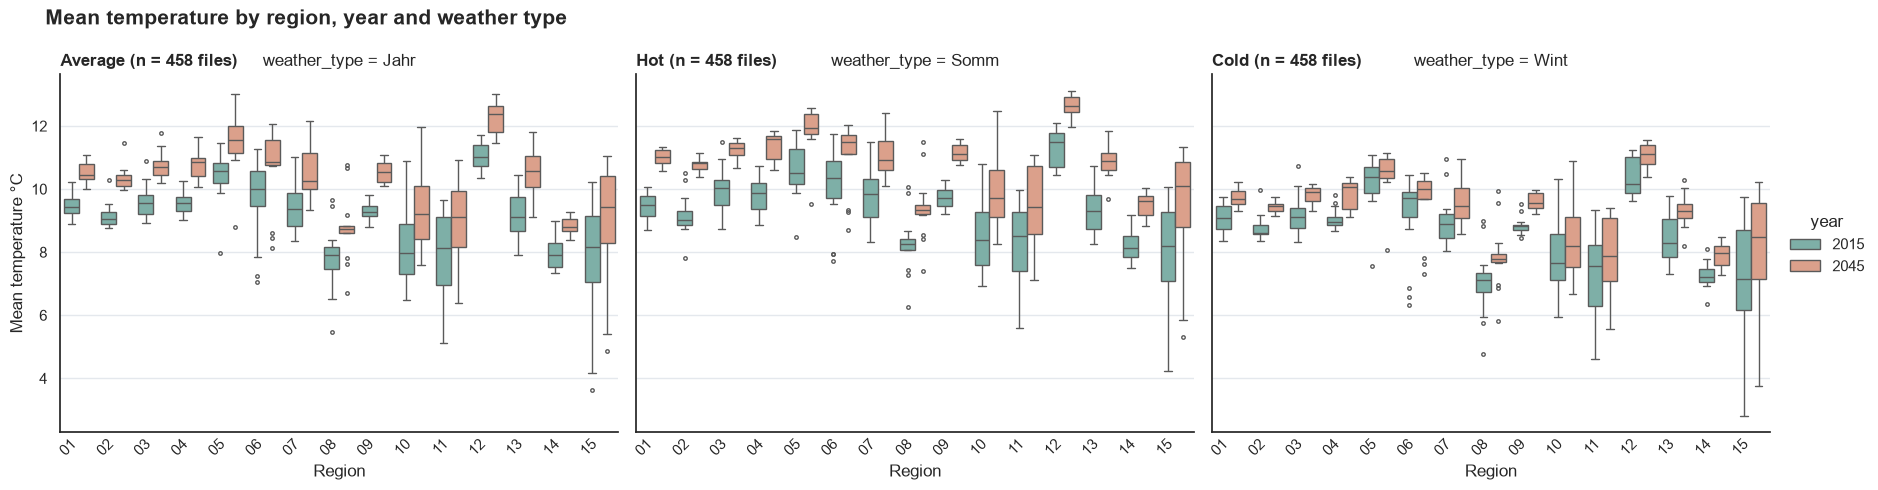

In [46]:
boxplot_TRY(mean_df)

In [47]:
mean_temp = weather_df.groupby(level=["year", "region", "weather_type", "file_id"])["t"].mean()
year_mean_temp = mean_temp.groupby(level=["year", "region", "weather_type"]).mean().unstack("year")
year_mean_temp["year_diff_K"] =year_mean_temp[2045] - year_mean_temp[2015]
type_mean_temp = mean_temp.groupby(level=["year", "region", "weather_type"]).mean().unstack("weather_type")
type_mean_temp["hot_vs_avg_K"] = type_mean_temp["Somm"] - type_mean_temp["Jahr"]
type_mean_temp["cold_vs_avg_K"] = type_mean_temp["Wint"] - type_mean_temp["Jahr"]
type_mean_temp["hot_vs_cold_K"] = type_mean_temp["Somm"] - type_mean_temp["Wint"]

In [48]:
#https://www.dwd.de/DE/service/lexikon/Functions/glossar.html?lv3=100912&lv2=100784
#https://www.dwd.de/DE/service/lexikon/Functions/glossar.html?lv3=101162&lv2=101094
daily_temp =weather_df.groupby(level=["year", "region", "weather_type", "file_id"]).resample("D",level="datetime")["t"].agg(["mean","min","max"])
day_counts = daily_temp.groupby(level=["year", "region", "weather_type", "file_id"]).agg(cold_days=("min",lambda x: (x <0).sum()), hot_days=("max",lambda x: (x >=30).sum()))
year_day_counts = day_counts.groupby(level=["year", "region", "weather_type"]).mean().unstack("year")
year_day_counts["cold_days_diff"] = year_day_counts["cold_days", 2045] - year_day_counts["cold_days", 2015]
year_day_counts["hot_days_diff"] =year_day_counts["hot_days", 2045] - year_day_counts["hot_days", 2015]
year_day_counts.columns = [f"{indicator}_{year}" if year != "" else indicator for indicator, year in year_day_counts.columns]
type_day_counts = day_counts.groupby(level=["year", "region", "weather_type"]).mean().unstack("weather_type")
for indicator in ["cold_days", "hot_days"]:
    type_day_counts[(indicator, "hot_vs_avg")] = type_day_counts[(indicator, "Somm")] - type_day_counts[(indicator, "Jahr")]
    type_day_counts[(indicator, "cold_vs_avg")] = type_day_counts[(indicator, "Wint")]- type_day_counts[(indicator, "Jahr")]

In [49]:
type_day_counts

cold_days                           hot_days             \
weather_type        Jahr        Somm        Wint       Jahr       Somm   
year region                                                              
2015 01        55.375000   70.062500   83.000000   0.812500   5.250000   
     02        64.533333   79.133333   94.066667   0.666667   3.533333   
     03        62.000000   79.400000   89.666667   1.800000   9.466667   
     04        78.800000   90.533333  100.066667   5.533333  15.533333   
     05        51.437500   61.375000   71.375000   4.625000  13.625000   
     06        66.562500   73.812500   85.937500   3.125000  10.812500   
     07        68.333333   81.133333   84.733333   3.133333  10.600000   
     08        97.000000   98.000000  117.071429   0.500000   3.714286   
     09        80.200000   83.733333   95.533333   3.200000  13.066667   
     10       104.066667   96.933333  109.866667   2.133333   7.266667   
     11       106.866667  105.800000  120.466667   1.400000   6.000000   
     12        56.000000   71.875000   80.687500   8.562500  21.625000   
     13        88.125000   96.125000  109.437500   3.187500  11.125000   
     14       102.400000  106.533333  122.600000   0.600000   3.933333   
     15       102.437500  102.312500  119.000000   0.500000   3.437500   
2045 01        32.437500   28.562500   56.625000   2.125000   2.750000   
     02        39.733333   35.466667   64.066667   1.666667   3.866667   
     03        41.466667   37.466667   67.533333   4.200000   8.933333   
     04        52.600000   47.266667   78.333333   7.800000  17.466667   
     05        32.250000   32.125000   54.812500   7.750000  13.937500   
     06        46.285714   45.142857   69.857143   5.285714  11.285714   
     07        46.266667   45.800000   69.466667   6.666667  12.466667   
     08        78.000000   75.428571  102.071429   2.142857   4.500000   
     09        51.133333   50.200000   77.866667   6.533333  13.466667   
     10        75.133333   72.666667  101.266667   4.400000  11.066667   
     11        81.466667   82.933333  109.533333   3.800000   8.066667   
     12        39.125000   37.812500   61.500000  19.187500  30.312500   
     13        63.250000   62.500000   92.437500  11.375000  19.375000   
     14        82.866667   78.266667  106.200000   1.933333   5.933333   
     15        78.750000   79.125000  101.375000   2.437500   5.687500   

                         cold_days               hot_days              
weather_type       Wint hot_vs_avg cold_vs_avg hot_vs_avg cold_vs_avg  
year region                                                            
2015 01        4.500000  14.687500   27.625000   4.437500    3.687500  
     02        3.266667  14.600000   29.533333   2.866667    2.600000  
     03        6.733333  17.400000   27.666667   7.666667    4.933333  
     04        8.133333  11.733333   21.266667  10.000000    2.600000  
     05       11.312500   9.937500   19.937500   9.000000    6.687500  
     06        5.062500   7.250000   19.375000   7.687500    1.937500  
     07        4.200000  12.800000   16.400000   7.466667    1.066667  
     08        0.928571   1.000000   20.071429   3.214286    0.428571  
     09        6.066667   3.533333   15.333333   9.866667    2.866667  
     10        4.600000  -7.133333    5.800000   5.133333    2.466667  
     11        2.333333  -1.066667   13.600000   4.600000    0.933333  
     12       12.000000  15.875000   24.687500  13.062500    3.437500  
     13        6.125000   8.000000   21.312500   7.937500    2.937500  
     14        1.533333   4.133333   20.200000   3.333333    0.933333  
     15        2.250000  -0.125000   16.562500   2.937500    1.750000  
2045 01        1.500000  -3.875000   24.187500   0.625000   -0.625000  
     02        0.733333  -4.266667   24.333333   2.200000   -0.933333  
     03        3.333333  -4.000000   26.066667   4.733333   -0.866667  
     04        6.666667  -5.333333   25.733333   9.666667   

In [50]:
type_day_counts.groupby(level="year").mean()

cold_days                        hot_days                       \
weather_type       Jahr       Somm       Wint      Jahr       Somm      Wint   
year                                                                           
2015          78.942500  86.450833  98.900595  2.651944   9.265952  5.269683   
2045          56.050992  54.050873  80.863016  5.820238  11.274325  3.868929   

              cold_days               hot_days              
weather_type hot_vs_avg cold_vs_avg hot_vs_avg cold_vs_avg  
year                                                        
2015           7.508333   19.958095   6.614008    2.617738  
2045          -2.000119   24.812024   5.454087   -1.951310

In [51]:
year_day_counts

cold_days_2015  cold_days_2045  hot_days_2015  \
region weather_type                                                  
01     Jahr               55.375000       32.437500       0.812500   
       Somm               70.062500       28.562500       5.250000   
       Wint               83.000000       56.625000       4.500000   
02     Jahr               64.533333       39.733333       0.666667   
       Somm               79.133333       35.466667       3.533333   
       Wint               94.066667       64.066667       3.266667   
03     Jahr               62.000000       41.466667       1.800000   
       Somm               79.400000       37.466667       9.466667   
       Wint               89.666667       67.533333       6.733333   
04     Jahr               78.800000       52.600000       5.533333   
       Somm               90.533333       47.266667      15.533333   
       Wint              100.066667       78.333333       8.133333   
05     Jahr               51.437500       32.250000       4.625000   
       Somm               61.375000       32.125000      13.625000   
       Wint               71.375000       54.812500      11.312500   
06     Jahr               66.562500       46.285714       3.125000   
       Somm               73.812500       45.142857      10.812500   
       Wint               85.937500       69.857143       5.062500   
07     Jahr               68.333333       46.266667       3.133333   
       Somm               81.133333       45.800000      10.600000   
       Wint               84.733333       69.466667       4.200000   
08     Jahr               97.000000       78.000000       0.500000   
       Somm               98.000000       75.428571       3.714286   
       Wint              117.071429      102.071429       0.928571   
09     Jahr               80.200000       51.133333       3.200000   
       Somm               83.733333       50.200000      13.066667   
       Wint               95.533333       77.866667       6.066667   
10     Jahr              104.066667       75.133333       2.133333   
       Somm               96.933333       72.666667       7.266667   
       Wint              109.866667      101.266667       4.600000   
11     Jahr              106.866667       81.466667       1.400000   
       Somm              105.800000       82.933333       6.000000   
       Wint              120.466667      109.533333       2.333333   
12     Jahr               56.000000       39.125000       8.562500   
       Somm               71.875000       37.812500      21.625000   
       Wint               80.687500       61.500000      12.000000   
13     Jahr               88.125000       63.250000       3.187500   
       Somm               96.125000       62.500000      11.125000   
       Wint              109.437500       92.437500       6.125000   
14     Jahr              102.400000       82.866667       0.600000   
       Somm              106.533333       78.266667       3.933333   
       Wint              122.600000      106.200000       1.533333   
15     Jahr              102.437500       78.750000       0.500000   
       Somm              102.312500       79.125000       3.437500   
       Wint              119.000000      101.375000       2.250000   

                     hot_days_2045  cold_days_diff  hot_days_diff  
region weather_type                                                
01     Jahr               2.125000      -22.937500       1.312500  
       Somm               2.750000      -41.500000      -2.500000  
       Wint               1.500000      -26.375000      -3.000000  
02     Jahr               1.666667      -24.800000       1.000000  
       Somm               3.866667      -43.666667       0.333333  
       Wint               0.733333      -30.000000      -2.533333  
03     Jahr               4.200000      -20.533333       2.400000  
       Somm               8.933333      -41.933333      -0.533333  
       Wint               3.333333      -22.133333

In [52]:
year_day_counts.groupby(level="weather_type")[["cold_days_2015", "hot_days_2015","cold_days_2045", "hot_days_2045"]].mean()

,cold_days_2015,hot_days_2015,cold_days_2045,hot_days_2045
weather_type,,,,
Jahr,78.942500,2.651944,56.050992,5.820238
Somm,86.450833,9.265952,54.050873,11.274325
Wint,98.900595,5.269683,80.863016,3.868929


In [53]:
year_mean_temp.groupby(level="weather_type")["year_diff_K"].mean()

weather_type
Jahr    1.129848
Somm    1.390585
Wint    0.672501
Name: year_diff_K, dtype: float64

In [54]:
type_mean_temp.groupby(level="year")[["hot_vs_avg_K", "cold_vs_avg_K", "hot_vs_cold_K"]].mean()

weather_type,hot_vs_avg_K,cold_vs_avg_K,hot_vs_cold_K
year,,,
2015,0.235089,-0.535059,0.770148
2045,0.495825,-0.992406,1.488232


In [55]:
year_mean_temp.xs("Jahr", level="weather_type")

year,2015,2045,year_diff_K
region,,,
01,9.457989,10.554326,1.096336
02,9.147190,10.330139,1.182948
03,9.606291,10.738473,1.132182
04,9.569843,10.797662,1.227819
05,10.466523,11.542485,1.075962
06,9.678745,10.647021,0.968276
07,9.393457,10.537572,1.144115
08,7.775127,8.758862,0.983735
09,9.308556,10.557071,1.248515


In [56]:
year_mean_temp.xs("Jahr", level="weather_type")["year_diff_K"].mean()

np.float64(1.1298483112270785)

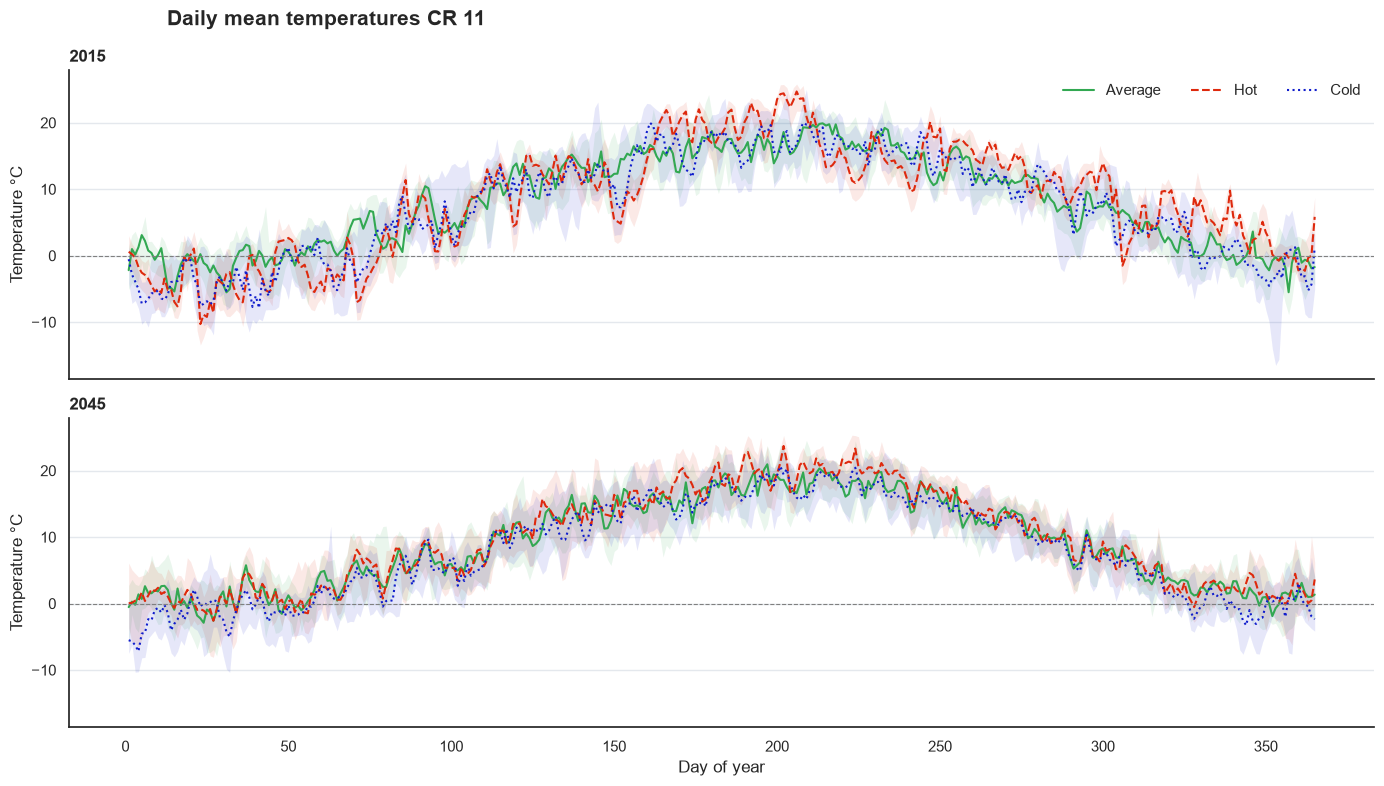

In [57]:
plot_TRYs(weather_df, "11")

## Timeseries Analysis

In [3]:
DATA_PATH = Path(r"..\DataSplit\Data\test")

files = DATA_PATH.glob("*.h5")

In [4]:
existing_files = []
for file in list(files):
    existing_files.append(file.stem)
manifest_subset = manifest[manifest["run_id"].isin(existing_files)]

In [5]:
manifest_subset = manifest[manifest["run_id"].isin(existing_files)]

In [6]:
manifest_subset.groupby("buildingType").size()

buildingType
AB     57
MFH    52
SFH    66
TH     49
dtype: int64

In [44]:
# from pathlib import Path
# import pandas as pd
# from tqdm.auto import tqdm
#
# INPUT_DIR = Path(r"../data/split/val")
# OUTPUT_DIR = Path(r"..\data\raw\Generation/parquet")
#
# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
#
# h5_files = sorted(INPUT_DIR.glob("*.h5"))
# print(f"Found {len(h5_files)} HDF5 files")
#
# for h5_file in tqdm(h5_files, desc="Converting files"):
#
#     run_id = h5_file.stem
#     output_path = OUTPUT_DIR / f"{run_id}.parquet"
#
#     if output_path.exists():
#         continue
#
#     df = pd.read_hdf(
#         h5_file,
#         key="timeseries"
#     )
#
#     df.index.name = "timestamp"
#     df = df.reset_index()
#     df.insert(0, "run_id", run_id)
#     df.to_parquet(
#         output_path,
#         engine="pyarrow",
#         compression="zstd",
#         index=False
#     )
#     del df
#
# print("Conversion complete!")

Found 2000 HDF5 files


Converting files:   0%|          | 0/2000 [00:00<?, ?it/s]

Conversion complete!


In [22]:
import polars as pl

lf = pl.scan_parquet(r"../data/split/test/parquet/*.parquet")

print(lf.collect_schema())

Schema({'run_id': String, 'timestamp': Datetime(time_unit='us', time_zone='Europe/Berlin'), 'T': Float32, 'Occupancy Home Active': Float32, 'Occupancy Home Not Active': Float32, 'Electricity Load': Float32, 'Hot Water Load': Float32, 'Heating Load': Float32, 'Off Day': Int8})


In [9]:
run = lf.filter(pl.col("run_id") == "run_000244").collect()

In [10]:
run

run_id,timestamp,T,Occupancy Home Active,Occupancy Home Not Active,Electricity Load,Hot Water Load,Heating Load,Off Day
str,"datetime[μs, Europe/Berlin]",f32,f32,f32,f32,f32,f32,i8


In [11]:
summary = lf.group_by("run_id").agg(
        pl.col("Heating Load").mean().alias("mean_heating"),
        pl.col("Heating Load").max().alias("max_heating"),
        pl.col("Electricity Load").mean().alias("mean_elec"),
    ).collect()


In [12]:
FRACTIONS = ["active_fraction","inactive_fraction","home_fraction"]

PROFILES = {
    "Heating Load": {"label": "Heating Load [kW]","color": "#CC071E"},
    "Hot Water Load":{"label": "Hot Water Load [kW]", "color": "#F6A800"},
    "Electricity Load":{"label": "Electricity Load [kW]", "color": "#57AB27"},
    "T":{"label": "Temperature [°C]", "color": "#00549F"},
    "active_fraction": {"label": "Home, active","color": "#239D8D"},
    "inactive_fraction": {"label": "Home, not active","color": "#A8DADC"},
    "home_fraction": {"label": "Total home occupancy","color": "#00549F"}
}


In [13]:
{k: v for k,v in PROFILES.items() if k in FRACTIONS}

{'active_fraction': {'label': 'Home, active', 'color': '#239D8D'},
 'inactive_fraction': {'label': 'Home, not active', 'color': '#A8DADC'},
 'home_fraction': {'label': 'Total home occupancy', 'color': '#00549F'}}

In [14]:
PROFILES["active_fraction"]["color"]

'#239D8D'

In [15]:
def plot_run(run_id,resolution="15m",start=None,end=None,duration=None,data_dir=r"..\DataSplit\Data\train\parquet"):

    path = Path(data_dir) / f"{run_id}.parquet"

    tz = ZoneInfo("Europe/Berlin")
    lf = pl.scan_parquet(path)

    if start is not None:
        start_dt = datetime.fromisoformat(start)
        if start_dt.tzinfo is None:
            start_dt = start_dt.replace(tzinfo=tz)
        lf = lf.filter(pl.col("timestamp") >= start_dt)

    if end is not None:
        end_dt = datetime.fromisoformat(end)
        if end_dt.tzinfo is None:
            end_dt = end_dt.replace(tzinfo=tz)
        lf = lf.filter(pl.col("timestamp") < end_dt)

    if duration is not None and end is None:
        first_timestamp = lf.select(pl.col("timestamp").min()).collect().item()
        lf = lf.filter(pl.col("timestamp") < (pl.lit(first_timestamp).dt.offset_by(duration)))

    if resolution != "1m":
        lf = lf.sort("timestamp").group_by_dynamic("timestamp",every=resolution).agg(
                pl.col("Heating Load").mean(),
                pl.col("Electricity Load").mean(),
                pl.col("Hot Water Load").mean(),
                pl.col("T").mean(),
                pl.col("Occupancy Home Active").mean(),
                pl.col("Occupancy Home Not Active").mean(),
                pl.col("Off Day").max(),
            )

    df = lf.collect().sort("timestamp").to_pandas()

    fig, axes = plt.subplots(5, 1,figsize=(10, 10),sharex=True,constrained_layout=True)

    time = df["timestamp"]
    axes[0].set_ylabel("Heating Load")
    axes[0].set_title("Space Heating")
    axes[1].set_ylabel("Electricity Load")
    axes[1].set_title("Electricity")
    axes[2].set_ylabel("Hot Water Load")
    axes[2].set_title("Domestic Hot Water")

    active = df["Occupancy Home Active"].to_numpy()
    inactive = df["Occupancy Home Not Active"].to_numpy()
    total = active + inactive
    axes[3].fill_between(time,0,active,step="post",alpha=0.9,color=PROFILES["active_fraction"]["color"],label="home, active")
    axes[3].fill_between(time,active,total,step="post",alpha=0.6,color=PROFILES["inactive_fraction"]["color"],label="home, not active")
    axes[3].set_ylabel("Occupants")
    axes[3].set_title("Occupancy")
    axes[3].grid(axis="y", color="#e4e8ed")
    axes[3].set_axisbelow(True)
    axes[3].spines[["top", "right"]].set_visible(False)
    axes[3].legend(loc="upper right")

    axes[4].set_ylabel("Temperature")
    axes[4].set_title("Temperature")
    axes[4].set_xlabel("Time")

    axis_mapping = {0: "Heating Load",1: "Electricity Load",2: "Hot Water Load",4: "T"}

    for ax_idx, variable in axis_mapping.items():
        style = PROFILES[variable]
        axes[ax_idx].plot(time,df[variable],color=style["color"],linewidth=0.8)
        axes[ax_idx].set_ylabel(style["label"])
        axes[ax_idx].set_title(variable)
        axes[ax_idx].grid(axis="y", color="#e4e8ed")
        axes[ax_idx].set_axisbelow(True)

    for ax in axes:
         ax.grid(alpha=0.6)
    fig.suptitle(f"{run_id} | {resolution} resolution",fontsize=15)
    plt.show()

In [16]:
manifest

,country,buildingType,surrounding,buildingAgeBin,a_ref,n_apartments,year_type,future,climateRegion,n_persons,...,apartment_seeds,appliances,maxLoadViolation_kW,runtime_seconds,resolved_year,a0,n_persons_sum,appliances_unique,building_id,run_id
0,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,"[1341242, 2161857, 7980730, 3141875, 8938643, ...","[['UPRIGHT_FREEZER', 'ANSWER_MACHINE', 'CD_PLA...",1.199826e-12,499.115650,2018,829.4,28,"['UPRIGHT_FREEZER', 'ANSWER_MACHINE', 'CD_PLAY...",0,run_000000
1,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,"[7816614, 6767105, 9804180, 7763681, 9544759, ...","[['FRIDGE_FREEZER', 'FRIDGE', 'ANSWER_MACHINE'...",7.823896e-12,510.517424,2021,829.4,28,"['FRIDGE_FREEZER', 'FRIDGE', 'ANSWER_MACHINE',...",0,run_000001
2,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,"[5393235, 3905184, 5287101, 2391082, 5770489, ...","[['FRIDGE', 'ANSWER_MACHINE', 'CD_PLAYER', 'CL...",4.607891e-11,516.505850,2023,829.4,28,"['FRIDGE', 'ANSWER_MACHINE', 'CD_PLAYER', 'CLO...",0,run_000002
3,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,"[4220299, 2206534, 5895420, 6297306, 4210654, ...","[['FRIDGE', 'ANSWER_MACHINE', 'CLOCK', 'PHONE'...",8.762075e-12,511.170801,2025,829.4,28,"['FRIDGE', 'ANSWER_MACHINE', 'CLOCK', 'PHONE',...",0,run_000003
4,DE,AB,Terraced,DE.02,1728.922,18,average,False,6,"[2, 4, 2, 1, 1, 1, 1, 2, 1, 2, 2, 2, 1, 3, 2, ...",...,"[5649322, 6969250, 429204, 9004735, 194318, 10...","[['CHEST_FREEZER', 'FRIDGE_FREEZER', 'ANSWER_M...",1.574334e-11,637.389653,2018,829.4,31,"['CHEST_FREEZER', 'FRIDGE_FREEZER', 'ANSWER_MA...",1,run_000004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15991,DE,TH,Semi,DE.12,116.166,1,hot,False,3,[3],...,[8387292],"[['FRIDGE', 'CD_PLAYER', 'CLOCK', 'HIFI', 'VAC...",2.428413e-12,57.692023,2025,195.8,3,"['FRIDGE', 'CD_PLAYER', 'CLOCK', 'HIFI', 'VACU...",3998,run_015995
15992,DE,TH,Semi,DE.12,121.971,1,average,False,12,[2],...,[2521613],"[['FRIDGE_FREEZER', 'ANSWER_MACHINE', 'CD_PLAY...",1.949353e-12,54.153805,2018,195.8,2,"['FRIDGE_FREEZER', 'ANSWER_MACHINE', 'CD_PLAYE...",3999,run_015996
15993,DE,TH,Semi,DE.12,121.971,1,average,False,12,[2],...,[7075494],"[['FRIDGE_FREEZER', 'ANSWER_MACHINE', 'CD_PLAY...",1.318639e-14,50.590619,2021,195.8,2,"['FRIDGE_FREEZER', 'ANSWER_MACHINE', 'CD_PLAYE...",3999,run_015997
15994,DE,TH,Semi,DE.12,121.971,1,average,False,12,[2],...,[4608605],"[['FRIDGE', 'ANSWER_MACHINE', 'CD_PLAYER', 'CL...",1.656028e-14,49.226107,2023,195.8,2,"['FRIDGE', 'ANSWER_MACHINE', 'CD_PLAYER', 'CLO...",3999,run_015998


In [17]:
pd.read_hdf(r"C:\Users\Samuel\FH_Aachen\MasterThesis\Master_Thesis_EWI_2026\DataSplit\Data\test\run_015630.h5", key="params")

,country,buildingType,surrounding,buildingAgeBin,a_ref,n_apartments,year_type,future,climateRegion,n_persons,...,resolved_climateRegion,resolved_latitude,resolved_longitude,state_seed,apartment_seeds,appliances,maxLoadViolation_kW,runtime_seconds,resolved_year,a0
0,DE,TH,Semi,DE.12,169.14,1,hot,True,1,[4],...,1,53.5407,8.6034,1015630,[2277397],"[[""CHEST_FREEZER"", ""FRIDGE_FREEZER"", ""FRIDGE"",...",3.553819e-12,51.914524,2023,195.8


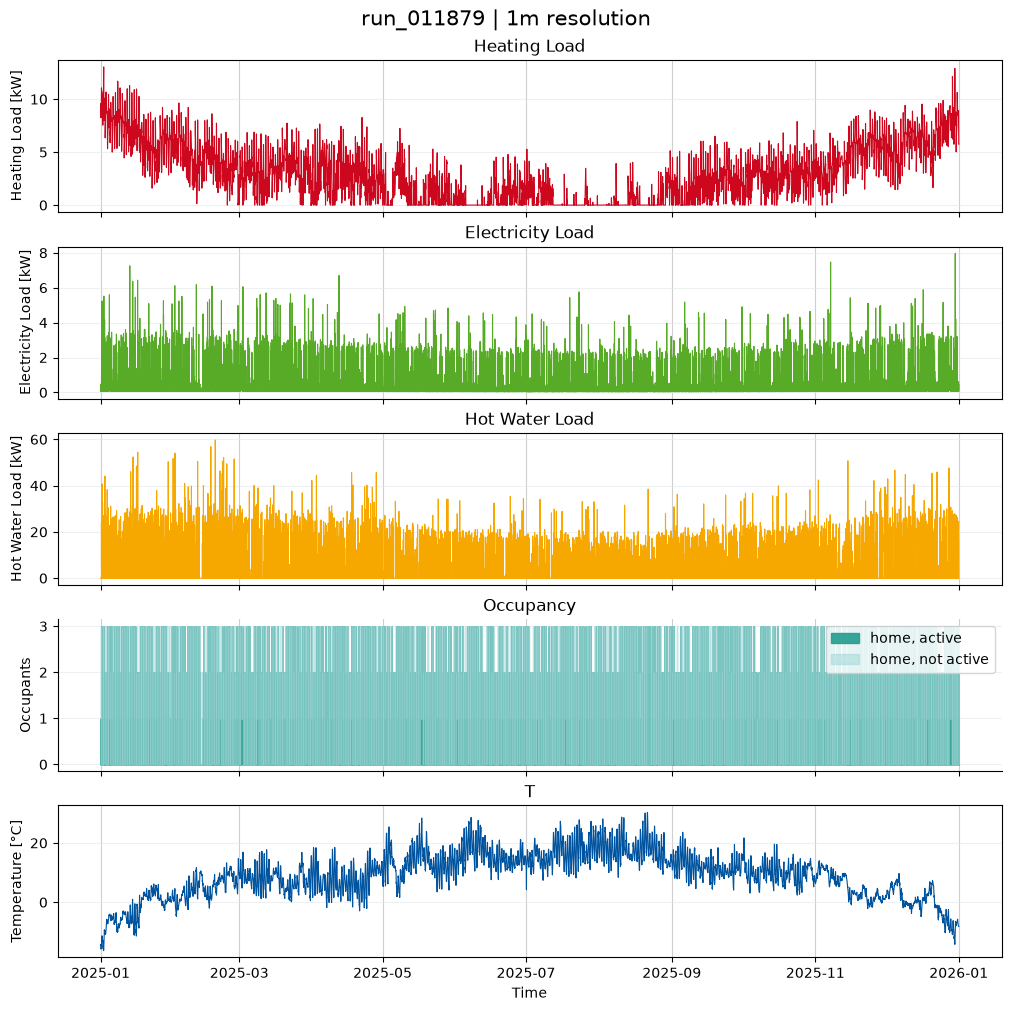

In [75]:
plot_run("run_011879",resolution="1m",duration="1y",data_dir=r"..\DataSplit\Data\train\parquet")

In [23]:
lf = pl.scan_parquet(r"..\DataSplit\Data\train\parquet\*.parquet")
meta = pl.read_csv("../Ch_1_Data_Preparation/run_20261011/realized_manifest_cleaned.csv").select("run_id","n_persons_sum").lazy()

def disp_weekday_effect_occ(lf, meta):
    data = lf.select("run_id","timestamp","Occupancy Home Active","Occupancy Home Not Active","Off Day").join(meta, on="run_id", how="left", validate="m:1").filter(pl.col("n_persons_sum") > 0).with_columns(
        (
            pl.col("Occupancy Home Active")
            / pl.col("n_persons_sum")
        ).alias("active_fraction"),

        (
            pl.col("Occupancy Home Not Active")
            / pl.col("n_persons_sum")
        ).alias("inactive_fraction"),

        (
            (
                pl.col("Occupancy Home Active")
                + pl.col("Occupancy Home Not Active")
            ) / pl.col("n_persons_sum")
        ).alias("home_fraction"),

        (
            pl.col("timestamp").dt.hour().cast(pl.Int32) * 60
            + pl.col("timestamp").dt.minute().cast(pl.Int32)
        ).alias("minute_of_day")
    )

    FRACTIONS = ["active_fraction","inactive_fraction","home_fraction"]
    OCCUPANCY_PROFILES = {k: v for k,v in PROFILES.items() if k in FRACTIONS}
    DAY_STYLES = {0: {"label": "Regular day", "linestyle": "-"},1: {"label": "Off-day", "linestyle": "--"}}

    run_profiles = data.group_by(["run_id", "Off Day", "minute_of_day"]).agg([pl.col(col).mean().alias(col) for col in FRACTIONS])

    profile = run_profiles.group_by(["Off Day", "minute_of_day"]).agg([pl.col(col).mean().alias(col) for col in FRACTIONS]).sort(["Off Day", "minute_of_day"]).with_columns((pl.col("minute_of_day") / 60.0).alias("hour")).collect(engine="streaming")

    fig, axes = plt.subplots(3, 1,figsize=(7, 7),sharex=True,constrained_layout=True)

    for ax, (variable, style) in zip(axes, OCCUPANCY_PROFILES.items()):
        for off_day, day_style in DAY_STYLES.items():
            subset = profile.filter(pl.col("Off Day") == off_day)
            ax.plot(
                subset["hour"].to_numpy(),
                subset[variable].to_numpy(),
                color=style["color"],
                linestyle=day_style["linestyle"],
                linewidth=2,
                label=day_style["label"]
            )

        ax.set_ylabel("Fraction of residents")
        ax.set_title(style["label"])
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.25)
        ax.legend()

    axes[-1].set_xlabel("Hour of day")
    axes[-1].set_xlim(0, 24)
    axes[-1].set_xticks(np.arange(0, 25, 2))

    fig.suptitle("Occupancy profiles: week-days vs. off-days",fontsize=15)

    plt.show()


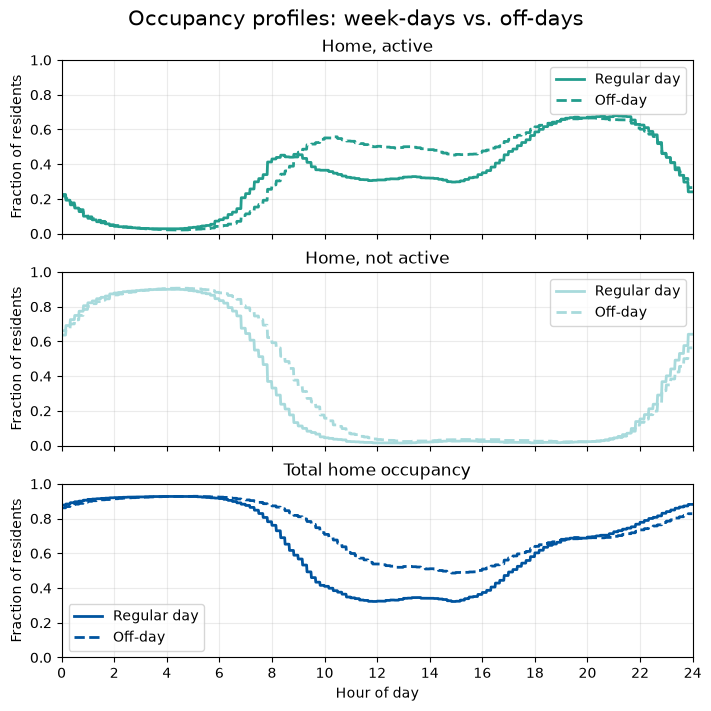

In [24]:
disp_weekday_effect_occ(lf, meta)

In [25]:

def disp_occupancy_carpet(
    lf,
    meta,
    n_days=100,
    occupancy="active",
    day_type="weekday",
    seed=42,
):
    OCC_COLS = {
        "active": "Occupancy Home Active",
        "inactive": "Occupancy Home Not Active",
        "home": None,
    }

    if occupancy not in OCC_COLS:
        raise ValueError("occupancy must be 'active', 'inactive', or 'home'")
    if day_type not in ("weekday", "offday"):
        raise ValueError("day_type must be 'weekday' or 'offday'")

    off_day = 0 if day_type == "weekday" else 1

    # 1. Prepare data
    data = (
        lf.select(
            "run_id",
            "timestamp",
            "Occupancy Home Active",
            "Occupancy Home Not Active",
            "Off Day",
        )
        .filter(pl.col("Off Day") == off_day)
        .join(meta, on="run_id", how="left", validate="m:1")
        .filter(pl.col("n_persons_sum") > 0)
        .with_columns(
        pl.col("timestamp").dt.date().alias("date"),
        (
            pl.col("timestamp").dt.hour().cast(pl.Int32) * 60
            + pl.col("timestamp").dt.minute().cast(pl.Int32)
        ).alias("minute_of_day"),
    )
    )

    # 2. Select occupancy variable
    if occupancy == "home":
        occ_expr = (
            pl.col("Occupancy Home Active")
            + pl.col("Occupancy Home Not Active")
        )
    else:
        occ_expr = pl.col(OCC_COLS[occupancy])

    data = data.with_columns(
        (occ_expr / pl.col("n_persons_sum")).alias("fraction")
    )

    # 3. Sample random (run_id, date) combinations
    available_days = (
        data.select("run_id", "date")
        .unique()
        .collect(engine="streaming")
    )

    sampled_days = available_days.sample(
        n=min(n_days, available_days.height),
        seed=seed,
        shuffle=True,
    ).with_row_index("day_idx")

    if sampled_days.is_empty():
        raise ValueError("No days available for this selection.")

    # 4. Collect only selected days
    selected = (
        data.join(
            sampled_days.lazy(),
            on=["run_id", "date"],
            how="inner",
        )
        .group_by(["day_idx", "minute_of_day"])
        .agg(pl.col("fraction").mean())
        .collect(engine="streaming")
    )

    # 5. Build carpet matrix (minutes x sampled days)
    matrix = np.full(
        (1440, sampled_days.height),
        np.nan,
        dtype=np.float32,
    )

    minutes = selected["minute_of_day"].to_numpy().astype(int)
    days = selected["day_idx"].to_numpy().astype(int)
    values = selected["fraction"].to_numpy()

    matrix[minutes, days] = values

    # 6. Plot
    fig, ax = plt.subplots(
        figsize=(max(8, 10), 6),
        constrained_layout=True,
    )

    im = ax.imshow(
        matrix,
        aspect="auto",
        origin="upper",
        interpolation="nearest",
        cmap="viridis",
        vmin=0,
        vmax=1,
        extent=[0, sampled_days.height, 24, 0],
    )

    ax.set_xlabel("Randomly sampled days")
    ax.set_ylabel("Hour of day")
    ax.set_yticks(np.arange(0, 25, 2))
    ax.set_title(
        f"Occupancy carpet: {occupancy} | {day_type} "
        f"(n={sampled_days.height} days)"
    )

    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label("Fraction of residents")

    plt.show()

    return matrix, sampled_days


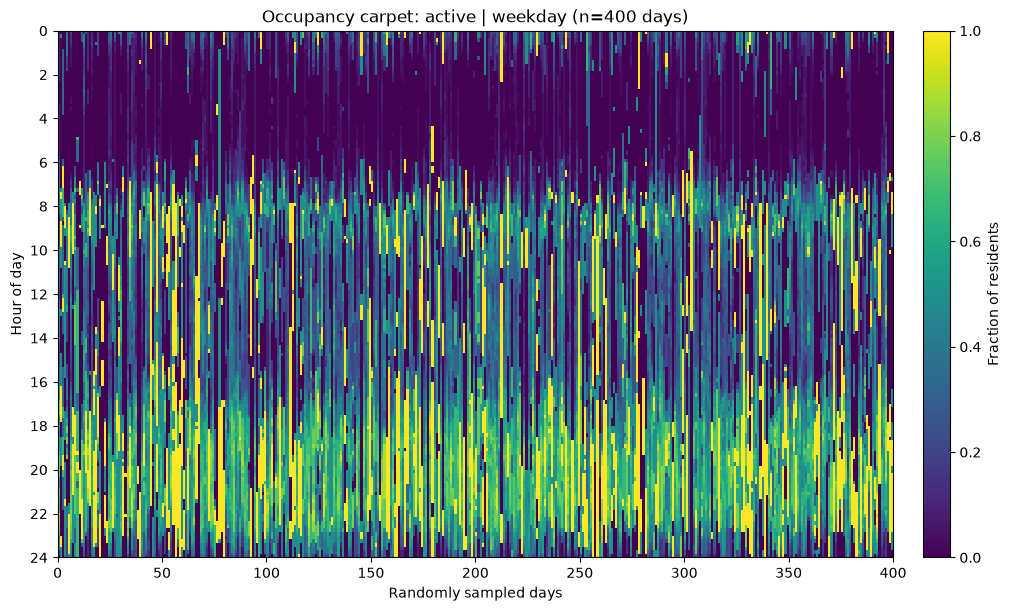

In [26]:
matrix, days = disp_occupancy_carpet(
    lf, meta,
    n_days=400,
    occupancy="active",
    day_type="weekday",
    seed=42,
)


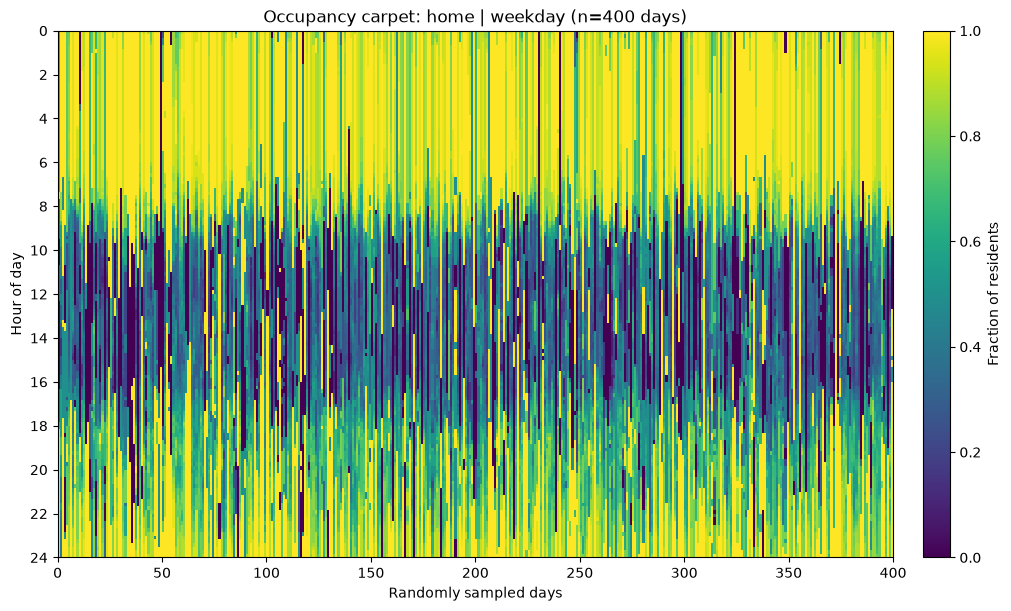

In [27]:
matrix, days = disp_occupancy_carpet(
    lf, meta,
    n_days=400,
    occupancy="home",
    day_type="weekday",
    seed=42,
)


In [59]:
selected_files = [
    # Path(r"..\DataSplit\Data\train\parquet\run_015128.parquet"),
    # Path(r"..\DataSplit\Data\train\parquet\run_015010.parquet"),
    # Path(r"..\DataSplit\Data\train\parquet\run_015026.parquet"),
    # Path(r"..\DataSplit\Data\train\parquet\run_015042.parquet"),
    # Path(r"..\DataSplit\Data\train\parquet\run_010155.parquet"),
    # Path(r"..\DataSplit\Data\train\parquet\run_015096.parquet"),
    Path(r"..\DataSplit\Data\train\parquet\run_015116.parquet"),

]

In [60]:
def disp_weekday_effect_load( selected_files,resolution=15,season="all"): #todo check actual mean agregation rewrite in pandas
    selected_files = [str(Path(f)) for f in selected_files]
    lf = pl.scan_parquet(selected_files)

    SEASONS = {
    "winter": [12, 1, 2],
    "spring": [3, 4, 5],
    "summer": [6, 7, 8],
    "autumn": [9, 10, 11],
    }

    season = season.lower()

    if season != "all":
        lf = lf.filter(pl.col("timestamp").dt.month().is_in(SEASONS[season]))

    data = lf.select(
            "run_id",
            "timestamp",
            "Off Day",
            "Occupancy Home Active",
            "Heating Load",
            "Electricity Load",
            "Hot Water Load",
        ).with_columns(pl.col("timestamp").dt.date().alias("date"),

            (
                (
                    pl.col("timestamp").dt.hour().cast(pl.Int32) * 60
                    + pl.col("timestamp").dt.minute().cast(pl.Int32)
                ) // resolution
            ).alias("time_bin"),

            (pl.col("Occupancy Home Active") > 0)
            .cast(pl.Float64)
            .alias("occupied")
        )

    daily_profiles = data.group_by(["run_id", "date", "Off Day", "time_bin"]).agg(
            pl.col("occupied").mean().alias("p_occupied"),
            pl.col("Heating Load").mean().alias("Heating Load"),
            pl.col("Electricity Load").mean().alias("Electricity Load"),
            pl.col("Hot Water Load").mean().alias("Hot Water Load"),
        )

    run_profiles = daily_profiles.group_by(["run_id", "Off Day", "time_bin"]).agg(
            pl.col("p_occupied").mean().alias("p_occupied"),
            pl.col("Heating Load").mean().alias("Heating Load"),
            pl.col("Electricity Load").mean().alias("Electricity Load"),
            pl.col("Hot Water Load").mean().alias("Hot Water Load"),
            pl.len().alias("n_days"),
        )


    profiles = run_profiles.group_by(["Off Day", "time_bin"]).agg(
            pl.col("p_occupied").mean().alias("p_occupied"),
            pl.col("Heating Load").mean().alias("Heating Load"),
            pl.col("Electricity Load").mean().alias("Electricity Load"),
            pl.col("Hot Water Load").mean().alias("Hot Water Load"),
            pl.len().alias("n_runs"),
        ).sort(["Off Day", "time_bin"]).with_columns((pl.col("time_bin") * resolution / 60.0).alias("hour")).collect(engine="streaming")

    fig, axes = plt.subplots(4, 1,figsize=(10, 7),sharex=True,constrained_layout=True)

    DAY_STYLES = {
        0: {"label": "Regular day", "linestyle": "-"},
        1: {"label": "Off-day", "linestyle": "--"},
    }

    for off_day, style in DAY_STYLES.items():
        subset = profiles.filter(pl.col("Off Day") == off_day).sort("hour")
        axes[0].plot(
            subset["hour"].to_numpy(),
            subset["p_occupied"].to_numpy(),
            linestyle=style["linestyle"],
            color="#00549F",
            linewidth=2,
            label=style["label"]
        )

    axes[0].set_ylabel("Occupancy Share")
    axes[0].set_ylim(0, 1)
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    # 2-4) Loads
    variables = ["Heating Load", "Electricity Load", "Hot Water Load"]

    for ax, variable in zip(axes[1:], variables):
        style_info = PROFILES[variable]

        for off_day, day_style in DAY_STYLES.items():
            subset = (
                profiles
                .filter(pl.col("Off Day") == off_day)
                .sort("hour")
            )

            ax.plot(
                subset["hour"].to_numpy(),
                subset[variable].to_numpy(),
                linestyle=day_style["linestyle"],
                color=style_info["color"],
                linewidth=2,
                label=day_style["label"]
            )

        ax.set_ylabel(style_info["label"])
        ax.legend()
        ax.grid(alpha=0.25)

    axes[-1].set_xlabel("Hour of day")
    axes[-1].set_xlim(0, 24)
    axes[-1].set_xticks(np.arange(0, 25, 2))

    fig.suptitle("Regular-day vs. off-day profiles", fontsize=15)

    plt.show()

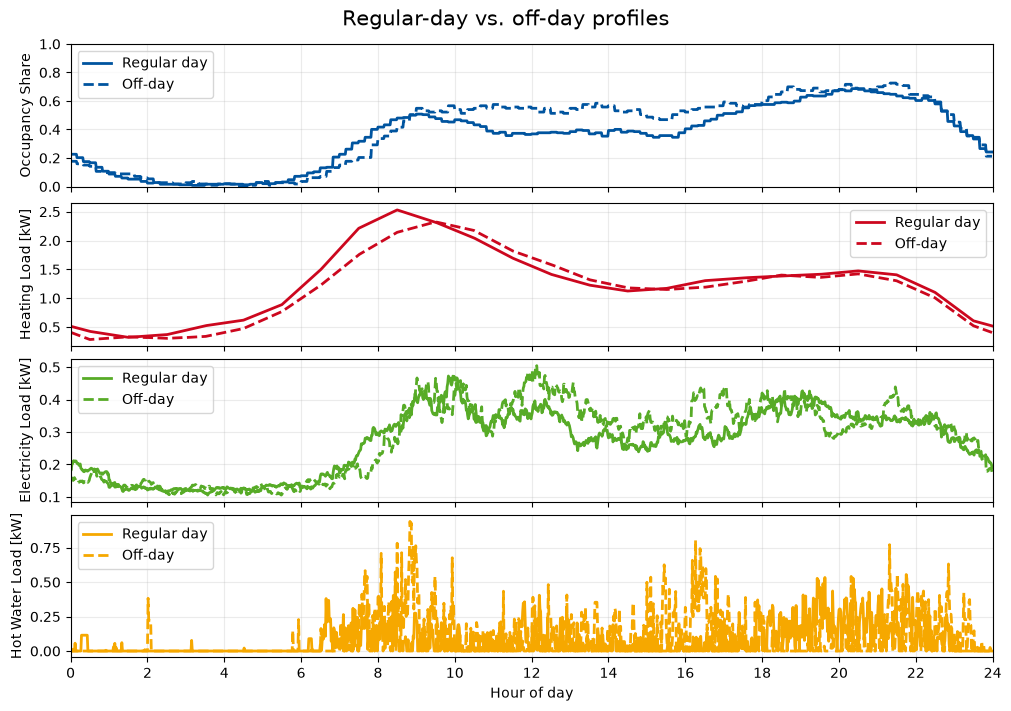

In [61]:
disp_weekday_effect_load(selected_files, resolution=1, season="all")

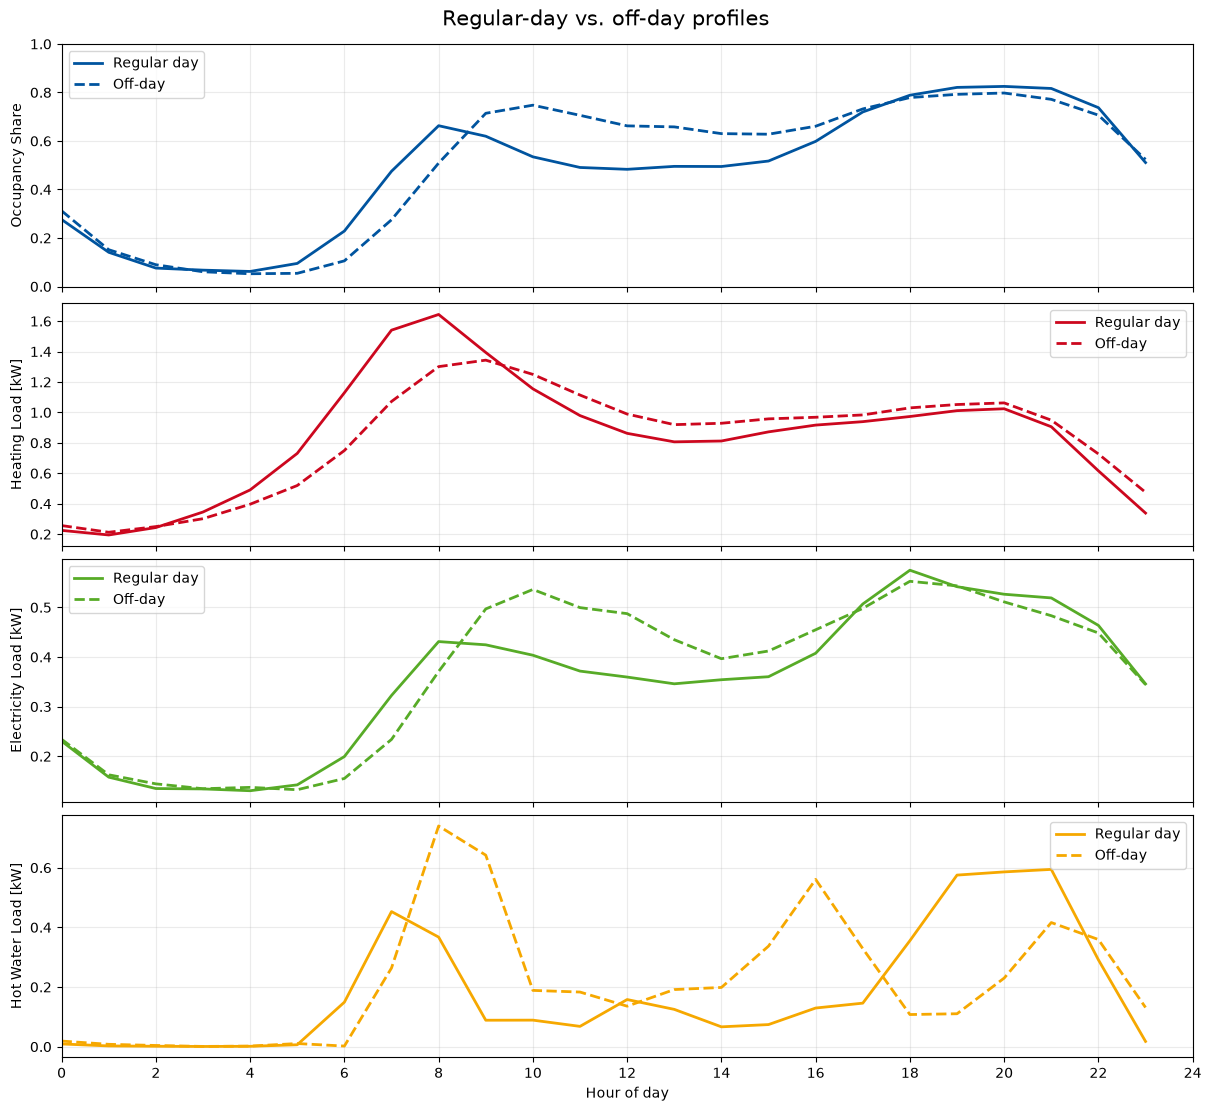

In [31]:
disp_weekday_effect_load(selected_files, resolution=60) #todo display for different building types

In [32]:
ts_agg

NameError: name 'ts_agg' is not defined

In [ ]:
ts = pd.read_hdf(r"C:\Users\Samuel\FH_Aachen\MasterThesis\Master_Thesis_EWI_2026\Ch_1_Data_Preparation\run_20261011\Generation\run_015630.h5", key="timeseries")

In [ ]:
ts

In [ ]:
def find_peak_plats(data, prominence=0.05, plat_tolerance=0.01, plat_min_level=0.10,plat_min_abs=0.05, plat_min_steps=10):
    peak = data.max()
    peak_idx, _ = find_peaks(data.values, prominence=prominence * peak, height=plat_min_abs)
    rol_max = data.rolling(plat_min_steps, center=True,min_periods=1).max()
    rol_min = data.rolling(plat_min_steps, center=True,min_periods=1).min()
    rol_mean = data.rolling(plat_min_steps, center=True,min_periods=1).mean()
    min_level = max(peak * plat_min_level,plat_min_abs)
    plat = (((rol_max - rol_min) <= rol_mean * plat_tolerance) & (rol_min > min_level))
    block = (plat != plat.shift()).cumsum()
    plat_len = plat.groupby(block).transform("size")
    plat_valid = plat & (plat_len >= plat_min_steps)
    return peak_idx, plat_valid, block, min_level


In [ ]:
from scipy.signal import find_peaks

def peak_plateau_ramp_stats(load,freq = "1min",prominence = 0.10,  plat_tolerance = 0.01,      plat_min_level = 0.10,plat_min_abs = 0.05,    plat_min_steps = 10,min_day_level=0.05):

    data = load.resample(freq).mean()
    peak = data.max()
    dates = data.index.date

    day_max = data.groupby(dates).max()
    active_days = day_max.index[day_max >= max(min_day_level * peak, plat_min_abs)]

    peak_idx, plat_valid, block, _ = find_peak_plats(data, prominence, plat_tolerance, plat_min_level, plat_min_abs, plat_min_steps)
    peaks = (pd.Series(dates[peak_idx]).value_counts().reindex(active_days, fill_value=0).rename("peaks"))
    runs = (
        pd.DataFrame({"valid": plat_valid, "t": data.index})
        .groupby(block.values)
        .agg(valid=("valid", "first"), start=("t", "first"), n=("valid", "size"))
    )
    runs = runs[runs["valid"]]
    plateaus = runs.groupby(runs["start"].dt.date)["n"].agg(plateaus="size", plateau_dur_mean="mean", plateau_dur_max="max")

    ramp = data.diff()
    ramps = pd.DataFrame({
        "ramp_abs_mean": ramp.abs().groupby(dates).mean(),
        "ramp_abs_p95": ramp.abs().groupby(dates).quantile(0.95),
        "ramp_up_max": ramp.groupby(dates).max(),
        "ramp_down_max": ramp.groupby(dates).min(),
    })

    daily = pd.concat([peaks, plateaus.reindex(active_days), ramps.reindex(active_days)], axis=1)
    daily["plateaus"] = daily["plateaus"].fillna(0)
    return daily

In [ ]:
peak_plateau_ramp_stats(ts["Electricity Load"])

In [ ]:
def plot_peak_plateau(load,freq = "1min",prominence = 0.10,  plat_tolerance = 0.01,      plat_min_level = 0.10,  plat_min_abs = 0.05,  plat_min_steps = 10, name="Electricity",start=None, end=None):

    data = load.resample(freq).mean()

    peak_idx, plat_valid, _, min_level = find_peak_plats(
        data, prominence, plat_tolerance, plat_min_level, plat_min_abs, plat_min_steps
    )

    is_peak = pd.Series(False, index=data.index)
    is_peak.iloc[peak_idx] = True

    # detection runs on the full series, the plot only shows the selected window
    window = slice(start, end)
    d, pk, pl = data.loc[window], is_peak.loc[window], plat_valid.loc[window]

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.plot(d, label=name)
    ax.axhline(d.mean(), color="gray")
    ax.scatter(d.index[pl],d[pl],color="red",s=15,label="Plateau",zorder=3)
    ax.scatter(d.index[pk],d[pk],color="coral",label="Peak",zorder=4)
    ax.axhline(
    min_level,
    color="green",
    linestyle="--",
    label="Minimum plateau level"
)

    ax.legend()
    plt.show()

In [ ]:
day = "2023-09-02"
data = ts["Electricity Load"].loc[day]
plot_peak_plateau(data,plat_min_steps=10)


In [ ]:

plot_peak_plateau(ts["Electricity Load"], start="2023-09-02", end="2023-09-02 23:59", prominence=0.075)


## Load Distribution and Load Duration Curve

In [5]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Your existing lazy dataset
#lf = pl.scan_parquet(...)

manifest = pl.read_csv(
    "../data/manifests/"
    "realized_manifest_cleaned.csv"
)

metadata = manifest.select(
    "run_id",
    "buildingType",
    "a_ref",
    "n_persons_sum"
)

LOADS = ["Heating Load","Electricity Load","Hot Water Load"]

COLOR_DICT = {"SFH": "#2f6db5", "TH": "#e69f00", "MFH": "#2a9d8f", "AB": "#c44e52"}


data = (
    lf.select("run_id", *LOADS)
    .join(
        metadata.lazy(),
        on="run_id",
        how="inner",
        validate="m:1"
    )
)

In [6]:
def calculate_load_distribution(
    lf,
    metadata,
    load="Heating Load",
    bin_width=0.1,
    normalize=None,
):
    """
    Calculate minute-level load distributions by building type.

    normalize:
        None        -> absolute load [kW]
        "area"      -> specific load [W/m²]
        "occupants" -> load per resident [kW/person]
    """

    if bin_width <= 0:
        raise ValueError("bin_width must be positive")

    if normalize not in (None, "area", "occupants"):
        raise ValueError(
            "normalize must be None, 'area', or 'occupants'"
        )

    # Select only the required time-series columns
    data = lf.select("run_id", load)

    # Join building metadata on run_id
    data = data.join(
        metadata.lazy(),
        on="run_id",
        how="inner",
        validate="m:1"
    )

    # Create normalized load
    if normalize == "area":
        data = (
            data.filter(pl.col("a_ref") > 0)
            .with_columns(
                (
                    pl.col(load)  / pl.col("a_ref")
                ).alias("load_value")
            )
        )

    elif normalize == "occupants":
        data = (
            data.filter(pl.col("n_persons_sum") > 0)
            .with_columns(
                (
                    pl.col(load) / pl.col("n_persons_sum")
                ).alias("load_value")
            )
        )

    else:
        data = data.with_columns(
            pl.col(load).alias("load_value")
        )

    # Calculate histogram
    hist = (
        data.select("buildingType", "load_value")
        .filter(
            pl.col("load_value").is_not_null()
            & pl.col("load_value").is_finite()
        )
        .with_columns(
            (
                (pl.col("load_value") / bin_width).floor()
                * bin_width
            ).alias("bin")
        )
        .group_by(["buildingType", "bin"])
        .agg(
            pl.len().alias("count")
        )
        .with_columns(
            (
                pl.col("count")
                / pl.col("count").sum().over("buildingType")
                / bin_width
            ).alias("density")
        )
        .sort(["buildingType", "bin"])
        .collect(engine="streaming")
    )

    return hist

In [141]:
def plot_load_distribution_filled(
    hist,
    load="Heating Load",
    bin_width=0.1,
    normalize=None,
    xlim=None,
    log_y=False,
):
    labels = {
        None: f"{load} [kW]",
        "area": f"{load} [W/m²]",
        "occupants": f"{load} [kW/person]",
    }

    fig, ax = plt.subplots(figsize=(12, 5))

    for building_type, color in COLOR_DICT.items():

        subset = (
            hist.filter(pl.col("buildingType") == building_type)
            .sort("bin")
        )

        if subset.is_empty():
            continue

        ax.bar(
            subset["bin"].to_numpy(),
            subset["density"].to_numpy(),
            width=bin_width,
            align="edge",
            alpha=0.25,
            color=color,
            edgecolor="none",
            label=building_type
        )

    ax.set_xlabel(labels[normalize])
    ax.set_ylabel("Probability density")
    ax.set_title(load)
    ax.legend(title="Building type")
    ax.grid(alpha=0.25)

    if xlim is not None:
        ax.set_xlim(*xlim)

    if log_y:
        ax.set_yscale("log")

    plt.tight_layout()
    plt.show()

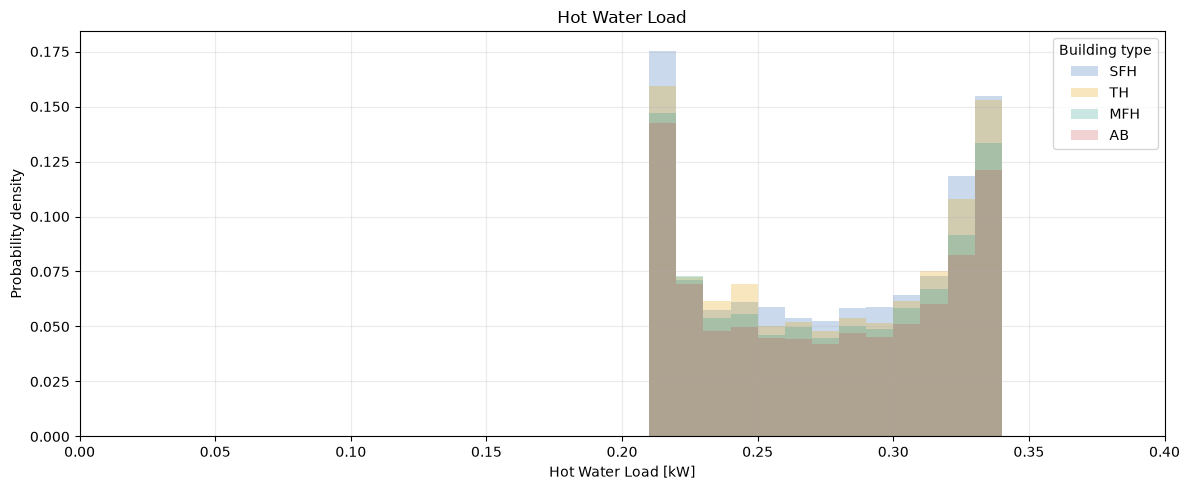

In [12]:
heating_active = data.filter(
    pl.col("Hot Water Load") > 0
)

hist_occ = calculate_load_distribution(
    heating_active,
    metadata,
    load="Hot Water Load",
    bin_width=0.01,
    #normalize="area"
)

plot_load_distribution_filled(
    hist_occ,
    load="Hot Water Load",
    bin_width=0.01,
    #normalize="area",
    xlim=(0, 0.4)
)

In [23]:
import polars as pl

def calculate_load_distribution(
    lf,
    metadata,
    load="Heating Load",
    bin_width=0.1,
    normalize=None,
    scaler=None,
    zero_center=False,
    positive_only=False,
):

    if bin_width <= 0:
        raise ValueError("bin_width must be positive")

    if normalize not in (None, "area", "occupants"):
        raise ValueError("Invalid normalization")

    if scaler not in (None, "zscore", "log_zscore", "minmax", "robust"):
        raise ValueError("Invalid scaler")


    if isinstance(metadata, pl.DataFrame):
        metadata = metadata.lazy()

    data = (
        lf.select("run_id", load)
        .join(
            metadata.select(
                "run_id",
                "buildingType",
                "a_ref",
                "n_persons_sum"
            ),
            on="run_id",
            how="inner"
        )
    )

    if normalize == "area":
        data = (
            data.filter(pl.col("a_ref") > 0)
            .with_columns(
                (
                    pl.col(load) * 1000
                    / pl.col("a_ref")
                ).alias("value")
            )
        )

    elif normalize == "occupants":
        data = (
            data.filter(pl.col("n_persons_sum") > 0)
            .with_columns(
                (
                    pl.col(load)
                    / pl.col("n_persons_sum")
                ).alias("value")
            )
        )

    else:
        data = data.with_columns(
            pl.col(load).alias("value")
        )

    data = data.filter(
        pl.col("value").is_not_null()
        & pl.col("value").is_finite()
    )

    value = pl.col("value")
    log_value = value.log1p()

    expressions = [
        pl.len().alias("n"),
        value.mean().alias("mean"),
        value.std(ddof=0).alias("std"),
        value.min().alias("min"),
        value.max().alias("max"),
    ]

    if scaler == "robust":
        expressions += [
            value.quantile(0.25).alias("q25"),
            value.median().alias("median"),
            value.quantile(0.75).alias("q75"),
        ]

    if scaler == "log_zscore":
        expressions += [
            log_value.mean().alias("log_mean"),
            log_value.std(ddof=0).alias("log_std"),
        ]

    stats = (
        data.select(expressions)
        .collect(engine="streaming")
        .row(0, named=True)
    )

    if scaler is None:
        expression = pl.col("value")

    elif scaler == "zscore":
        center = 0.0 if zero_center else stats["mean"]
        scale = stats["std"]

        if scale <= 1e-12:
            raise ValueError("Z-score standard deviation is zero")

        expression = (
            (pl.col("value") - center) / scale
        )

    elif scaler == "minmax":
        center = 0.0 if zero_center else stats["min"]
        scale = stats["max"] - stats["min"]

        if scale <= 1e-12:
            raise ValueError("MinMax range is zero")

        expression = (
            (pl.col("value") - center) / scale
        )

    elif scaler == "robust":
        center = 0.0 if zero_center else stats["median"]
        scale = stats["q75"] - stats["q25"]

        if scale <= 1e-12:
            raise ValueError(
                "Robust scaling is undefined: IQR is zero"
            )

        expression = (
            (pl.col("value") - center) / scale
        )

    elif scaler == "log_zscore":
        if stats["min"] < 0:
            raise ValueError(
                "log_zscore requires non-negative values"
            )

        center = 0.0 if zero_center else stats["log_mean"]
        scale = stats["log_std"]

        if scale <= 1e-12:
            raise ValueError("Log standard deviation is zero")

        expression = (
            (pl.col("value").log1p() - center) / scale
        )

    if positive_only:
        data = data.filter(pl.col("value") > 0)

    hist = (
        data.with_columns(
            expression.alias("scaled_value")
        )
        .with_columns(
            (
                (
                    pl.col("scaled_value") / bin_width
                ).floor() * bin_width
            ).alias("bin")
        )
        .group_by(["buildingType", "bin"])
        .agg(
            pl.len().alias("count")
        )
        .with_columns(
            (
                pl.col("count")
                / pl.col("count").sum().over("buildingType")
                / bin_width
            ).alias("density")
        )
        .sort(["buildingType", "bin"])
        .collect(engine="streaming")
    )

    return hist, stats

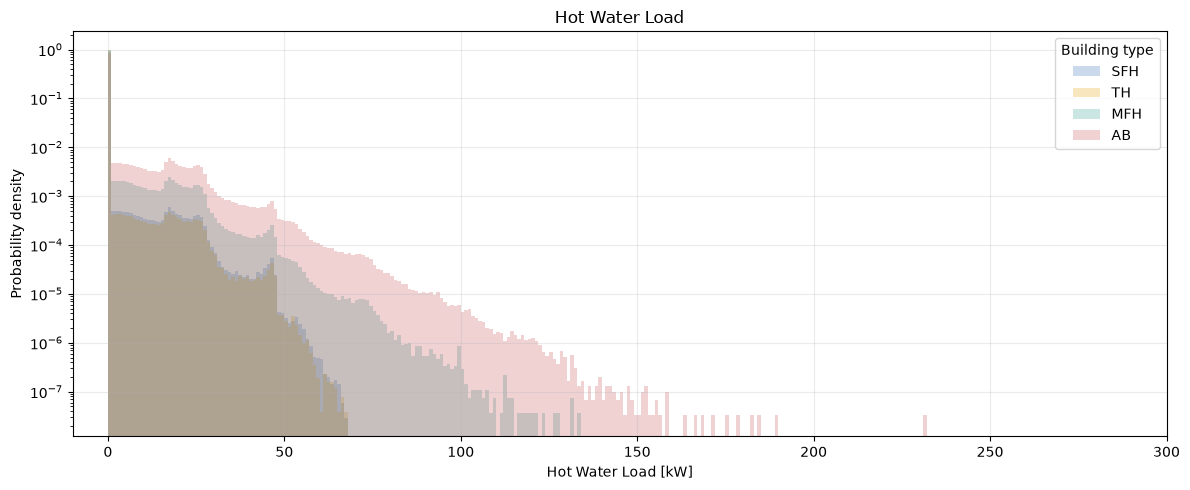

In [163]:
heating_active = data.filter(
    pl.col("Hot Water Load") > 0
)

hist, stats = calculate_load_distribution(
    lf,
    metadata,
    load="Hot Water Load",
    #normalize="occupants",
    bin_width=1,
    #scaler="log_zscore",
    zero_center=True
)

plot_load_distribution_filled(
    hist,
    load="Hot Water Load",
    bin_width=1,
    #normalize="occupants",
    xlim=(-10, 300),
    log_y=True
)



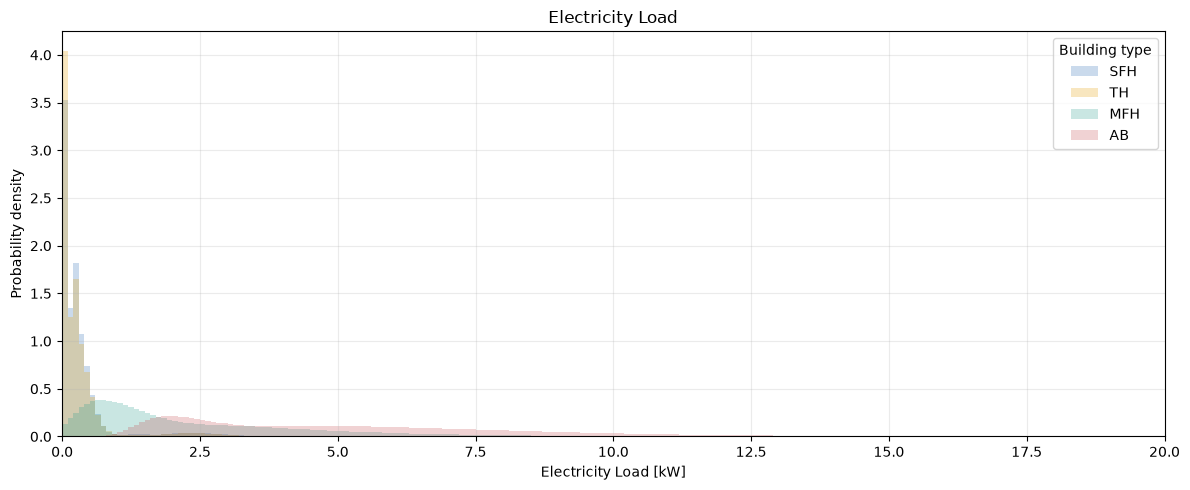

In [162]:
heating_active = data.filter(
    pl.col("Electricity Load") > 0
)

hist, stats = calculate_load_distribution(
    heating_active,
    metadata,
    load="Electricity Load",
    #normalize="occupants",
    bin_width=0.1,
    #scaler="log_zscore",
    zero_center=True
)

plot_load_distribution_filled(
    hist,
    load="Electricity Load",
    bin_width=0.1,
    #normalize="occupants",
    xlim=(-0.01, 20)
)

## Seasonality


In [92]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

LOADS = [
    "Heating Load",
    "Electricity Load",
    "Hot Water Load"
]

def calculate_monthly_daily_peaks(selected_files):

    selected_files = [str(Path(f)) for f in selected_files]
    lf = pl.scan_parquet(selected_files)

    daily_peaks = lf.select("run_id", "timestamp", *LOADS).with_columns(pl.col("timestamp").dt.date().alias("date")).group_by(["run_id", "date"]).agg(*[pl.col(load).max().alias(load) for load in LOADS])

    monthly_peaks = daily_peaks.with_columns(pl.col("date").dt.month().alias("month")).group_by(["run_id", "month"]).agg(*[pl.col(load).mean().alias(load) for load in LOADS],pl.len().alias("n_days")).sort(["run_id", "month"]).collect(engine="streaming")

    return monthly_peaks

In [93]:
monthly_peaks = calculate_monthly_daily_peaks(selected_files)

In [94]:
def plot_monthly_daily_peaks(monthly_peaks):
    df = monthly_peaks.to_pandas()
    fig, axes = plt.subplots(3, 1,figsize=(12, 10),sharex=True,constrained_layout=True)
    for ax, load in zip(axes, LOADS):
        sns.boxplot(
            data=df,
            x="month",
            y=load,
            order=range(1, 13),
            color=PROFILES[load]["color"],
            showfliers=False,
            ax=ax
        )

        ax.set_ylabel(PROFILES[load]["label"])
        ax.set_xlabel("")
        ax.grid(axis="y", alpha=0.25)

    axes[-1].set_xlabel("Month")
    fig.suptitle(
        "Monthly distribution of mean daily peak loads",
        fontsize=15
    )
    plt.show()

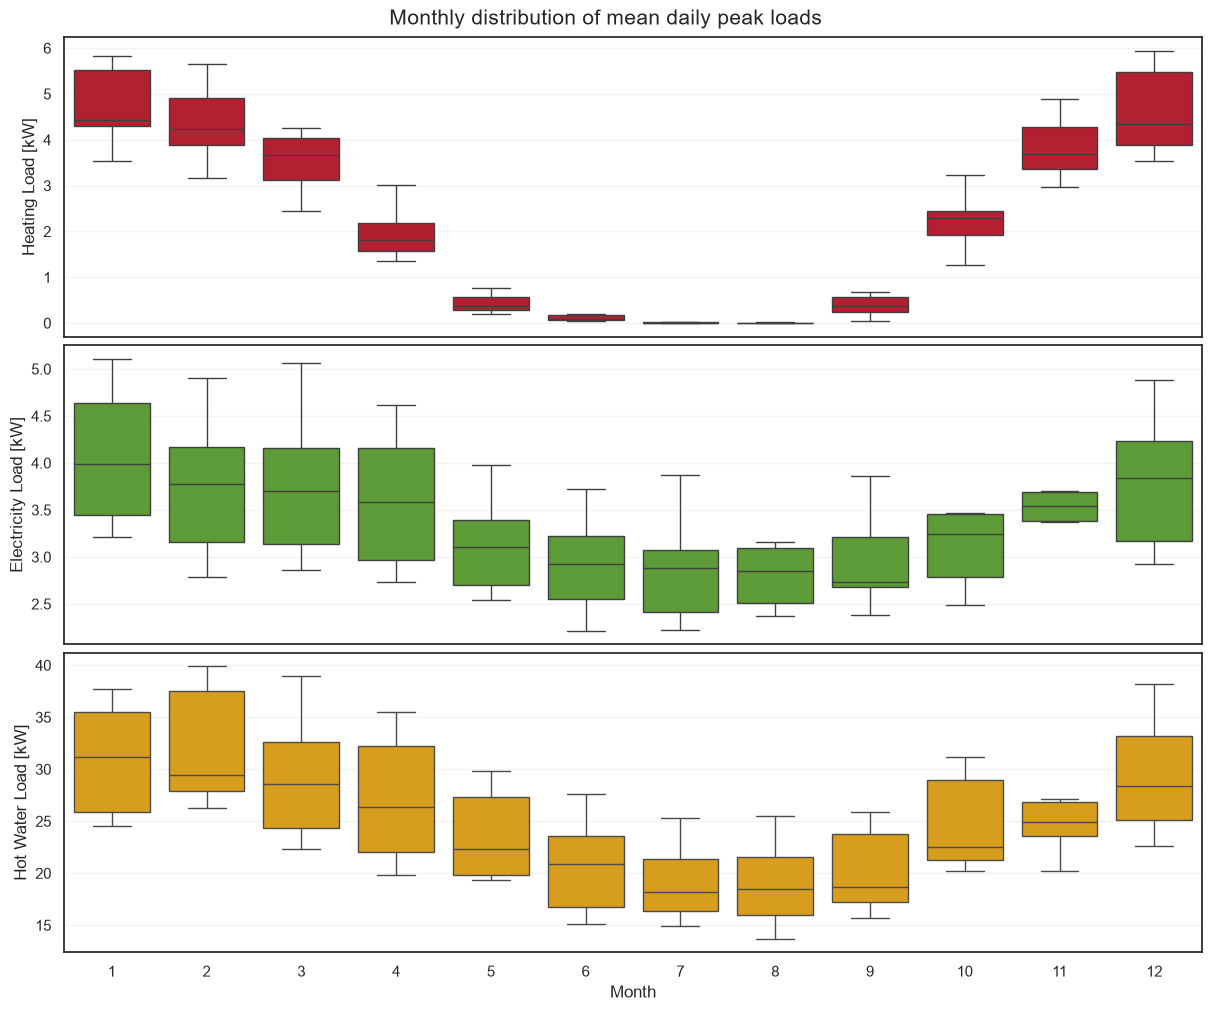

In [95]:
plot_monthly_daily_peaks(monthly_peaks)

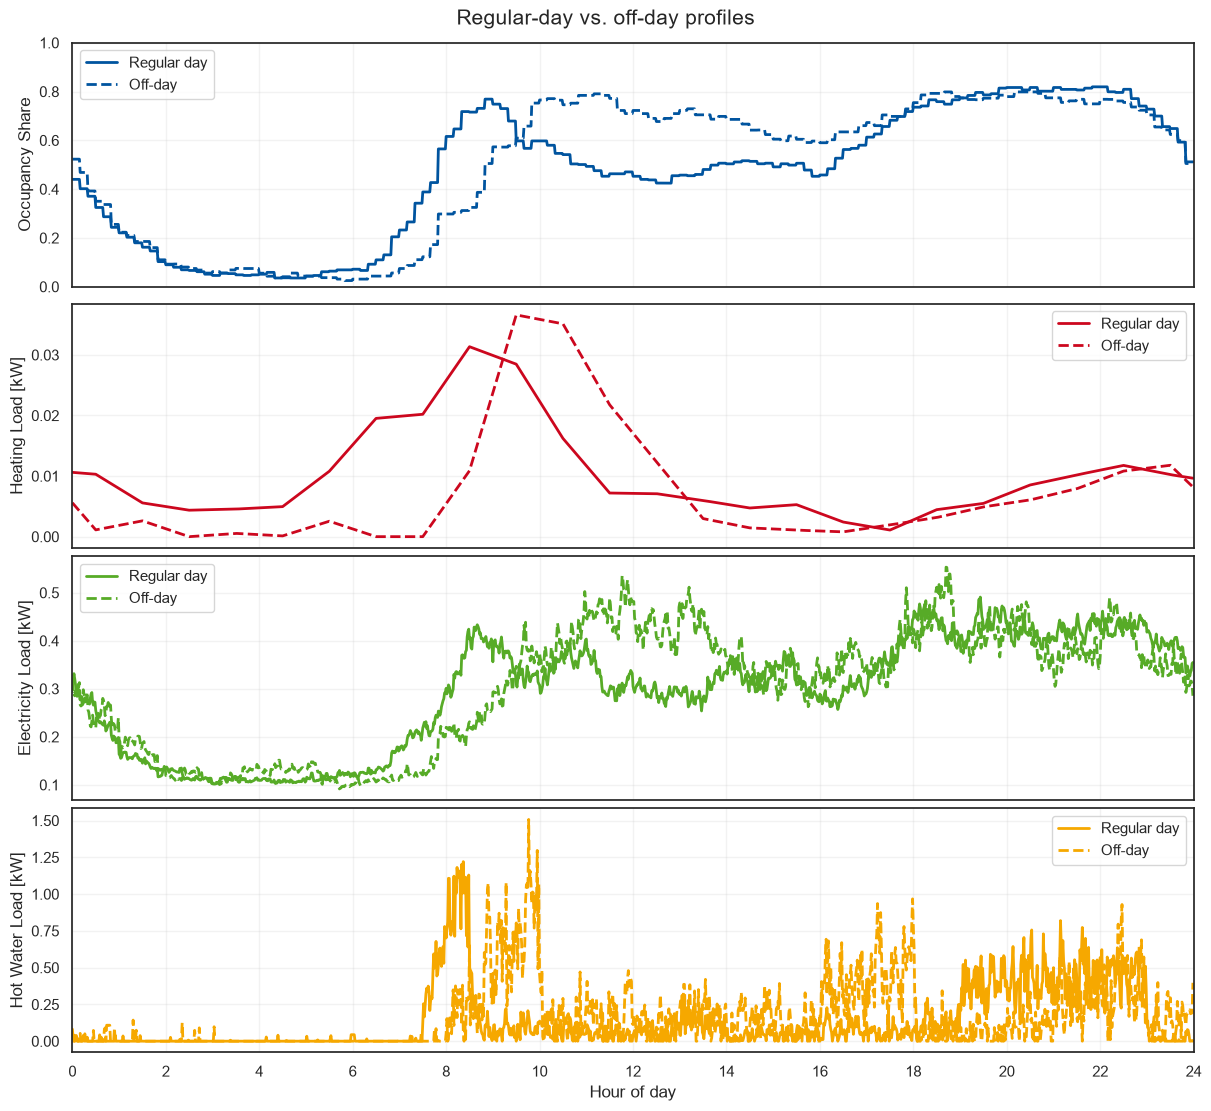

In [96]:
disp_weekday_effect_load(selected_files, resolution=1, season="summer")

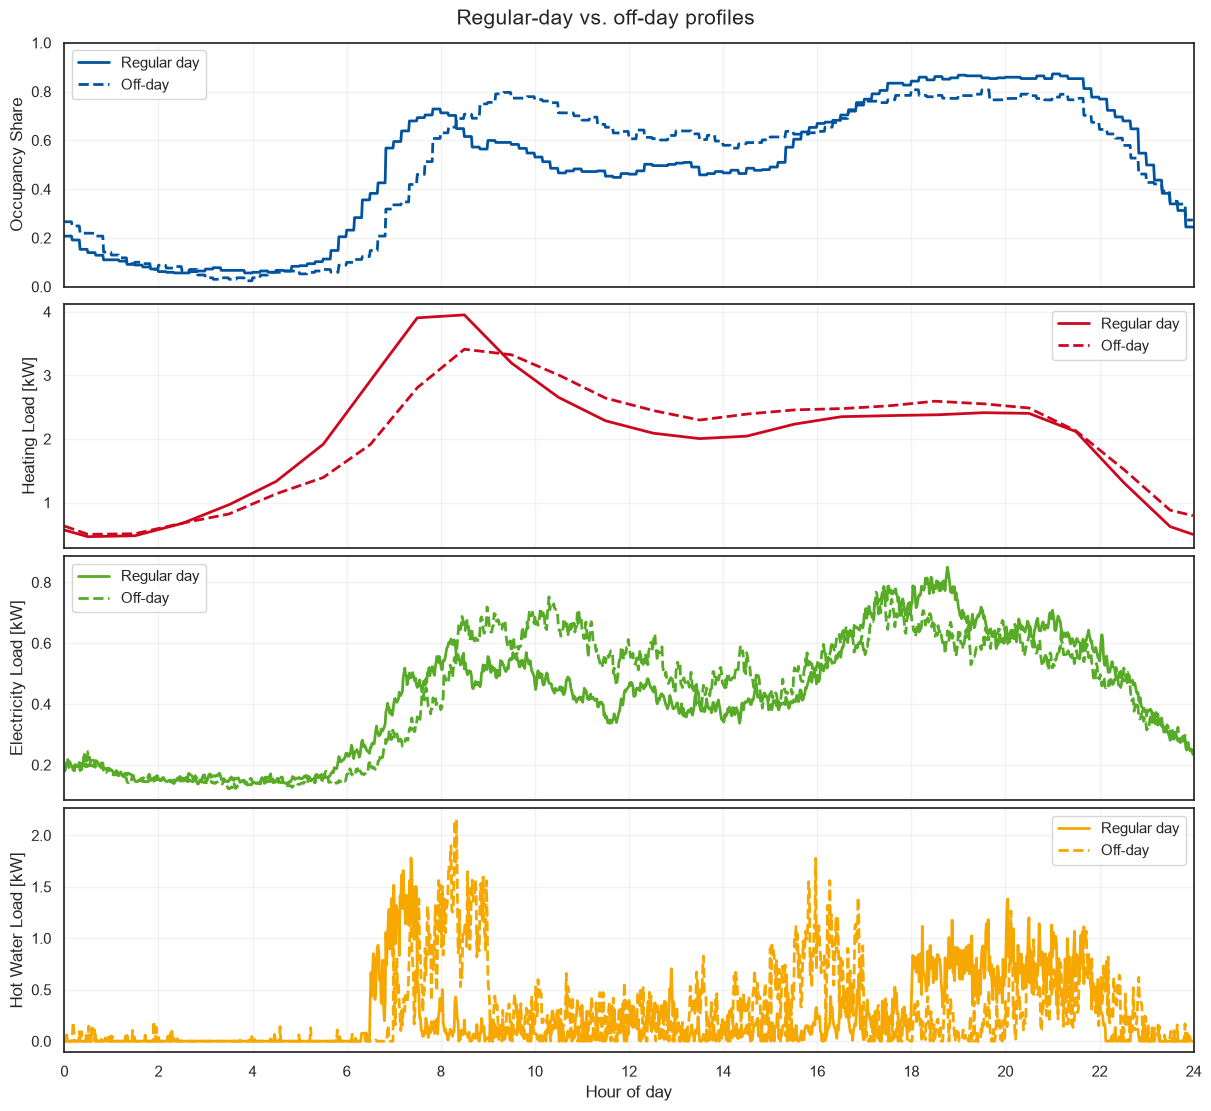

In [97]:
disp_weekday_effect_load(selected_files, resolution=1, season="winter")

## Correlation between Energy Domains

In [13]:
ts = pd.read_hdf(r"C:\Users\Samuel\FH_Aachen\MasterThesis\Master_Thesis_EWI_2026\DataSplit\Data\test\run_015038.h5", key="timeseries")

In [4]:
autocorr_table(ts, freq="1min", max_lag="48h")

r
variable         lag_min          
Electricity Load 0.0      1.000000
                 1.0      0.962434
                 2.0      0.925246
                 3.0      0.888386
                 4.0      0.874896
...                            ...
T                2876.0   0.851442
                 2877.0   0.851421
                 2878.0   0.851398
                 2879.0   0.851372
                 2880.0   0.851344

[17286 rows x 1 columns]

In [132]:
corr, partialdf=corr_table(ts, freq="1min", resid=False, Offday=2)

In [133]:
corr

,Electricity Load,Hot Water Load,Heating Load,Occupancy Home Active,Occupancy Home Not Active,T
Electricity Load,1.000000,0.073362,0.276778,0.624281,-0.357188,-0.199089
Hot Water Load,0.073362,1.000000,0.024261,0.116169,-0.062019,-0.006655
Heating Load,0.276778,0.024261,1.000000,0.105851,-0.091028,-0.872352
Occupancy Home Active,0.624281,0.116169,0.105851,1.000000,-0.563214,0.042417
Occupancy Home Not Active,-0.357188,-0.062019,-0.091028,-0.563214,1.000000,-0.147845
T,-0.199089,-0.006655,-0.872352,0.042417,-0.147845,1.000000


In [5]:
correlations = pd.read_csv("../Ch_1_Data_Preparation/run_20261011/checked_ts_test_correlation.csv", index_col=0)
partial_correlations = pd.read_csv("../Ch_1_Data_Preparation/run_20261011/checked_ts_test_partial_correlation.csv", index_col=0)
auto_correlations = pd.read_csv("../Ch_1_Data_Preparation/run_20261011/checked_ts_test_auto_correlation.csv", index_col=0)

In [11]:
auto_correlations

,freq,offday,resid,variable,lag_min,r
run_id,,,,,,
run_000030,1min,2,False,Electricity Load,0.0,1.000000
run_000030,1min,2,False,Electricity Load,1.0,0.962434
run_000030,1min,2,False,Electricity Load,2.0,0.925246
run_000030,1min,2,False,Electricity Load,3.0,0.888386
run_000030,1min,2,False,Electricity Load,4.0,0.874896
...,...,...,...,...,...,...
run_015727,1h,2,True,T,2640.0,0.849117
run_015727,1h,2,True,T,2700.0,0.855087
run_015727,1h,2,True,T,2760.0,0.860163


In [6]:
bldg_type = manifest[["run_id","buildingType"]]
data = correlations.merge(bldg_type,how="left", on="run_id").set_index(["run_id","buildingType", "freq", "offday", "resid", "variable"])
data_partial = partial_correlations.merge(bldg_type,how="left", on="run_id").set_index(["run_id","buildingType", "freq", "offday", "resid","comparison"])
data_auto = auto_correlations.merge(bldg_type,how="left", on="run_id").set_index(["run_id","buildingType", "freq", "offday", "resid","variable", "lag_min"])

In [23]:
data_auto

r
run_id     buildingType freq offday resid variable         lag_min          
run_000030 AB           1min 2      False Electricity Load 0.0      1.000000
                                                           1.0      0.962434
                                                           2.0      0.925246
                                                           3.0      0.888386
                                                           4.0      0.874896
...                                                                      ...
run_015727 TH           1h   2      True  T                2640.0   0.849117
                                                           2700.0   0.855087
                                                           2760.0   0.860163
                                                           2820.0   0.863459
                                                           2880.0   0.863764

[8394624 rows x 1 columns]

In [136]:
mean_partial = avg_partial_corr(data_partial)

In [137]:
mean_partial

r_mean   r_std_z  \
buildingType freq resid comparison                                          
AB           1min False electricity_hotwater_active   -0.010898  0.005867   
                        electricity_hotwater_inactive  0.168845  0.020882   
                        heating_active_T               0.344186  0.146064   
                        heating_inactive_T            -0.374558  0.249023   
                        heating_T_inactive            -0.929213  0.100442   
...                                                         ...       ...   
TH           1h   True  electricity_hotwater_inactive  0.345726  0.042604   
                        heating_active_T               0.141756  0.027254   
                        heating_inactive_T            -0.298250  0.066471   
                        heating_T_inactive            -0.862498  0.202353   
                        heating_electricity_all        0.179149  0.036759   

                                                       n_runs  
buildingType freq resid comparison                             
AB           1min False electricity_hotwater_active        57  
                        electricity_hotwater_inactive      57  
                        heating_active_T                   57  
                        heating_inactive_T                 57  
                        heating_T_inactive                 57  
...                                                       ...  
TH           1h   True  electricity_hotwater_inactive      49  
                        heating_active_T                   49  
                        heating_inactive_T                 49  
                        heating_T_inactive                 49  
                        heating_electricity_all            49  

[144 rows x 3 columns]

In [138]:
comparison = mean_partial.xs(("1min", False),level=("freq", "resid"))
comparison_table = comparison["r_mean"].unstack("buildingType")
comparison_table

buildingType,AB,MFH,SFH,TH
comparison,,,,
electricity_hotwater_active,-0.010898,-0.004578,-0.003201,-0.000569
electricity_hotwater_inactive,0.168845,0.095537,0.061564,0.059000
heating_active_T,0.344186,0.296057,0.319596,0.324282
heating_inactive_T,-0.374558,-0.348493,-0.575222,-0.595270
heating_T_inactive,-0.929213,-0.927691,-0.933112,-0.909582
heating_electricity_all,0.103926,0.064974,0.019574,0.019590


In [139]:
mean_corr, std_corr, n_corr = avg_corr(data, offday=2)

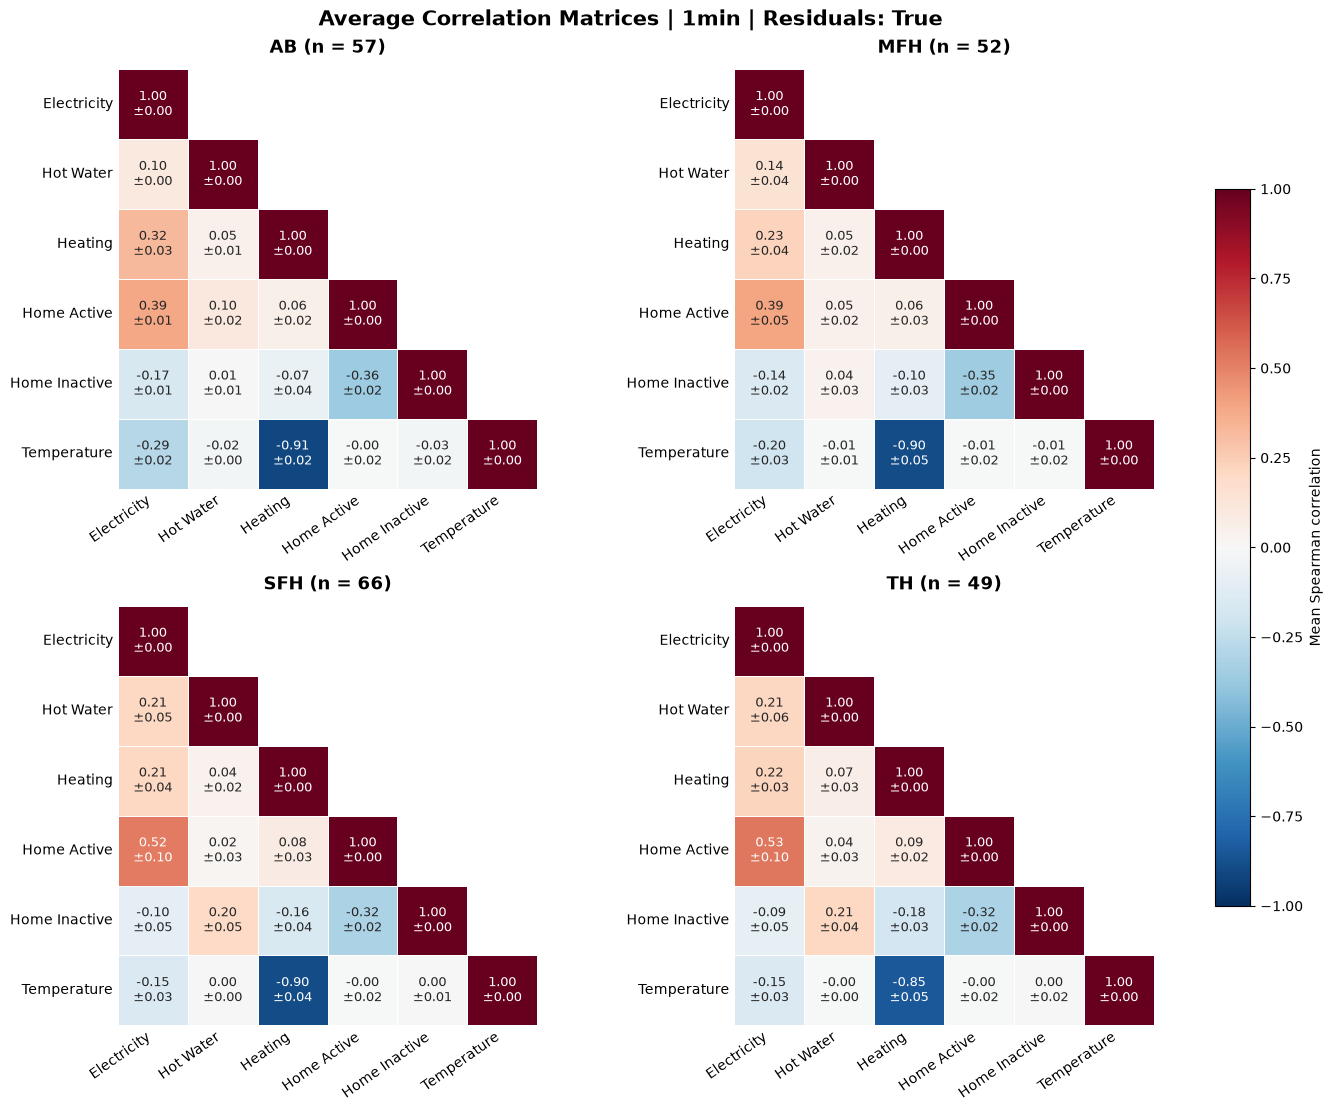

In [140]:
plot_corr_matrices(mean_corr,std_corr,n_corr,freq="1min",resid=True,show_std=True)

In [42]:
corr1, _ =corr_table(ts, freq="1min", partial=False)
corr1

,Electricity Load,Hot Water Load,Heating Load,Occupancy Home Active,Occupancy Home Not Active,T
Electricity Load,1.000000,0.248686,0.328075,0.788622,-0.616296,-0.049809
Hot Water Load,0.248686,1.000000,0.079318,0.324011,-0.170626,0.008951
Heating Load,0.328075,0.079318,1.000000,0.134770,-0.127936,-0.831918
Occupancy Home Active,0.788622,0.324011,0.134770,1.000000,-0.682399,0.156850
Occupancy Home Not Active,-0.616296,-0.170626,-0.127936,-0.682399,1.000000,-0.254094
T,-0.049809,0.008951,-0.831918,0.156850,-0.254094,1.000000


In [141]:
pairs = [
    ("Occupancy Home Active", "Electricity Load"),
    ("Occupancy Home Active", "Hot Water Load"),
    ("Occupancy Home Active", "Heating Load"),
    ("Heating Load", "Electricity Load"),
    ("T", "Heating Load"),
]

lag_corr = lagged_corr(
    ts,
    pairs=pairs,
    freq="15min",
    max_lag="1440min",
    resid=False,
    Offday=2,
)

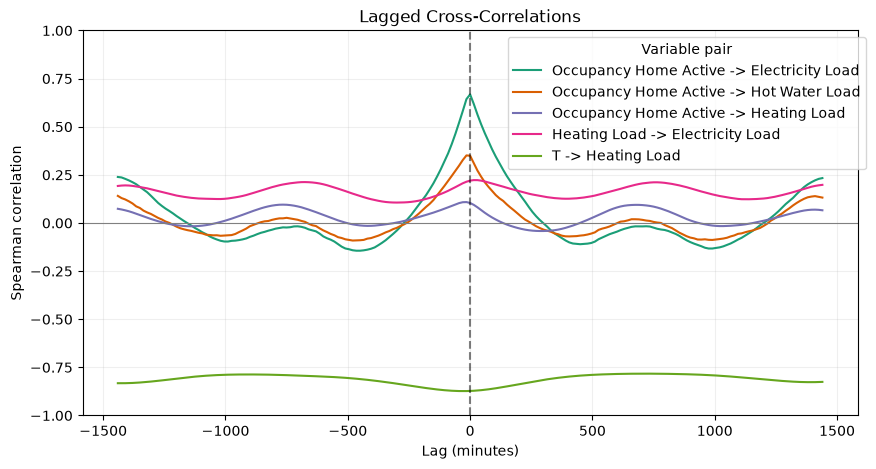

In [142]:
fig, ax = plot_lagged_corr(lag_corr)
plt.show()

In [34]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def plot_autocorrelation(data,variable="Electricity Load",freq="15min",max_lag=50,resid=False,Offday=2):
    df = prepare_corr_data(data, freq, resid, Offday)
    series = df[variable].dropna()
    fig, axes = plt.subplots(2, 1,figsize=(10, 7),layout="constrained")
    plot_acf(series,lags=max_lag,ax=axes[0],alpha=None,zero=False, fft=True)
    plot_pacf(series,lags=max_lag,ax=axes[1],alpha=None, zero=False,method="ywm")
    axes[0].set_title("Autocorrelation (ACF)")
    axes[1].set_title("Partial Autocorrelation (PACF)")

    axes[1].set_xlabel(f"Lag (steps of {freq})")

    return fig, axes

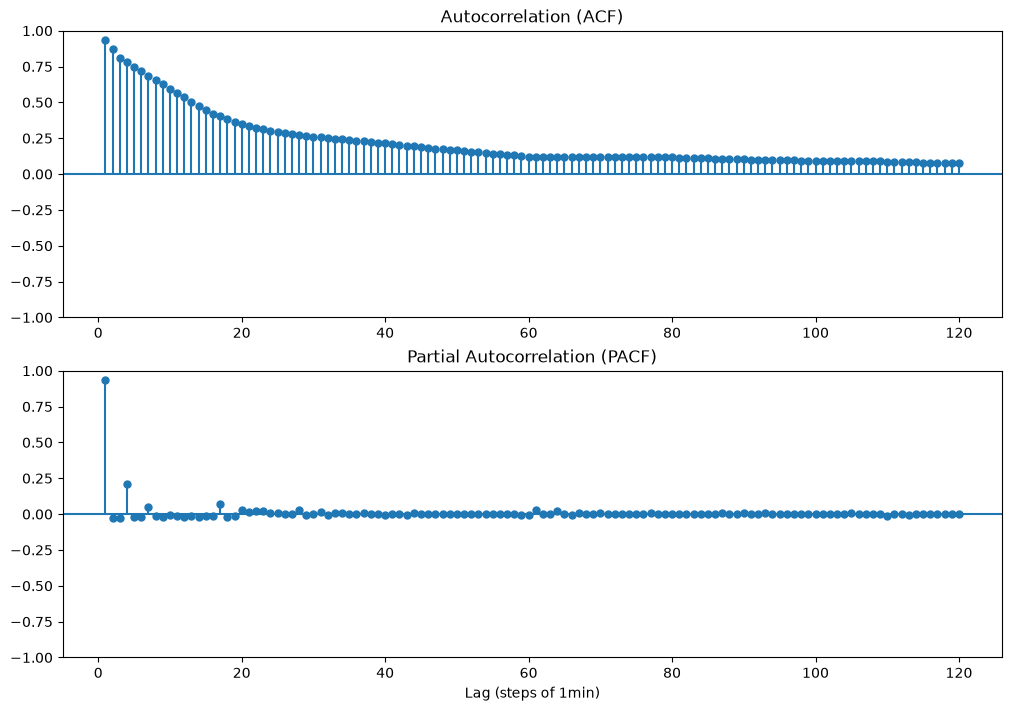

In [36]:
fig, axes = plot_autocorrelation(
    ts,
    variable="Electricity Load",
    freq="1min",
    max_lag=120,
    resid=False
)

plt.show()

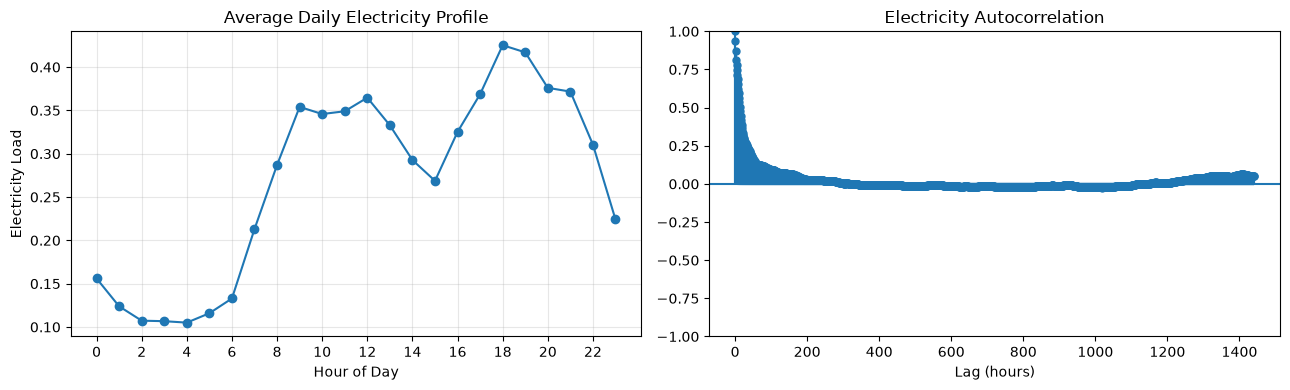

In [33]:
import matplotlib.pyplot as plt

df = prepare_corr_data(
    ts,
    freq="1min",
    resid=False,
    Offday=2
)

electricity = df["Electricity Load"]

daily_profile = electricity.groupby(
    electricity.index.hour
).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

daily_profile.plot(
    ax=axes[0],
    marker="o"
)

axes[0].set_title("Average Daily Electricity Profile")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Electricity Load")
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(alpha=0.3)

from statsmodels.graphics.tsaplots import plot_acf

plot_acf(
    electricity.dropna(),
    lags=1440,
    ax=axes[1],
    fft=True
)

axes[1].set_title("Electricity Autocorrelation")
axes[1].set_xlabel("Lag (hours)")

plt.tight_layout()
plt.show()

In [155]:
# def autocorr_table(data,freq="15min",max_lag="48h",resid=False,Offday=2,method="spearman"):
#     df = prepare_corr_data(data,freq=freq,resid=resid,Offday=Offday)
#     step = pd.to_timedelta(freq)
#     max_steps = int(pd.to_timedelta(max_lag) / step)
#
#     results = []
#
#     for variable in df.columns:
#         series = df[variable]
#
#         for lag in range(max_steps + 1):
#             shifted = series.shift(lag)
#
#             valid = series.notna() & shifted.notna()
#             n = int(valid.sum())
#
#             r = series[valid].corr(shifted[valid],method=method) if n >= 3 else np.nan
#
#             results.append({
#                 "variable": variable,
#                 "lag_min": lag * step.total_seconds() / 60,
#                 "r": r,
#                 "n": n,
#             })
#
#     return pd.DataFrame(results).set_index(["variable", "lag_min"])

In [18]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf

def autocorr_table(data,freq="15min",max_lag="48h",resid=False,Offday=2):
    df = prepare_corr_data(data, freq, resid, Offday)
    step = pd.to_timedelta(freq)
    max_steps = int(pd.to_timedelta(max_lag) / step)
    results = []
    for variable in df.columns:
        series = df[variable]
        acf_values = acf(series,nlags=max_steps,fft=True,missing="conservative")

        results.append(
            pd.DataFrame({
                "variable": variable,
                "lag_min": np.arange(len(acf_values))
                           * step.total_seconds() / 60,
                "r": acf_values,
            })
        )

    return pd.concat(results,ignore_index=True).set_index(["variable", "lag_min"])

In [19]:
auto_corr = autocorr_table(
    ts,
    freq="1min",
    max_lag="48h",
    resid=False,
)

auto_corr

r
variable         lag_min          
Electricity Load 0.0      1.000000
                 1.0      0.936287
                 2.0      0.873203
                 3.0      0.810870
                 4.0      0.778940
...                            ...
T                2876.0   0.883918
                 2877.0   0.883901
                 2878.0   0.883883
                 2879.0   0.883862
                 2880.0   0.883839

[17286 rows x 1 columns]

In [20]:
acf

<function statsmodels.tsa.stattools._stattools.acf(x, adjusted=False, nlags=None, qstat=False, fft=True, alpha=None, bartlett_confint=True, missing='none', *, result_object: 'bool | None' = None)>

In [21]:
def avg_autocorr(data, offday=2):
    df = data.xs(offday, level="offday")

    levels = [
        "buildingType",
        "freq",
        "resid",
        "variable",
        "lag_min",
    ]

    z = np.arctanh(
        df["r"].clip(-1 + 1e-12, 1 - 1e-12)
    )

    grouped = z.groupby(level=levels, sort=False)

    result = pd.DataFrame({
        "mean_r": np.tanh(grouped.mean()),
        "std_r": df["r"].groupby(
            level=levels, sort=False
        ).std(),
        "n_runs": grouped.count(),
    })

    return result

In [22]:
data_auto

r
run_id     buildingType freq offday resid variable         lag_min          
run_000030 AB           1min 2      False Electricity Load 0.0      1.000000
                                                           1.0      0.962434
                                                           2.0      0.925246
                                                           3.0      0.888386
                                                           4.0      0.874896
...                                                                      ...
run_015727 TH           1h   2      True  T                2640.0   0.849117
                                                           2700.0   0.855087
                                                           2760.0   0.860163
                                                           2820.0   0.863459
                                                           2880.0   0.863764

[8394624 rows x 1 columns]

In [23]:
mean_acf = avg_autocorr(data_auto, offday=2)
mean_acf

mean_r     std_r  n_runs
buildingType freq resid variable         lag_min                            
AB           1min False Electricity Load 0.0      1.000000  0.000000      57
                                         1.0      0.966150  0.003920      57
                                         2.0      0.932671  0.007777      57
                                         3.0      0.899541  0.011604      57
                                         4.0      0.886360  0.012702      57
...                                                    ...       ...     ...
TH           1h   True  T                2640.0   0.850686  0.026138      49
                                         2700.0   0.852875  0.026259      49
                                         2760.0   0.854539  0.026535      49
                                         2820.0   0.855186  0.026909      49
                                         2880.0   0.854273  0.027307      49

[149904 rows x 3 columns]

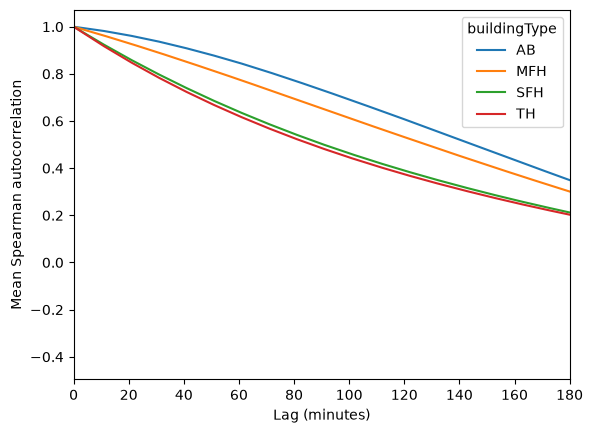

In [28]:
selected = mean_acf.xs(
    ("1min", False, "Occupancy Home Active"),
    level=("freq", "resid", "variable"),
)

sns.lineplot(
    data=selected.reset_index(),
    x="lag_min",
    y="mean_r",
    hue="buildingType",
)

plt.xlabel("Lag (minutes)")
plt.ylabel("Mean Spearman autocorrelation")
plt.xlim(0, 180)
plt.show()

In [29]:
selected = mean_acf.xs(
    (False, "Electricity Load"),
    level=("resid", "variable"),
)

# Compare 1min and 1h at matching lags
acf_1min = selected.xs("1min", level="freq")
acf_1h = selected.xs("1h", level="freq")

comparison = acf_1min["mean_r"].unstack("buildingType").loc[
    [60, 360, 720, 1440, 2880]
]

comparison_hourly = acf_1h["mean_r"].unstack("buildingType").loc[
    [60, 360, 720, 1440, 2880]
]

difference = comparison_hourly - comparison

print(difference)

buildingType        AB       MFH       SFH        TH
lag_min                                             
60.0          0.215241  0.277283  0.272796  0.267721
360.0        -0.031801 -0.033339 -0.020392 -0.016125
720.0        -0.038448 -0.033585 -0.011527 -0.009502
1440.0        0.179175  0.189096  0.099770  0.095320
2880.0        0.175576  0.185632  0.096861  0.091175


In [37]:
import matplotlib.pyplot as plt
import numpy as np

def plot_individual_vs_mean_acf(
    acf,
    building_type="SFH",
    freq="1min",
    resid=False,
    variable="Electricity Load",
    max_runs=30,
):
    df = acf.xs(
        (building_type, freq, 2, resid, variable),
        level=("buildingType", "freq", "offday", "resid", "variable"),
    )

    fig, ax = plt.subplots(figsize=(11, 5))

    runs = df.index.get_level_values("run_id").unique()

    # Plot individual simulations
    for run_id in runs[:max_runs]:
        run = df.xs(run_id, level="run_id").sort_index()

        ax.plot(
            run.index,
            run["r"],
            color="gray",
            alpha=0.15,
            linewidth=0.7,
        )

    # Plot mean across all runs
    mean = df.groupby(level="lag_min")["r"].mean()

    ax.plot(
        mean.index,
        mean,
        color="red",
        linewidth=2,
        label="Mean across runs",
    )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(1440, color="black", linestyle="--", alpha=0.5)

    ax.set_xlabel("Lag (minutes)")
    ax.set_ylabel("Autocorrelation")
    ax.set_title(f"{building_type} | {freq} | {variable}")
    ax.legend()

    return fig, ax

(<Figure size 1100x500 with 1 Axes>,
 <Axes: title={'center': 'SFH | 1min | Electricity Load'}, xlabel='Lag (minutes)', ylabel='Autocorrelation'>)

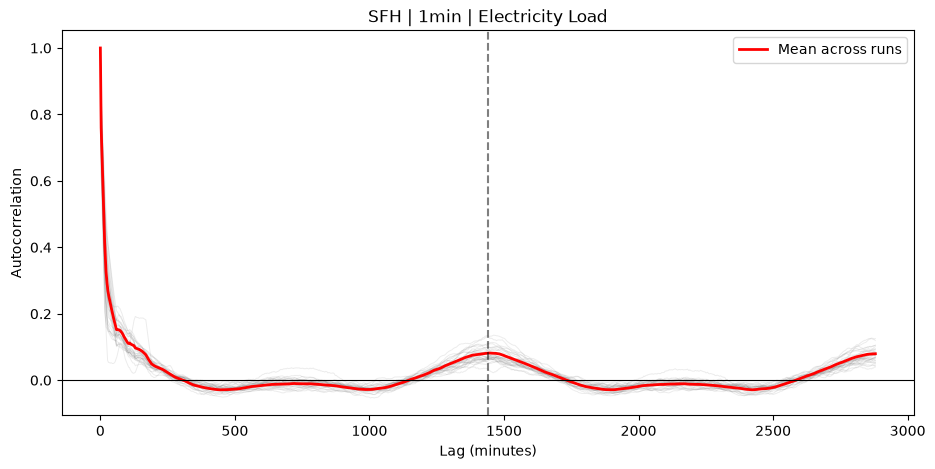

In [42]:
plot_individual_vs_mean_acf(data_auto, freq="1min")

In [46]:
auto_correlations

,freq,offday,resid,variable,lag_min,r
run_id,,,,,,
run_000030,1min,2,False,Electricity Load,0.0,1.000000
run_000030,1min,2,False,Electricity Load,1.0,0.962434
run_000030,1min,2,False,Electricity Load,2.0,0.925246
run_000030,1min,2,False,Electricity Load,3.0,0.888386
run_000030,1min,2,False,Electricity Load,4.0,0.874896
...,...,...,...,...,...,...
run_015727,1h,2,True,T,2640.0,0.849117
run_015727,1h,2,True,T,2700.0,0.855087
run_015727,1h,2,True,T,2760.0,0.860163


In [55]:
data_auto

r
run_id     buildingType freq offday resid variable         lag_min          
run_000030 AB           1min 2      False Electricity Load 0.0      1.000000
                                                           1.0      0.962434
                                                           2.0      0.925246
                                                           3.0      0.888386
                                                           4.0      0.874896
...                                                                      ...
run_015727 TH           1h   2      True  T                2640.0   0.849117
                                                           2700.0   0.855087
                                                           2760.0   0.860163
                                                           2820.0   0.863459
                                                           2880.0   0.863764

[8394624 rows x 1 columns]

In [53]:
selected.loc["AB"].index

Index([   0.0,    1.0,    2.0,    3.0,    4.0,    5.0,    6.0,    7.0,    8.0,
          9.0,
       ...
       2871.0, 2872.0, 2873.0, 2874.0, 2875.0, 2876.0, 2877.0, 2878.0, 2879.0,
       2880.0],
      dtype='float64', name='lag_min', length=2881)

In [64]:
data_auto.xs("SFH", level="buildingType")

r
run_id     freq offday resid variable         lag_min          
run_006812 1min 2      False Electricity Load 0.0      1.000000
                                              1.0      0.915361
                                              2.0      0.831395
                                              3.0      0.748218
                                              4.0      0.714481
...                                                         ...
run_011404 1h   2      True  T                2640.0   0.849680
                                              2700.0   0.851234
                                              2760.0   0.852110
                                              2820.0   0.852020
                                              2880.0   0.850670

[2473416 rows x 1 columns]

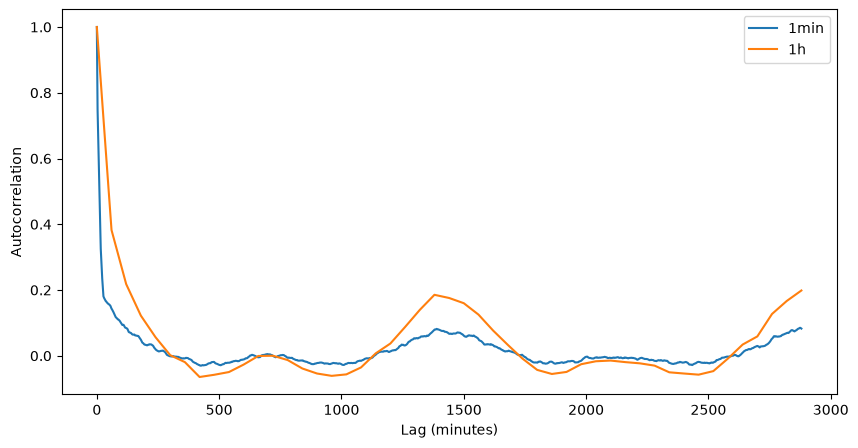

In [65]:

fig, ax = plt.subplots(figsize=(10, 5))

for freq in ["1min", "1h"]:
    selected =data_auto.xs(
        ("run_006812", freq, 2, False, "Electricity Load"),
        level=("run_id", "freq", "offday", "resid", "variable"),
    ).sort_index()

    ax.plot(
        selected.loc["SFH"].index,
        selected["r"],
        label=freq,
    )

ax.set_xlabel("Lag (minutes)")
ax.set_ylabel("Autocorrelation")
ax.legend()
plt.show()